# RespCCT and FreqCCT: full code

Single notebook for the study *RespCCT and FreqCCT: Lightweight and Explainable Convolutional Transformers for Multi-Class Respiratory Disease Classification*.

| Part | Content |
|---|---|
| 1 | Configuration, library, data, tuning, RespCCT and FreqCCT (five folds, three seeds), pretrained baselines, ablations |
| 2 | CCT-M and CCT-L with and without distillation, ensemble |
| 3 | ONNX export and timing, confusion matrices, curves, occlusion and Shapley attribution |

Run on Google Colab (T4 for training, CPU for timing). Set the paths in the configuration cell of Part 1 and of Part 3.

In [ ]:
# Record the library versions of this session (the original runs used the Colab defaults of the time).
import sys, importlib
print("python", sys.version.split()[0])
for m in ["torch", "torchvision", "timm", "numpy", "pandas", "scipy", "sklearn", "librosa", "onnx", "onnxruntime", "shap"]:
    try: print(m, importlib.import_module(m).__version__)
    except Exception as e: print(m, "not installed")

# RespCCT and FreqCCT: training and evaluation

Part 1 tunes and trains RespCCT and FreqCCT, the pretrained baselines and the ablations, five folds and three seeds for the proposed models. Part 2 trains the larger CCT variants with and without distillation. Run the cells in order.


## 0. Configuration and run folder

In [1]:
# CELL 0 | Configuration, run folder, freshness. Run first in every session.
# Everything is written under ROOT/runs/<RUN_ID>/. A new RUN_ID means nothing from an earlier run is ever read.
import os, sys, json, time, shutil, hashlib, datetime, warnings, importlib, platform
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
try: from IPython.display import display
except Exception: display = print
SMOKE = os.environ.get("BSPC_SMOKE") == "1"          # developer self-check on synthetic data; leave unset in Colab

# ================= EDIT ONLY THIS BLOCK =================
FRESH = False             # True: start a brand-new run folder (new RUN_ID). Restart the runtime first if a run is already active.
RUN_ID = ""               # "": continue the run named in LATEST.txt (or create the first one). Or type an existing id to resume it.
TUNING_DEPTH = "standard" # "standard" (20 + 10 trials per model, top 3 confirmed) | "lean" (12 + 6 trials, top 2 confirmed)
FREQCCT_CAP = "own"       # cost cap while tuning FreqCCT: "own" = its current 83.0 MFLOPs | "cct" = the CCT's 124.2 MFLOPs
# ---- v2 switches (defaults give the plan agreed for the paper) ----
TUNE_PROTOCOL = "frame"   # "frame": tuning inside the training frames of fold 0 (same protocol as the headline numbers) | "patient": v1 patient-grouped inner split
RUN_PATIENT = False       # True: also run the patient-disjoint phase G (cell 8 second loop, Table 10). Off: not part of this paper.
FUSION_MODELS = ("cct", "freqcct")   # models that get the view-fusion search in cell 8a; () skips the cell
FINAL_SEEDS = (0, 1, 2)   # seeds x 5 folds are run for the headline model only
# =========================================================

TUNE = {"standard": dict(s1=20, s2=10, top=3), "lean": dict(s1=12, s2=6, top=2)}[TUNING_DEPTH]
MAX_EPOCHS = 2 if SMOKE else 100
if SMOKE: TUNE = dict(s1=2, s2=2, top=1)

if SMOKE:
    ROOT = "/tmp/bspc_smoke_root"
    if "RUN_DIR" not in globals(): shutil.rmtree(ROOT, ignore_errors=True)
    BASE = None
else:
    if not os.path.exists("/content/drive/MyDrive"):
        from google.colab import drive; drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/Data"
    ROOT = os.path.join(BASE, "RespCCT_BSPC")
    OLD_PROJECT = os.path.join(BASE, "SeedPaper_CCT")      # existing feature files (read only); outputs never go there
    FEAT_SRC = os.path.join(OLD_PROJECT, "features")
    LEGACY_SRC = os.path.join(OLD_PROJECT, "finetune_v2")  # old summary CSVs, copied once to legacy_v2/ for the supplementary table
os.makedirs(os.path.join(ROOT, "runs"), exist_ok=True)

latest = os.path.join(ROOT, "LATEST.txt")
if "RUN_DIR" in globals():
    print(f"A run is already active in this session ({RUN_ID}); FRESH is ignored. Restart the runtime to start another run.")
else:
    if not RUN_ID:
        if FRESH or not os.path.exists(latest): RUN_ID = "run_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
        else: RUN_ID = open(latest).read().strip()
    RUN_DIR = os.path.join(ROOT, "runs", RUN_ID)
    NEW_RUN = not os.path.exists(os.path.join(RUN_DIR, "run_config.json"))
    for d in ("trials", "tables", "figures", "tuning", "configs", "logs", "code"): os.makedirs(os.path.join(RUN_DIR, d), exist_ok=True)
    open(latest, "w").write(RUN_ID)
    if NEW_RUN:
        json.dump(dict(run_id=RUN_ID, created=datetime.datetime.now().isoformat(timespec="seconds"), tuning_depth=TUNING_DEPTH, tune_protocol=TUNE_PROTOCOL, run_patient=RUN_PATIENT, fusion_models=list(FUSION_MODELS), final_seeds=list(FINAL_SEEDS),
                       tune=TUNE, freqcct_cap=FREQCCT_CAP, python=platform.python_version()),
                  open(os.path.join(RUN_DIR, "run_config.json"), "w"), indent=2)
    RUN_START = datetime.datetime.fromisoformat(json.load(open(os.path.join(RUN_DIR, "run_config.json")))["created"]).timestamp()
    if not SMOKE and NEW_RUN and os.path.isdir(LEGACY_SRC):          # keep the old results for the supplementary table only
        ld = os.path.join(ROOT, "legacy_v2"); os.makedirs(ld, exist_ok=True)
        for f in os.listdir(LEGACY_SRC):
            if f.endswith(".csv") and not os.path.exists(os.path.join(ld, f)): shutil.copy(os.path.join(LEGACY_SRC, f), ld)
print(f"{'NEW' if NEW_RUN else 'RESUMING'} run {RUN_ID}\n   folder: {RUN_DIR}\n   tuning depth: {TUNING_DEPTH} {TUNE} | tuning split: {TUNE_PROTOCOL} | patient phase: {RUN_PATIENT} | max epochs {MAX_EPOCHS} | patience 12")

def save_table(df, name, show=True, index=False):
    p = os.path.join(RUN_DIR, "tables", name + ".csv"); df.to_csv(p, index=index)
    if show:
        print(f"\n[{name}]  saved: tables/{name}.csv"); display(df)
    return p

def save_fig(fig, name, show=True):
    import matplotlib.pyplot as plt
    for ext in ("png", "pdf", "svg"):
        fig.savefig(os.path.join(RUN_DIR, "figures", f"{name}.{ext}"), dpi=300 if ext == "png" else None, bbox_inches="tight")
    if show: plt.show()
    plt.close(fig)


Mounted at /content/drive
RESUMING run run_20261022_070616
   folder: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616
   tuning depth: standard {'s1': 20, 's2': 10, 'top': 3} | tuning split: frame | patient phase: False | max epochs 100 | patience 12


## 1. Model and training library

In [2]:
# CELL 1 | Model and training library. Written into the run folder so the exact code of this run is kept with its results.
LIB_SRC = r'''# bspc_lib.py : models, metrics, training engine (checkpoint + resume), explanation helpers.
# Written by notebook cell 3. Everything the notebook trains or explains goes through this file.
import os, json, time, copy, math, hashlib, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score, matthews_corrcoef, balanced_accuracy_score, confusion_matrix

NC = 7
CLASSES = ["COPD", "Healthy", "Asthma", "Pneumonia", "URTI", "Bronchiectasis", "Bronchiolitis"]
LIB_HASH = hashlib.sha1(open(__file__, "rb").read()).hexdigest()[:10] if "__file__" in globals() else "nofile"
DATA_FP = "unset"          # set by the notebook: fingerprint of the feature files

# ======================= models =======================
class DropPath(nn.Module):
    def __init__(self, p=0.0): super().__init__(); self.p = float(p)
    def forward(self, x):
        if not self.training or self.p == 0.0: return x
        keep = 1.0 - self.p
        return x * (torch.rand(x.shape[0], 1, 1, device=x.device) < keep).to(x.dtype) / keep

class ConvTokenizer(nn.Module):
    """Two conv blocks (3x3 conv, ReLU, max-pool 3/2/1). dw=True: second conv = depthwise 3x3 + pointwise 1x1."""
    def __init__(self, c=3, e=64, dw=False):
        super().__init__()
        conv2 = nn.Sequential(nn.Conv2d(e, e, 3, 1, 1, groups=e), nn.Conv2d(e, e, 1)) if dw else nn.Conv2d(e, e, 3, 1, 1)
        self.net = nn.Sequential(nn.Conv2d(c, e, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(3, 2, 1),
                                 conv2, nn.ReLU(), nn.MaxPool2d(3, 2, 1))
    def forward(self, x): return self.net(x).flatten(2).transpose(1, 2)       # (B, nf*nt, e), frequency-major

class Block(nn.Module):
    def __init__(self, e, h, r=2, mlp_drop=0.0, attn_drop=0.0, dp=0.0, use_attn=True):
        super().__init__()
        self.use_attn = use_attn; hid = int(round(e * r))
        self.n1, self.n2 = nn.LayerNorm(e), nn.LayerNorm(e)
        if use_attn: self.attn = nn.MultiheadAttention(e, h, dropout=attn_drop, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(e, hid), nn.GELU(), nn.Dropout(mlp_drop), nn.Linear(hid, e), nn.Dropout(mlp_drop))
        self.dp = DropPath(dp); self.keep_attn, self.last_attn = False, None
    def forward(self, x):
        if not self.use_attn: return x + self.dp(self.mlp(self.n2(x)))          # capacity-matched control: no token mixing
        h = self.n1(x)
        if self.keep_attn:
            a, w = self.attn(h, h, h, need_weights=True, average_attn_weights=True); self.last_attn = w
        else:
            a = self.attn(h, h, h, need_weights=False)[0]
        x = x + self.dp(a)
        return x + self.dp(self.mlp(self.n2(x)))

def _blocks(e, layers, heads, ratio, mlp_drop, attn_drop, sd, use_attn=True):
    return nn.ModuleList([Block(e, heads, ratio, mlp_drop, attn_drop, sd * i / max(layers - 1, 1), use_attn) for i in range(layers)])

class ViewFusion(nn.Module):
    """Optional input stage over the 3 views (mel, CQT, MFCC). mode: norm = per-view standardisation per frame | stem = grouped conv
       (one small filter bank per view, residual) | se = squeeze-and-excitation gate over the views (weights kept in last_gate).
       view_drop: probability of zeroing one whole view per frame during training (never all of them)."""
    def __init__(self, c=3, mode=None, view_drop=0.0):
        super().__init__(); self.mode, self.vd, self.last_gate = mode, float(view_drop), None
        if mode == "stem": self.g1, self.g2 = nn.Conv2d(c, 4 * c, 3, padding=1, groups=c), nn.Conv2d(4 * c, c, 1)
        if mode == "se": self.fc = nn.Sequential(nn.Linear(c, 8), nn.ReLU(), nn.Linear(8, c))
    def gate(self, x): return torch.sigmoid(self.fc(x.mean((2, 3))))
    def forward(self, x):
        if self.training and self.vd > 0 and x.shape[1] > 1:
            keep = (torch.rand(x.shape[0], x.shape[1], 1, 1, device=x.device) >= self.vd).to(x.dtype)
            keep[keep.sum(1).view(-1) == 0] = 1.0; x = x * keep
        if self.mode == "norm": x = (x - x.mean((2, 3), keepdim=True)) / (x.std((2, 3), keepdim=True) + 1e-4)
        elif self.mode == "stem": x = x + self.g2(F.relu(self.g1(x)))
        elif self.mode == "se": g = self.gate(x); self.last_gate = g.detach(); x = x * (2.0 * g)[:, :, None, None]
        return x

def make_fuse(c, mode, vd):
    return ViewFusion(c, mode, vd) if (mode or vd > 0) else None

class CCT(nn.Module):
    """Compact convolutional transformer: tokenizer, encoder, SeqPool. pe=True adds a learned positional embedding."""
    def __init__(self, nc=NC, e=64, layers=4, heads=4, ratio=2, mlp_drop=0., attn_drop=0., sd=0., pe=False, dw=False, nf=16, nt=10, c=3,
                 attn=True, pool="seq", fusion=None, view_drop=0.0):
        super().__init__()
        self.nf, self.nt, self.kind, self.pooling = nf, nt, "cct", pool
        self.fuse = make_fuse(c, fusion, view_drop)
        self.tok = ConvTokenizer(c, e, dw)
        self.pos = None
        if pe: self.pos = nn.Parameter(torch.zeros(1, nf * nt, e)); nn.init.trunc_normal_(self.pos, std=0.02)
        self.cls = nn.Parameter(torch.zeros(1, 1, e)) if pool == "cls" else None
        self.blocks = _blocks(e, layers, heads, ratio, mlp_drop, attn_drop, sd, attn)
        self.pool = nn.Linear(e, 1) if pool == "seq" else None
        self.fc = nn.Linear(e, nc)
    def encode(self, x, perm=None):
        if self.fuse is not None: x = self.fuse(x)
        z = self.tok(x)
        if perm is not None: z = z[:, perm]
        if self.pos is not None: z = z + self.pos
        if self.cls is not None: z = torch.cat([self.cls.expand(z.shape[0], -1, -1), z], 1)
        for b in self.blocks: z = b(z)
        return z
    def forward(self, x, perm=None, ret_pool=False, ret_emb=False):
        z = self.encode(x, perm)
        if self.pooling == "seq":
            w = torch.softmax(self.pool(z), dim=1); emb = (w.transpose(1, 2) @ z).squeeze(1)
        elif self.pooling == "mean": w = torch.full(z.shape[:2] + (1,), 1.0 / z.shape[1], device=z.device); emb = z.mean(1)
        else: w = torch.zeros(z.shape[0], z.shape[1], 1, device=z.device); emb = z[:, 0]
        out = self.fc(emb)
        if ret_emb: return out, emb
        return (out, w.squeeze(-1)) if ret_pool else out
    @torch.no_grad()
    def contributions(self, x, target):
        """Exact additive contribution of every final token to the target logit (bias excluded): w_t * (W_c . z_t)."""
        assert self.pooling in ("seq", "mean"), "token contributions are defined for SeqPool and mean pooling only"
        z = self.encode(x)
        w = torch.softmax(self.pool(z), dim=1).squeeze(-1) if self.pooling == "seq" else torch.full(z.shape[:2], 1.0 / z.shape[1], device=z.device)
        Wc = self.fc.weight[target]                                     # (B, e)
        return (w * torch.einsum("bte,be->bt", z, Wc)).view(-1, self.nf, self.nt)

class FreqCCT(nn.Module):
    """dw: depthwise-separable 2nd tokenizer conv. pe: learned positional embedding. fp: frequency-preserving head
       (LayerNorm, pool over time, keep nf rows, linear nf*e -> classes) else SeqPool. tpool: 'mean' or 'attn' (learned weights over time)."""
    def __init__(self, nc=NC, e=64, layers=4, heads=4, ratio=2, mlp_drop=0., attn_drop=0., sd=0., dw=True, pe=True, fp=True,
                 tpool="mean", nf=16, nt=10, c=3, attn=True, fusion=None, view_drop=0.0):
        super().__init__()
        self.nf, self.nt, self.fp, self.tpool, self.kind = nf, nt, fp, tpool, "freqcct"
        self.fuse = make_fuse(c, fusion, view_drop)
        self.tok = ConvTokenizer(c, e, dw)
        self.pos = None
        if pe: self.pos = nn.Parameter(torch.zeros(1, nf * nt, e)); nn.init.trunc_normal_(self.pos, std=0.02)
        self.blocks = _blocks(e, layers, heads, ratio, mlp_drop, attn_drop, sd, attn)
        if fp:
            self.norm = nn.LayerNorm(e); self.fc = nn.Linear(nf * e, nc)
            if tpool == "attn": self.tp = nn.Linear(e, 1)
        else:
            self.pool = nn.Linear(e, 1); self.fc = nn.Linear(e, nc)
    def encode(self, x, perm=None):
        if self.fuse is not None: x = self.fuse(x)
        z = self.tok(x)
        if perm is not None: z = z[:, perm]                             # shuffle content BEFORE position is added
        if self.pos is not None: z = z + self.pos
        for b in self.blocks: z = b(z)
        return z
    def _rows(self, z):
        h = self.norm(z).view(z.shape[0], self.nf, self.nt, -1)
        if self.tpool == "attn":
            a = torch.softmax(self.tp(h).squeeze(-1), dim=2)             # (B, nf, nt)
            return (h * a.unsqueeze(-1)).sum(2), a
        return h.mean(2), None
    def forward(self, x, perm=None, ret_pool=False, ret_emb=False):
        z = self.encode(x, perm)
        if self.fp:
            r, a = self._rows(z); emb = r.flatten(1); out = self.fc(emb); w = None if a is None else a.flatten(1)
        else:
            w = torch.softmax(self.pool(z), dim=1); emb = (w.transpose(1, 2) @ z).squeeze(1); out = self.fc(emb); w = w.squeeze(-1)
        if ret_emb: return out, emb
        return (out, w) if ret_pool else out
    @torch.no_grad()
    def contributions(self, x, target):
        z = self.encode(x)
        if not self.fp:
            w = torch.softmax(self.pool(z), dim=1).squeeze(-1)
            return (w * torch.einsum("bte,be->bt", z, self.fc.weight[target])).view(-1, self.nf, self.nt)
        h = self.norm(z).view(z.shape[0], self.nf, self.nt, -1)
        Wc = self.fc.weight[target].view(-1, self.nf, 1, h.shape[-1])    # (B, nf, 1, e)
        if self.tpool == "attn": w = torch.softmax(self.tp(h).squeeze(-1), dim=2)
        else: w = torch.full(h.shape[:3], 1.0 / self.nt, device=x.device)
        return w * (h * Wc).sum(-1)

BASELINES = {"shufflenet05": "ShuffleNetV2 x0.5", "mnasnet05": "MNASNet 0.5", "mobilenetv3s": "MobileNetV3-Small", "mobilevitxxs": "MobileViT-XXS",
             "effnetb0": "EfficientNet-B0", "resnet18": "ResNet-18"}

class Pretrained(nn.Module):
    """ImageNet-pretrained torchvision backbone, 7-class linear head. Input (B,3,64,40) in [0,1]: ImageNet normalisation,
       bilinear upscaling by `scale`, then the backbone."""
    def __init__(self, name, scale=2, pretrained=True, nc=NC):
        super().__init__()
        import torchvision.models as tv
        self.scale, self.kind = scale, name
        W = (lambda enum: enum.DEFAULT if pretrained else None)
        if name == "shufflenet05":
            m = tv.shufflenet_v2_x0_5(weights=W(tv.ShuffleNet_V2_X0_5_Weights)); m.fc = nn.Linear(m.fc.in_features, nc)
        elif name == "mnasnet05":
            m = tv.mnasnet0_5(weights=W(tv.MNASNet0_5_Weights)); m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, nc)
        elif name == "mobilenetv3s":
            m = tv.mobilenet_v3_small(weights=W(tv.MobileNet_V3_Small_Weights)); m.classifier = nn.Linear(576, nc)
        elif name == "mobilevitxxs":                                  # timm, ImageNet-1k pretrained, 7-class linear head
            import timm
            m = timm.create_model("mobilevit_xxs", pretrained=pretrained, num_classes=nc)
        elif name == "effnetb0":
            m = tv.efficientnet_b0(weights=W(tv.EfficientNet_B0_Weights)); m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, nc)
        elif name == "resnet18":
            m = tv.resnet18(weights=W(tv.ResNet18_Weights)); m.fc = nn.Linear(m.fc.in_features, nc)
        else: raise ValueError(name)
        self.m = m
        mu, sd = ([0., 0., 0.], [1., 1., 1.]) if name == "mobilevitxxs" else ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # MobileViT is trained on [0,1] input
        self.register_buffer("mu", torch.tensor(mu).view(1, 3, 1, 1)); self.register_buffer("sd", torch.tensor(sd).view(1, 3, 1, 1))
    def forward(self, x, **kw):
        x = (x - self.mu) / self.sd
        if self.scale != 1: x = F.interpolate(x, scale_factor=self.scale, mode="bilinear", align_corners=False)
        return self.m(x)

def n_rows_of(spec): return 16 if spec.get("rows") is None else len(spec["rows"])
def n_channels_of(spec): return 3 if spec.get("channels") is None else len(spec["channels"])

def build_model(spec):
    a = spec["arch"]; g = lambda k, d: spec.get(k, d)
    kw = dict(e=g("e", 64), layers=g("layers", 4), heads=g("heads", 4), ratio=g("ratio", 2), mlp_drop=g("mlp_drop", 0.),
              attn_drop=g("attn_drop", 0.), sd=g("sd", 0.), nf=n_rows_of(spec), c=n_channels_of(spec))
    kw.update(attn=g("attn", True), fusion=g("fusion", None), view_drop=g("view_drop", 0.0))
    if a == "cct": return CCT(pe=g("pe", False), dw=g("dw", False), pool=g("pool", "seq"), **kw)
    if a == "freqcct": return FreqCCT(dw=g("dw", True), pe=g("pe", True), fp=g("fp", True), tpool=g("tpool", "mean"), **kw)
    if a in BASELINES: return Pretrained(a, scale=g("scale", 2), pretrained=g("pretrained", True))
    raise ValueError(a)

def n_params(m): return int(sum(p.numel() for p in m.parameters()))

def match_ratio(spec, target_params, grid=None):
    """FFN ratio of the attention-free control (spec with attn=False) whose parameter count is closest to target_params."""
    grid = np.arange(1.0, 12.0, 0.05) if grid is None else grid
    best = min(grid, key=lambda r: abs(n_params(build_model({**spec, "attn": False, "ratio": float(r)})) - target_params))
    return float(round(best, 2))

def analytic_mflops(arch="cct", e=64, layers=4, ratio=2, nf=16, nt=10, c=3, nc=NC, dw=None, fp=None, tpool="mean", **_):
    """2 x multiply-accumulates per frame (attention included), CCT family. Reproduces 124.2 (CCT) and 83.0 (FreqCCT)."""
    dw = (arch == "freqcct") if dw is None else dw; fp = (arch == "freqcct") if fp is None else fp
    H, W = 4 * nf, 4 * nt; n = nf * nt
    conv1 = H * W * c * e * 9
    conv2 = (H // 2) * (W // 2) * ((e * 9 + e * e) if dw else e * e * 9)
    attn = layers * (n * e * 3 * e + 2 * n * n * e + n * e * e)
    mlp = layers * (2 * n * e * e * ratio)
    head = nf * e * nc + (n * e if tpool == "attn" else 0) if fp else n * e + e * nc
    return 2.0 * (conv1 + conv2 + attn + mlp + head) / 1e6

def spec_mflops(spec):
    if spec["arch"] not in ("cct", "freqcct"): return float("nan")
    return analytic_mflops(spec["arch"], e=spec.get("e", 64), layers=spec.get("layers", 4), ratio=spec.get("ratio", 2),
                           nf=n_rows_of(spec), c=n_channels_of(spec), dw=spec.get("dw"), fp=spec.get("fp"), tpool=spec.get("tpool", "mean"))

def counted_mflops(model, shape):
    """torch FlopCounterMode on a CPU copy in train mode with keep_attn=True (the fused eval path is invisible to the counter)."""
    try:
        from torch.utils.flop_counter import FlopCounterMode
        m = copy.deepcopy(model).cpu().train()
        for b in getattr(m, "blocks", []):
            b.dp.p = 0.0
            if getattr(b, "use_attn", True): b.keep_attn = True; b.attn.dropout = 0.0
        with torch.no_grad(), FlopCounterMode(display=False) as fc: m(torch.zeros(1, *shape))
        return fc.get_total_flops() / 1e6
    except Exception as ex:
        return float("nan")

@torch.no_grad()
def cpu_latency_ms(model, shape, warm=30, reps=200):
    m = copy.deepcopy(model).cpu().eval(); x = torch.zeros(1, *shape)
    for _ in range(warm): m(x)
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); m(x); ts.append((time.perf_counter() - t) * 1e3)
    return float(np.median(ts)), float(np.percentile(ts, 90))

def peak_activation_kb(model, shape):
    m = copy.deepcopy(model).cpu().eval(); sizes = []
    hs = [mod.register_forward_hook(lambda mod_, i, o: sizes.append(o.numel() if torch.is_tensor(o) else 0))
          for mod in m.modules() if len(list(mod.children())) == 0]
    with torch.no_grad(): m(torch.zeros(1, *shape))
    for h in hs: h.remove()
    big = max(sizes) if sizes else 0
    if hasattr(m, "blocks") and len(m.blocks) and getattr(m.blocks[0], "use_attn", True): n = m.nf * m.nt; big = max(big, m.blocks[0].attn.num_heads * n * n)
    return 4.0 * big / 1e3

# ======================= metrics =======================
def macro_f1_present(y, p):
    labs = np.unique(y)
    return float(f1_score(y, p, labels=labs, average="macro", zero_division=0))

def scores(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return dict(accuracy=float((y == p).mean()), macro_f1=macro_f1_present(y, p),
                macro_f1_all7=float(f1_score(y, p, labels=list(range(NC)), average="macro", zero_division=0)),
                bal_acc=float(balanced_accuracy_score(y, p)), mcc=float(matthews_corrcoef(y, p)),
                majority_acc=float(np.bincount(y, minlength=NC).max() / len(y)), n_classes=int(len(np.unique(y))), n=int(len(y)))

def per_class(y, p):
    cm = confusion_matrix(y, p, labels=list(range(NC))); N = cm.sum(); rows = []
    for c, name in enumerate(CLASSES):
        TP = cm[c, c]; FN = cm[c].sum() - TP; FP = cm[:, c].sum() - TP; TN = N - TP - FN - FP
        rc, sp, pr = TP / max(TP + FN, 1), TN / max(TN + FP, 1), TP / max(TP + FP, 1)
        rows.append(dict(cls=name, n=int(cm[c].sum()), precision=float(pr), recall=float(rc), specificity=float(sp),
                         f1=float(2 * pr * rc / max(pr + rc, 1e-9))))
    return cm, rows

def rec_vote(P, y, rec):
    df = pd.DataFrame(np.asarray(P)); cols = list(df.columns); df["rec"] = np.asarray(rec); df["y"] = np.asarray(y)
    g = df.groupby("rec", sort=True)
    return g[cols].mean().values, g["y"].first().values.astype(int), np.array(list(g.groups.keys()))

def bootstrap_diff(y, pa, pb, groups, B=2000, seed=0, metric="macro_f1"):
    """Paired percentile CI of metric(pa) - metric(pb), resampling whole groups (recordings)."""
    y, pa, pb, groups = map(np.asarray, (y, pa, pb, groups))
    ug, inv = np.unique(groups, return_inverse=True); members = [np.where(inv == k)[0] for k in range(len(ug))]
    rng = np.random.default_rng(seed); d = []
    for _ in range(B):
        idx = np.concatenate([members[k] for k in rng.integers(0, len(ug), len(ug))])
        d.append(scores(y[idx], pa[idx])[metric] - scores(y[idx], pb[idx])[metric])
    d0 = scores(y, pa)[metric] - scores(y, pb)[metric]
    return float(d0), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

def mcnemar(ca, cb):
    from scipy.stats import chi2
    a, b = np.asarray(ca, bool), np.asarray(cb, bool); n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    if n01 + n10 == 0: return 0.0, 1.0, n01, n10
    s = (abs(n01 - n10) - 1) ** 2 / (n01 + n10); return float(s), float(chi2.sf(s, 1)), n01, n10

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o): run = max(run, min(1.0, (m - r) * p[i])); adj[i] = run
    return adj

def logit_adjust(P, prior_train, prior_real, tau):
    """Post-hoc prior correction: p * (pi_real / pi_train)^tau, renormalised. tau chosen on validation only."""
    A = np.asarray(P) * (np.asarray(prior_real) / np.asarray(prior_train)) ** tau
    return A / A.sum(1, keepdims=True)

# ======================= splits =======================
def make_splits(M, y, seed=42):
    """Returns dict with 'paper' (list of 5 (train,val,test)) and 'patient' (list of 5) plus 'tune'.
       paper  : stratified 5-fold over pooled frames (reference protocol); val = 10% of train, stratified; test = real frames of the fold.
       patient: StratifiedGroupKFold by patient key over real frames; augmented copies follow their patient;
                val = real frames of 10% of the training patients; test = real frames of the test patients.
       tune   : inside the TRAINING patients of patient fold 0 only: inner validation = real frames of ~20% of those patients."""
    from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GroupShuffleSplit, train_test_split
    aug = M["aug"].values; pk = M["pkey"].values; out = {"paper": [], "patient": []}
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(np.zeros(len(y)), y):
        tri, vai = train_test_split(tr, test_size=0.10, stratify=y[tr], random_state=seed)
        out["paper"].append((tri, vai, te[aug[te] == 0]))
    real = np.where(aug == 0)[0]
    fold_of_pk = {}
    for f, (a, b) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(real, y[real], groups=pk[real])):
        for k in np.unique(pk[real[b]]): fold_of_pk[k] = f
    fold = np.array([fold_of_pk.get(k, -1) for k in pk])
    for f in range(5):
        tr = np.where(fold != f)[0]; te = np.where((fold == f) & (aug == 0))[0]
        a, b = next(GroupShuffleSplit(1, test_size=0.10, random_state=seed).split(tr, groups=pk[tr]))
        tri, vai = tr[a], tr[b]; vai = vai[aug[vai] == 0]
        out["patient"].append((tri, vai, te))
    tr0 = np.where(fold != 0)[0]; r0 = tr0[aug[tr0] == 0]
    sg = next(StratifiedGroupKFold(5, shuffle=True, random_state=7).split(r0, y[r0], groups=pk[r0]))
    val_pk = np.unique(pk[r0[sg[1]]])
    in_val = np.isin(pk[tr0], val_pk)
    out["tune"] = (tr0[~in_val], tr0[in_val & (aug[tr0] == 0)], None)
    out["fold_of_frame"] = fold
    # tune_frame: frame-level protocol (no patient grouping). Inside the TRAINING frames of paper fold 0: 85 % inner train, 15 % inner validation (real frames only).
    tr0, va0, _ = out["paper"][0]; pool_ = np.concatenate([tr0, va0])
    a_, b_ = train_test_split(pool_, test_size=0.15, stratify=y[pool_], random_state=7)
    out["tune_frame"] = (a_, b_[aug[b_] == 0], None)
    return out

# ======================= augmentation on the GPU =======================
def spec_augment(x, fmax, tmax, n=2):
    B, C, H, W = x.shape
    for dim, mx, size in ((2, fmax, H), (3, tmax, W)):
        if mx <= 0: continue
        ar = torch.arange(size, device=x.device)[None]
        for _ in range(n):
            w = torch.randint(0, mx + 1, (B, 1), device=x.device); s = (torch.rand(B, 1, device=x.device) * (size - w)).long()
            m = (ar >= s) & (ar < s + w)
            x = x.masked_fill(m[:, None, :, None] if dim == 2 else m[:, None, None, :], 0.0)
    return x

def prep(x, spec):
    if spec.get("channels") is not None: x = x[:, spec["channels"]]
    if spec.get("rows") is not None:
        r = torch.as_tensor(np.concatenate([np.arange(4 * k, 4 * k + 4) for k in spec["rows"]]), device=x.device); x = x[:, :, r]
    return x

# ======================= engine =======================
class Pruned(Exception): pass

def stable_hash(o): return hashlib.sha1(json.dumps(o, sort_keys=True, default=str).encode()).hexdigest()[:12]
def idx_hash(a): return hashlib.md5(np.ascontiguousarray(np.asarray(a, dtype=np.int64)).tobytes()).hexdigest()[:10] if a is not None else "none"
def _json(o, path):
    tmp = path + ".tmp"; json.dump(o, open(tmp, "w"), indent=2, default=str); os.replace(tmp, path)
def _save(o, path):
    tmp = path + ".tmp"; torch.save(o, tmp); os.replace(tmp, path)

DEFAULT_TRAIN = dict(lr=2e-3, wd=0.0, batch_size=128, smooth=0.1, sched="plateau", fmask=0, tmask=0, mixup=0.0, ema=0.0,
                     max_epochs=100, patience=12, clip=1.0, seed=0, mlp_drop=0.0, attn_drop=0.0, sd=0.0, balance=False)

@torch.no_grad()
def predict_probs(model, X, idx, spec, device, bs=2048, use_amp=False):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        xb = prep(X[torch.as_tensor(idx[i:i + bs], device=device)].float(), spec)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out.append(F.softmax(model(xb).float(), 1).cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, NC), np.float32)

def _eval(model, X, y, idx, spec, device, use_amp):
    P = predict_probs(model, X, idx, spec, device, use_amp=use_amp); yt = y[idx]
    return P, float(-np.log(P[np.arange(len(yt)), yt] + 1e-9).mean()), float((P.argmax(1) == yt).mean()), macro_f1_present(yt, P.argmax(1))

def train_run(spec, X, y, idx, out_dir, device, evaluate_test=False, meta=None, report=None, log=print, hist_every=5):
    """Train one model. Files in out_dir: config.json status.json history.csv last.pt best.pt preds.npz metrics.json time.json.
       Resumes from last.pt when config.json matches (same settings, same data, same library); refuses to mix otherwise."""
    S = {**DEFAULT_TRAIN, **spec}; os.makedirs(out_dir, exist_ok=True)
    cfg = dict(spec=S, train=idx_hash(idx["train"]), val=idx_hash(idx["val"]), test=idx_hash(idx.get("test")), lib=LIB_HASH, data=DATA_FP)
    cfg["hash"] = stable_hash(cfg)
    cpath, spath = os.path.join(out_dir, "config.json"), os.path.join(out_dir, "status.json")
    if os.path.exists(cpath):
        old = json.load(open(cpath))
        if old.get("hash") != cfg["hash"]:
            raise RuntimeError(f"{out_dir} holds a run with different settings/data/code ({old.get('hash')} vs {cfg['hash']}). "
                               f"Set FRESH=True in cell 0 for a new run folder; nothing is overwritten silently.")
    else: _json(cfg, cpath)
    st = json.load(open(spath)) if os.path.exists(spath) else {}
    if st.get("state") == "done" and os.path.exists(os.path.join(out_dir, "metrics.json")):
        return json.load(open(os.path.join(out_dir, "metrics.json")))
    use_amp = device.type == "cuda"
    torch.manual_seed(42 + S["seed"]); np.random.seed(42 + S["seed"])
    model = build_model(S).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=S["lr"], weight_decay=S["wd"])
    if S["sched"] == "plateau": sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    else:
        sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda ep: (ep + 1) / 3 if ep < 3 else max(0.01, 0.5 * (1 + math.cos(math.pi * min(1.0, (ep - 3) / 57)))))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ema = None
    if S["ema"] > 0: ema = copy.deepcopy(model).eval(); [p.requires_grad_(False) for p in ema.parameters()]
    hist, best, best_ep, bad, ep0, elapsed, steps = [], float("inf"), 0, 0, 0, 0.0, 0
    lp = os.path.join(out_dir, "last.pt")
    if os.path.exists(lp):
        ck = torch.load(lp, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sch.load_state_dict(ck["sch"]); scaler.load_state_dict(ck["scaler"])
        if ema is not None and ck.get("ema") is not None: ema.load_state_dict(ck["ema"])
        hist, best, best_ep, bad, ep0, elapsed, steps = ck["hist"], ck["best"], ck["best_ep"], ck["bad"], ck["epoch"], ck["elapsed"], ck["steps"]
        torch.set_rng_state(ck["rng"].cpu()); log(f"    resumed from epoch {ep0}")
    tr = torch.as_tensor(idx["train"], device=device); va = idx["val"]; yg = torch.as_tensor(y, device=device).long()
    cw = (1.0 / torch.bincount(yg[tr], minlength=NC).float().clamp(min=1)) if S["balance"] else None
    gpu = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"
    _json({**st, "state": "running", "epoch": ep0}, spath)
    stopped = False
    if bad >= S["patience"] or ep0 >= S["max_epochs"]: ep0 = S["max_epochs"]       # nothing left to train
    for ep in range(ep0, S["max_epochs"]):
        t0 = time.time(); model.train(); perm = tr[torch.randperm(len(tr), device=device)] if not S["balance"] else tr[torch.multinomial(cw[yg[tr]], len(tr), replacement=True)]; tot, corr = 0.0, 0
        for i in range(0, len(perm), S["batch_size"]):
            b = perm[i:i + S["batch_size"]]; xb = prep(X[b].float(), S); yb = yg[b]
            if S["fmask"] or S["tmask"]: xb = spec_augment(xb, S["fmask"], S["tmask"])
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                if S["mixup"] > 0:
                    lam = float(np.random.beta(S["mixup"], S["mixup"])); pi = torch.randperm(len(b), device=device)
                    out = model(lam * xb + (1 - lam) * xb[pi])
                    loss = lam * F.cross_entropy(out.float(), yb, label_smoothing=S["smooth"]) + (1 - lam) * F.cross_entropy(out.float(), yb[pi], label_smoothing=S["smooth"])
                else:
                    out = model(xb); loss = F.cross_entropy(out.float(), yb, label_smoothing=S["smooth"])
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            if S["clip"]: nn.utils.clip_grad_norm_(model.parameters(), S["clip"])
            scaler.step(opt); scaler.update(); steps += 1
            if ema is not None:
                d = min(S["ema"], (1 + steps) / (10 + steps))
                with torch.no_grad():
                    for pe_, pm in zip(ema.parameters(), model.parameters()): pe_.mul_(d).add_(pm.detach(), alpha=1 - d)
                    for be, bm in zip(ema.buffers(), model.buffers()): be.copy_(bm)
            tot += loss.item() * len(b); corr += (out.argmax(1) == yb).sum().item()
        em = ema if ema is not None else model
        _, vl, vacc, vf1 = _eval(em, X, y, va, S, device, use_amp)
        lr_now = opt.param_groups[0]["lr"]
        if S["sched"] == "plateau": sch.step(vl)
        else: sch.step()
        dt = time.time() - t0; elapsed += dt
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(perm), train_acc=corr / len(perm), val_loss=vl, val_acc=vacc, val_macro_f1=vf1, lr=lr_now, seconds=dt))
        if vl < best - 1e-4:
            best, best_ep, bad = vl, ep + 1, 0; _save(copy.deepcopy(em.state_dict()), os.path.join(out_dir, "best.pt"))
        else: bad += 1
        _save(dict(model=model.state_dict(), opt=opt.state_dict(), sch=sch.state_dict(), scaler=scaler.state_dict(),
                   ema=None if ema is None else ema.state_dict(), hist=hist, best=best, best_ep=best_ep, bad=bad, epoch=ep + 1,
                   elapsed=elapsed, steps=steps, rng=torch.get_rng_state()), lp)
        pd.DataFrame(hist).to_csv(os.path.join(out_dir, "history.csv"), index=False)
        _json({"state": "running", "epoch": ep + 1}, spath)
        if ep == 0 or (ep + 1) % hist_every == 0:
            log(f"    epoch {ep+1:3d} ({dt:.0f}s) lr {lr_now:.5f} | train loss {tot/len(perm):.3f} acc {corr/len(perm):.3f} | val loss {vl:.3f} acc {vacc:.3f} F1 {vf1:.3f}")
        if report is not None:
            try: report(ep + 1, vf1, vl)
            except Pruned:
                _json({"state": "pruned", "epoch": ep + 1}, spath); raise
        if bad >= S["patience"]: stopped = True; log(f"    early stopping at epoch {ep+1} (best epoch {best_ep})"); break
    model.load_state_dict(torch.load(os.path.join(out_dir, "best.pt"), map_location=device)) if ema is None else ema.load_state_dict(torch.load(os.path.join(out_dir, "best.pt"), map_location=device))
    fm = ema if ema is not None else model
    Pv, vl, vacc, vf1 = _eval(fm, X, y, va, S, device, use_amp)
    shape = (n_channels_of(S), 4 * n_rows_of(S), 40)
    h = hist[best_ep - 1]
    m = dict(trial=os.path.basename(out_dir), epochs_run=len(hist), best_epoch=best_ep, early_stopped=bool(stopped),
             val_loss=vl, val_acc=vacc, val_macro_f1=vf1, params=n_params(model), mflops=counted_mflops(model, shape),
             mflops_analytic=spec_mflops(S), seconds_total=elapsed, seconds_per_epoch=float(np.mean([r["seconds"] for r in hist])),
             seconds_to_best=float(sum(r["seconds"] for r in hist[:best_ep])), minutes=elapsed / 60.0, gpu=gpu, hash=cfg["hash"])
    arrays = dict(val_idx=np.asarray(va), val_probs=Pv.astype(np.float32))
    if evaluate_test and idx.get("test") is not None:
        te = np.asarray(idx["test"]); Pt = predict_probs(fm, X, te, S, device, use_amp=use_amp); yt = y[te]; pr = Pt.argmax(1)
        sc = scores(yt, pr); cm, pcr = per_class(yt, pr)
        m.update({f"test_{k}": v for k, v in sc.items()}); m["per_class"] = pcr; m["confusion"] = cm.tolist()
        if meta is not None:
            Pr, yr, _ = rec_vote(Pt, yt, meta["rec_idx"].values[te]); sr = scores(yr, Pr.argmax(1))
            m.update({f"rec_{k}": v for k, v in sr.items()})
        arrays.update(test_idx=te, test_probs=Pt.astype(np.float32))
    np.savez_compressed(os.path.join(out_dir, "preds.npz"), **arrays)
    _json(m, os.path.join(out_dir, "metrics.json"))
    _json(dict(seconds_total=elapsed, minutes=elapsed / 60, seconds_per_epoch=m["seconds_per_epoch"], epochs=len(hist), best_epoch=best_ep,
               seconds_to_best=m["seconds_to_best"], gpu=gpu), os.path.join(out_dir, "time.json"))
    _json({"state": "done", "epoch": len(hist)}, spath)
    try: os.remove(lp)                                   # finished: the per-epoch checkpoint is no longer needed
    except OSError: pass
    return m

def load_model(spec, out_dir, device):
    S = {**DEFAULT_TRAIN, **spec}; m = build_model(S).to(device)
    m.load_state_dict(torch.load(os.path.join(out_dir, "best.pt"), map_location=device)); return m.eval()

# ======================= explanation helpers =======================
def integrated_gradients(model, x, target, steps=24, baseline=0.0, chunk=8):
    """IG with a constant baseline. x (B,C,H,W), target (B,). Returns (B,C,H,W)."""
    model.eval(); out = []
    for i in range(0, len(x), chunk):
        xb, tb = x[i:i + chunk].float(), target[i:i + chunk]; base = torch.full_like(xb, baseline); acc = torch.zeros_like(xb)
        for a in (torch.arange(steps, device=xb.device) + 0.5) / steps:
            z = (base + a * (xb - base)).requires_grad_(True)
            g, = torch.autograd.grad(model(z).gather(1, tb[:, None]).sum(), z); acc += g
        out.append(((xb - base) * acc / steps).detach())
    return torch.cat(out)

@torch.no_grad()
def attention_stack(model, x):
    for b in model.blocks: b.keep_attn = True
    model(x)
    A = [b.last_attn.clone() for b in model.blocks]
    for b in model.blocks: b.keep_attn = False
    return A                                                          # list of (B, n, n), heads averaged

@torch.no_grad()
def rollout_matrix(model, x):
    """R[b, t, j]: how much input token j reaches final token t (0.5 W + 0.5 I per layer, multiplied over layers)."""
    A = attention_stack(model, x); n = A[0].shape[-1]; I = torch.eye(n, device=x.device)
    R = I.expand(x.shape[0], n, n).clone()
    for a in A:
        a = 0.5 * a + 0.5 * I; a = a / a.sum(-1, keepdim=True); R = a @ R
    return R

@torch.no_grad()
def rollout_map(model, x, token_weights=None):
    """Attention rollout read out with token weights (default uniform). Contribution-weighted rollout passes relu(contribution)."""
    R = rollout_matrix(model, x); B, n, _ = R.shape
    w = torch.full((B, n), 1.0 / n, device=x.device) if token_weights is None else token_weights.flatten(1).clamp(min=0)
    w = w / (w.sum(1, keepdim=True) + 1e-9)
    return (w[:, None, :] @ R)[:, 0].view(B, model.nf, model.nt)

def token_to_input(m):                                                # (B,nf,nt) -> (B,1,4nf,4nt)
    return m.repeat_interleave(4, 1).repeat_interleave(4, 2)[:, None]

def input_to_token(a):                                                # (B,C,H,W) attribution -> (B,nf,nt) by |.| mean over channels, 4x4 sum
    a = a.abs().sum(1); B, H, W = a.shape
    return a.view(B, H // 4, 4, W // 4, 4).sum((2, 4))

def mel_row_centres(fmax=2000.0, n=64):
    import librosa; return librosa.mel_frequencies(n_mels=n + 2, fmin=0.0, fmax=fmax)[1:-1]
def cqt_row_centres(n=64, fmin=32.7, bpo=12): return fmin * 2.0 ** (np.arange(n) / bpo)
def token_row_hz(nf=16):
    try: mel = mel_row_centres()
    except Exception: mel = np.linspace(0, 2000, 64)
    cqt = cqt_row_centres()
    return pd.DataFrame([dict(token_row=r, mel_lo_hz=round(float(mel[4 * r])), mel_hi_hz=round(float(mel[4 * r + 3])),
                              cqt_lo_hz=round(float(cqt[4 * r]), 1), cqt_hi_hz=round(float(cqt[4 * r + 3]), 1)) for r in range(nf)])
'''
import torch
code_dir = os.path.join(RUN_DIR, "code"); lib_path = os.path.join(code_dir, "bspc_lib.py")
if not os.path.exists(lib_path) or open(lib_path).read() != LIB_SRC:
    if os.path.exists(lib_path) and any(os.scandir(os.path.join(RUN_DIR, "trials"))):
        print("Warning: the library differs from the one this run started with. Trials that already finished are kept; "
              "a trial that was interrupted will refuse to resume (its code hash no longer matches).")
    open(lib_path, "w").write(LIB_SRC)
if code_dir not in sys.path: sys.path.insert(0, code_dir)
import bspc_lib as bspc; importlib.reload(bspc)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("library hash", bspc.LIB_HASH, "| device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")


library hash 425661e596 | device: cuda Tesla T4


## 2. Data

In [3]:
# CELL 2 | Data: 3 x 64 x 40 frames (mel, CQT, MFCC), real + augmented, loaded to the GPU once.
CLASSES = bspc.CLASSES; LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
if SMOKE:                                                         # synthetic stand-in with the same columns
    rng = np.random.default_rng(0); rows = []; Xs = []
    for c in range(7):
        for p in range(12):
            for r in range(2):
                for k in range(3):
                    x = rng.random((3, 64, 40)) * 0.3; x[:, 8 * c:8 * c + 8] += 0.6
                    Xs.append(x); rows.append((c * 100 + p * 2 + r, CLASSES[c], ["ICBHI", "KAUH", "RD@TR"][p % 3], f"P{c}_{p}", 0, 0))
                    if c > 0:
                        Xs.append(np.clip(x + rng.normal(0, .05, x.shape), 0, 1)); rows.append((c * 100 + p * 2 + r, CLASSES[c], ["ICBHI", "KAUH", "RD@TR"][p % 3], f"P{c}_{p}", 0, 1))
    X = np.stack(Xs).astype(np.float16); M = pd.DataFrame(rows, columns=["rec_idx", "label", "source", "pkey", "fold", "aug"])
else:
    parts = [np.load(os.path.join(FEAT_SRC, "feat_orig.npy"))]
    mo = pd.read_csv(os.path.join(FEAT_SRC, "meta_orig.csv")); mo["aug"] = 0; metas = [mo]
    for c in CLASSES[1:]:
        p = os.path.join(FEAT_SRC, f"feat_aug_{c}.npy")
        if os.path.exists(p):
            parts.append(np.load(p)); m = pd.read_csv(os.path.join(FEAT_SRC, f"meta_aug_{c}.csv")); m["aug"] = 1; metas.append(m)
    X = np.concatenate(parts); M = pd.concat(metas, ignore_index=True); del parts
y = M["label"].map(LABEL_MAP).values.astype(np.int64)
assert len(X) == len(M), "features and metadata differ in length"
n_rec = M.loc[M["aug"] == 0, "rec_idx"].nunique()
print(f"frames {len(X)} (real {int((M.aug==0).sum())}, augmented {int((M.aug==1).sum())}) | recordings {n_rec}" + ("" if SMOKE or n_rec == 1667 else "  Warning: expected 1667"))
bspc.DATA_FP = hashlib.md5((str(X.shape) + M.to_csv(index=False)).encode()).hexdigest()[:10]
Xg = torch.from_numpy(X).to(device); del X
if device.type == "cuda": torch.cuda.empty_cache()
print("data fingerprint", bspc.DATA_FP)


frames 68859 (real 11902, augmented 56957) | recordings 1665  ⚠️ expected 1667
data fingerprint 7acb7a62b9


## 3. Splits and run helper

In [4]:
# CELL 3 | Splits. paper = reference protocol (stratified 5-fold over pooled frames). patient = StratifiedGroupKFold by patient.
# tune = inside the TRAINING patients of patient fold 0 only; the test frames of every split are untouched until a model is final.
SP = bspc.make_splits(M, y)
if TUNE_PROTOCOL == "frame": SP["tune"] = SP["tune_frame"]       # v2: tune with the same frame-level protocol as the headline numbers
aug_v, pk_v = M["aug"].values, M["pkey"].values
for f in range(5):                                                # hard checks, not prints
    tr, va, te = SP["patient"][f]
    assert not (set(pk_v[tr]) & set(pk_v[te])) and not (set(pk_v[va]) & set(pk_v[te])), f"patient fold {f}: a patient is in train and test"
    assert (aug_v[te] == 0).all() and (aug_v[va] == 0).all()
    assert len(set(tr) & set(te)) == 0 and len(set(SP["paper"][f][0]) & set(SP["paper"][f][2])) == 0
tr_t, va_t, _ = SP["tune"]
if TUNE_PROTOCOL == "patient":
    assert not (set(pk_v[tr_t]) & set(pk_v[va_t])), "tuning split: a patient is in both parts"
    assert not (set(pk_v[tr_t]) & set(pk_v[SP["patient"][0][2]])) and not (set(pk_v[va_t]) & set(pk_v[SP["patient"][0][2]])), "tuning data touches patient fold 0 test"
else:
    assert not (set(tr_t) & set(SP["paper"][0][2])) and not (set(va_t) & set(SP["paper"][0][2])), "tuning data touches fold 0 test frames"
    assert not (set(tr_t) & set(va_t)) and (aug_v[va_t] == 0).all()
    print("note: frame-level tuning. Folds 1 to 4 test frames overlap the fold 0 training frames, so tuning is clean for fold 0 only; this is stated in the paper.")
print("split checks passed (patients never cross train / validation / test).")
rows = []
for name, parts in [("paper f0", SP["paper"][0]), ("patient f0 (G0)", SP["patient"][0]), (f"tuning ({TUNE_PROTOCOL})", SP["tune"])]:
    for part, ix in zip(("train", "val", "test"), parts):
        if ix is None: continue
        rows.append(dict(split=name, part=part, frames=len(ix), real=int((aug_v[ix] == 0).sum()), patients=int(len(set(pk_v[ix]))),
                         **{CLASSES[c]: int((y[ix] == c).sum()) for c in range(7)}))
t_split = pd.DataFrame(rows)
real = M[M.aug == 0]
t_ds = pd.DataFrame([dict(cls=c, real_frames=int((real.label == c).sum()), augmented_frames=int(((M.aug == 1) & (M.label == c)).sum()),
                          recordings=int(real[real.label == c].rec_idx.nunique()), patients=int(real[real.label == c].pkey.nunique()),
                          sources=", ".join(f"{s} {n}" for s, n in real[real.label == c].source.value_counts().items())) for c in CLASSES])
save_table(t_ds, "table01a_dataset"); save_table(t_split, "table01b_splits")
pt = pd.DataFrame({f"patient test fold {f}": pd.Series(np.bincount(y[SP['patient'][f][2]], minlength=7), index=CLASSES) for f in range(5)})
save_table(pt.reset_index().rename(columns={"index": "class"}), "table01c_patient_fold_test_frames")
if (pt == 0).any().any(): print("Warning: some classes have no test frame in some patient folds: macro metrics use only the classes present in that fold.")

def run_one(tid, spec, split="paper", fold=0, test=True, report=None, train_real_only=False):
    """Train (or resume, or skip if finished) one model in runs/<RUN_ID>/trials/<tid>/ and print one summary line."""
    tr, va, te = SP[split] if split == "tune" else SP[split][fold]
    if train_real_only: tr = tr[aug_v[tr] == 0]
    spec = {**spec, "split": split, "fold": fold}
    m = bspc.train_run(spec, Xg, y, dict(train=tr, val=va, test=te if test else None), os.path.join(RUN_DIR, "trials", tid), device,
                       evaluate_test=test, meta=M, report=report, log=print)
    line = f"  done {tid}: best epoch {m['best_epoch']}/{m['epochs_run']} | val loss {m['val_loss']:.4f} acc {m['val_acc']:.4f} F1 {m['val_macro_f1']:.4f}"
    if "test_accuracy" in m: line += f" | TEST acc {m['test_accuracy']:.4f} macro-F1 {m['test_macro_f1']:.4f} MCC {m['test_mcc']:.4f}"
    print(line + f" | {m['params']} params, {m['mflops']:.1f} MFLOPs")
    return m

def trial_dir(tid): return os.path.join(RUN_DIR, "trials", tid)

def collect():
    """One row per finished trial (settings + metrics) read from runs/<RUN_ID>/trials/*/. Only this run is ever read."""
    rows = []
    for tid in sorted(os.listdir(os.path.join(RUN_DIR, "trials"))):
        d = trial_dir(tid)
        if not (os.path.exists(os.path.join(d, "metrics.json")) and os.path.exists(os.path.join(d, "config.json"))): continue
        c = json.load(open(os.path.join(d, "config.json")))["spec"]; m = json.load(open(os.path.join(d, "metrics.json")))
        r = dict(trial=tid, model=c.get("model", ""), label=c.get("label", ""), phase=c.get("phase", ""), protocol=c.get("split"), fold=c.get("fold"),
                 seed=c.get("seed"), arch=c.get("arch"))
        r.update({k: v for k, v in m.items() if not isinstance(v, (list, dict)) and k != "trial"}); rows.append(r)
    return pd.DataFrame(rows)

CORE_DROP = ("seed", "label", "phase", "protocol", "split", "fold", "model")
def core_of(spec): return {k: v for k, v in spec.items() if k not in CORE_DROP}


note: frame-level tuning. Folds 1 to 4 test frames overlap the fold 0 training frames, so tuning is clean for fold 0 only; this is stated in the paper.
split checks passed (patients never cross train / validation / test).

[table01a_dataset]  saved: tables/table01a_dataset.csv


,cls,real_frames,augmented_frames,recordings,patients,sources
0,COPD,9837,0,1324,115,"ICBHI 6055, RD@TR 3629, KAUH 153"
1,Healthy,828,9009,140,61,"KAUH 588, ICBHI 240"
2,Asthma,520,9317,97,33,"KAUH 513, ICBHI 7"
3,Pneumonia,355,9482,52,11,"ICBHI 259, KAUH 96"
4,URTI,159,9678,23,14,ICBHI 159
5,Bronchiectasis,112,9725,16,7,ICBHI 112
6,Bronchiolitis,91,9746,13,6,ICBHI 91



[table01b_splits]  saved: tables/table01b_splits.csv


,split,part,frames,real,patients,COPD,Healthy,Asthma,Pneumonia,URTI,Bronchiectasis,Bronchiolitis
0,paper f0,train,49578,8570,247,7083,7083,7082,7082,7082,7083,7083
1,paper f0,val,5509,973,240,787,787,787,787,787,787,787
2,paper f0,test,2359,2359,232,1967,139,101,70,35,29,18
3,patient f0 (G0),train,45800,9312,180,7985,6347,6571,5863,6098,6158,6778
4,patient f0 (G0),val,968,968,20,749,121,0,35,14,42,7
5,patient f0 (G0),test,1622,1622,47,1103,169,174,108,47,0,21
6,tuning (frame),train,46823,8104,247,6689,6689,6689,6689,6689,6689,6689
7,tuning (frame),val,1439,1439,215,1181,112,59,35,25,14,13



[table01c_patient_fold_test_frames]  saved: tables/table01c_patient_fold_test_frames.csv


,class,patient test fold 0,patient test fold 1,patient test fold 2,patient test fold 3,patient test fold 4
0,COPD,1103,1514,2391,2045,2784
1,Healthy,169,222,125,153,159
2,Asthma,174,54,114,130,48
3,Pneumonia,108,52,9,21,165
4,URTI,47,35,14,28,35
5,Bronchiectasis,0,28,14,56,14
6,Bronchiolitis,21,21,28,7,14


⚠️ some classes have no test frame in some patient folds: macro metrics use only the classes present in that fold.


## 4. Self-test (run once)

In [5]:
# CELL 4 | Self-test (about 1 to 2 minutes). Checks the model numbers against the known ones, then the checkpoint / resume / refuse-to-mix logic.
import torch
t = []
for name, spec, want_p, want_f in [("CCT", dict(arch="cct"), 173128, 124.2), ("FreqCCT", dict(arch="freqcct"), 158023, 83.0)]:
    m = bspc.build_model(spec); p, fc, fa = bspc.n_params(m), bspc.counted_mflops(m, (3, 64, 40)), bspc.spec_mflops(spec)
    ok = p == want_p and abs(fc - want_f) < 0.2 and abs(fa - want_f) < 0.2
    t.append(dict(model=name, params=p, expected_params=want_p, mflops_counted=round(fc, 2), mflops_formula=round(fa, 2), expected_mflops=want_f, ok=ok))
    assert ok, f"{name} does not match the reference numbers"
save_table(pd.DataFrame(t), "selftest_models")
rs = np.random.default_rng(0); sub = np.sort(rs.choice(SP["paper"][0][0], size=min(600, len(SP["paper"][0][0])), replace=False))
sub_va = np.sort(rs.choice(SP["paper"][0][1], size=min(200, len(SP["paper"][0][1])), replace=False))
st_dir = os.path.join(RUN_DIR, "selftest"); shutil.rmtree(st_dir, ignore_errors=True)
spec = dict(arch="freqcct", max_epochs=2, patience=5, seed=0)
class Stop(Exception): pass
def stop_after_1(ep, f1, vl):
    if ep == 1: raise Stop()
try: bspc.train_run(spec, Xg, y, dict(train=sub, val=sub_va), st_dir, device, report=stop_after_1, log=lambda *a: None)
except Stop: pass
assert os.path.exists(os.path.join(st_dir, "last.pt")), "no checkpoint was written after epoch 1"
msgs = []
m = bspc.train_run(spec, Xg, y, dict(train=sub, val=sub_va), st_dir, device, log=msgs.append)
assert m["epochs_run"] == 2 and any("resumed from epoch 1" in s for s in msgs), "resume did not continue from epoch 1"
m2 = bspc.train_run(spec, Xg, y, dict(train=sub, val=sub_va), st_dir, device, log=msgs.append)
assert m2["hash"] == m["hash"], "a finished run was not reused"
try:
    bspc.train_run({**spec, "lr": 0.01}, Xg, y, dict(train=sub, val=sub_va), st_dir, device, log=print); raise AssertionError("different settings were accepted")
except RuntimeError as e: print("   different settings in the same folder are refused: OK")
shutil.rmtree(st_dir, ignore_errors=True)
print("self-test passed: numbers match, checkpoint written, resume continues, finished run reused, mixed settings refused.")



[selftest_models]  saved: tables/selftest_models.csv


,model,params,expected_params,mflops_counted,mflops_formula,expected_mflops,ok
0,CCT,173128,173128,124.23,124.21,124.2,True
1,FreqCCT,158023,158023,83.00,83.00,83.0,True


   different settings in the same folder are refused: OK
self-test passed: numbers match, checkpoint written, resume continues, finished run reused, mixed settings refused.


## 5. Reference models: phase A and S0

In [6]:
# CELL 5 | Phase A (reference recipe, fold 0, reference protocol) and S0 (reference on the tuning split, 2 seeds).
# Reference recipe = the earlier best recipe: AdamW, lr 0.002, label smoothing 0.1, halve lr after 3 stalled epochs, no dropout / decay.
REF = dict(lr=2e-3, wd=0.0, smooth=0.1, sched="plateau", mlp_drop=0.0, attn_drop=0.0, sd=0.0, fmask=0, tmask=0, mixup=0.0, ema=0.0, max_epochs=MAX_EPOCHS)
ARCH_REF = {"cct": dict(arch="cct"), "freqcct": dict(arch="freqcct")}
LABELS = {"cct_ref": "CCT (reference)", "cct_tuned": "CCT (tuned)", "freqcct_ref": "FreqCCT (reference)", "freqcct_final": "FreqCCT (final)"}
def S(label, phase, protocol, **kw): return {**REF, **kw, "label": label, "phase": phase, "protocol": protocol}
def main_spec(key, core, protocol, seed):
    """Spec of a main-model run. Phase A's CCT run and phase D's CCT fold-0 seed-0 run are the same run (same spec, same folder)."""
    return {**core, "model": key, "label": LABELS[key], "phase": "main", "protocol": protocol, "seed": seed}

print("== Phase A: core family, reference recipe, fold 0 ==")
run_one("M_cct_ref_paper_f0_s0", main_spec("cct_ref", {**REF, **ARCH_REF["cct"]}, "paper", 0), "paper", 0)                       # A1
run_one("A2_pefp_paper_f0_s0", {**S("CCT + PE + freq. pooling", "A", "paper", arch="freqcct", dw=False), "model": "pefp", "seed": 0}, "paper", 0)   # A2
run_one("A3_dw_paper_f0_s0", {**S("CCT + depthwise tokenizer", "A", "paper", arch="cct", dw=True), "model": "dw", "seed": 0}, "paper", 0)           # A3
run_one("A4_freqcct_ref_paper_f0_s0", {**S("FreqCCT (reference)", "A", "paper", arch="freqcct"), "model": "freqcct_ref", "seed": 0}, "paper", 0)    # A4

# advisory comparison with the earlier notebook (if its summary was copied): same recipe should land within about 1 point
if not SMOKE:
    lp = os.path.join(ROOT, "legacy_v2")
    cands = [f for f in os.listdir(lp)] if os.path.isdir(lp) else []
    print("   earlier summaries available for the supplementary table:", cands)

print("\n== Phase S0: reference on the tuning split (2 seeds) ==")
for name, arch in ARCH_REF.items():
    for sd in (0, 1):
        run_one(f"S0_{name}_s{sd}", {**S(f"{name} reference", "S0", "tune", **arch, seed=sd), "model": f"{name}_ref"}, "tune", test=False)


== Phase A: core family, reference recipe, fold 0 ==
  ✔ M_cct_ref_paper_f0_s0: best epoch 34/46 | val loss 0.1845 acc 0.9657 F1 0.9656 | TEST acc 0.9652 macro-F1 0.9377 MCC 0.8896 | 173128 params, 124.2 MFLOPs
  ✔ A2_pefp_paper_f0_s0: best epoch 47/59 | val loss 0.1757 acc 0.9782 F1 0.9782 | TEST acc 0.9792 macro-F1 0.9619 MCC 0.9332 | 190151 params, 124.2 MFLOPs
  ✔ A3_dw_paper_f0_s0: best epoch 30/42 | val loss 0.2358 acc 0.9412 F1 0.9410 | TEST acc 0.9606 macro-F1 0.9198 MCC 0.8766 | 141000 params, 83.0 MFLOPs
  ✔ A4_freqcct_ref_paper_f0_s0: best epoch 53/65 | val loss 0.2102 acc 0.9637 F1 0.9639 | TEST acc 0.9534 macro-F1 0.8954 MCC 0.8610 | 158023 params, 83.0 MFLOPs
   earlier summaries available for the supplementary table: ['pred_trial_00.csv', 'pred_trial_02.csv', 'pred_trial_01.csv', 'pred_trial_03.csv', 'pred_trial_04.csv', 'pred_trial_05.csv', 'pred_trial_07.csv', 'pred_trial_06.csv', 'pred_trial_09.csv', 'pred_trial_10.csv', 'pred_trial_08.csv', 'pred_trial_12.csv', 'pred

## 6. Tuning S1 and S2 (both models)

cost caps (MFLOPs): {'cct': 124.34, 'freqcct': 83.08}

===== S1 recipe search: cct =====
   best S1 cct: val macro-F1 0.9528  {'lr': 0.003753241774624726, 'wd': 0.0, 'mlp_drop': 0.12388407683297845, 'attn_drop': 0.009317505320257963, 'sd': 0.16658620671945068, 'smooth': 0.0, 'sched': 'cosine', 'fmask': 0, 'tmask': 8, 'mixup': 0.0, 'ema': 0.99}

===== S1 recipe search: freqcct =====
   best S1 freqcct: val macro-F1 0.9517  {'lr': 0.002946392572409209, 'wd': 0.0, 'mlp_drop': 0.08773376258157164, 'attn_drop': 0.08107134336033077, 'sd': 0.08471795361103053, 'smooth': 0.15, 'sched': 'cosine', 'fmask': 0, 'tmask': 8, 'mixup': 0.0, 'ema': 0.99}

===== S2 size search inside the cost cap: cct (cap 124.3 MFLOPs) =====

===== S2 size search inside the cost cap: freqcct (cap 83.1 MFLOPs) =====

[table13_tuning_trials]  saved: tables/table13_tuning_trials.csv


,stage,model,number,state,value_val_macro_f1,trial_dir,minutes,mflops,lr,wd,...,fmask,tmask,mixup,ema,e,layers,heads,ratio,pe,tpool
0,s1,cct,0,COMPLETE,0.901023,T_s1_cct_2c2a49572d4f,16.904625,124.232576,0.001243,0.0300,...,8.0,0.0,0.0,0.990,NaN,NaN,NaN,NaN,NaN,NaN
1,s1,cct,1,COMPLETE,0.949554,T_s1_cct_b78c5f18049b,22.142743,124.232576,0.002716,0.0300,...,4.0,0.0,0.4,0.999,NaN,NaN,NaN,NaN,NaN,NaN
2,s1,cct,2,COMPLETE,0.822673,T_s1_cct_7c3769d9ce20,16.767381,124.232576,0.000374,0.0003,...,8.0,8.0,0.0,0.000,NaN,NaN,NaN,NaN,NaN,NaN
3,s1,cct,3,COMPLETE,0.917323,T_s1_cct_ac1471679215,22.113694,124.232576,0.001053,0.0030,...,8.0,4.0,0.0,0.990,NaN,NaN,NaN,NaN,NaN,NaN
4,s1,cct,4,COMPLETE,0.939967,T_s1_cct_7c132e5d5e0c,20.091579,124.232576,0.001788,0.0001,...,0.0,4.0,0.4,0.990,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,s2,freqcct,14,PRUNED,0.770271,T_s2_freqcct_4921869a3cd0,NaN,72.513536,NaN,NaN,...,NaN,NaN,NaN,NaN,64.0,4.0,8.0,1.0,NaN,mean
74,s2,freqcct,15,PRUNED,0.737356,T_s2_freqcct_f56c29b9b2dd,NaN,59.300352,NaN,NaN,...,NaN,NaN,NaN,NaN,48.0,4.0,2.0,3.0,NaN,mean
75,s2,freqcct,16,COMPLETE,0.935972,T_s2_freqcct_6e61f756c7dd,6.839312,58.116096,NaN,NaN,...,NaN,NaN,NaN,NaN,64.0,3.0,4.0,1.0,NaN,attn
76,s2,freqcct,17,PRUNED,NaN,,NaN,218.427392,NaN,NaN,...,NaN,NaN,NaN,NaN,128.0,4.0,4.0,1.0,NaN,mean


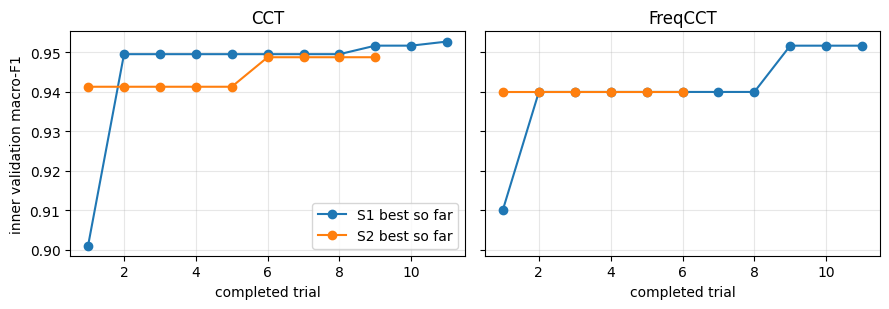

In [7]:
# CELL 6 | Tuning S1 (training recipe) and S2 (size inside the cost cap) for both models. Optuna study kept in SQLite: safe to stop and rerun.
# Objective = real-frame macro-F1 on the inner patient-disjoint validation set. No test frame is scored in this cell.
try:
    import optuna
except ImportError:                                   # Colab does not ship with optuna
    import subprocess; subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'optuna'], check=True); import optuna
from optuna.trial import TrialState
optuna.logging.set_verbosity(optuna.logging.WARNING)
CAP = {"cct": bspc.spec_mflops(dict(arch="cct")) * 1.001}
CAP["freqcct"] = bspc.spec_mflops(dict(arch="freqcct")) * 1.001 if FREQCCT_CAP == "own" else CAP["cct"]
print("cost caps (MFLOPs):", {k: round(v, 2) for k, v in CAP.items()})
WD = [0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]

def recipe_from(t):
    return dict(lr=t.suggest_float("lr", 3e-4, 4e-3, log=True), wd=t.suggest_categorical("wd", WD),
                mlp_drop=t.suggest_float("mlp_drop", 0.0, 0.2), attn_drop=t.suggest_float("attn_drop", 0.0, 0.2), sd=t.suggest_float("sd", 0.0, 0.2),
                smooth=t.suggest_categorical("smooth", [0.0, 0.05, 0.1, 0.15]), sched=t.suggest_categorical("sched", ["plateau", "cosine"]),
                fmask=t.suggest_categorical("fmask", [0, 4, 8]), tmask=t.suggest_categorical("tmask", [0, 4, 8]),
                mixup=t.suggest_categorical("mixup", [0.0, 0.2, 0.4]), ema=t.suggest_categorical("ema", [0.0, 0.99, 0.999]))
RECIPE_KEYS = ["lr", "wd", "mlp_drop", "attn_drop", "sd", "smooth", "sched", "fmask", "tmask", "mixup", "ema"]

def arch_from(t, model):
    a = dict(e=t.suggest_categorical("e", [48, 64, 96] if model == "cct" else [48, 64, 96, 128]), layers=t.suggest_categorical("layers", [3, 4, 6]),
             heads=t.suggest_categorical("heads", [2, 4, 8]), ratio=t.suggest_categorical("ratio", [1, 2, 3]))
    if model == "cct": a["pe"] = t.suggest_categorical("pe", [False, True])
    else: a["tpool"] = t.suggest_categorical("tpool", ["mean", "attn"])
    return {**ARCH_REF[model], **a}

BEST_RECIPE = {}
def make_objective(model, stage):
    def objective(trial):
        if stage == "s1": rec, arch = recipe_from(trial), dict(ARCH_REF[model])
        else: rec, arch = BEST_RECIPE[model], arch_from(trial, model)
        spec = {**REF, **rec, **arch, "max_epochs": MAX_EPOCHS, "label": f"{model} {stage}", "phase": stage, "model": model, "seed": 0}
        if stage == "s2":
            mf = bspc.spec_mflops(spec); trial.set_user_attr("mflops", mf)
            trial.set_user_attr("constraint", (max(0.0, mf - CAP[model]),))
            if mf > CAP[model]: raise optuna.TrialPruned()               # over the cost cap: discarded before any training
        trial.set_user_attr("trained", True)
        tid = f"T_{stage}_{model}_{bspc.stable_hash(trial.params)}"; trial.set_user_attr("tid", tid)
        def cb(ep, f1, vl):
            trial.report(f1, ep)
            if trial.should_prune(): raise bspc.Pruned()
        try: m = run_one(tid, spec, "tune", test=False, report=cb)
        except bspc.Pruned: raise optuna.TrialPruned()
        trial.set_user_attr("minutes", m["minutes"]); trial.set_user_attr("mflops", m["mflops"])
        return m["val_macro_f1"]
    return objective

def open_study(model, stage):
    path = os.path.join(RUN_DIR, "tuning", f"{stage}_{model}.db")
    return optuna.create_study(study_name=f"{RUN_ID}_{stage}_{model}", storage=f"sqlite:///{path}", load_if_exists=True, direction="maximize",
                               pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=8))

def n_trained(study): return sum(1 for t in study.get_trials(deepcopy=False) if t.state in (TrialState.COMPLETE, TrialState.PRUNED) and t.user_attrs.get("trained"))

def run_study(model, stage, n_total):
    study = open_study(model, stage)
    for t in study.get_trials(deepcopy=False, states=[TrialState.RUNNING]):    # a trial that was running when the session died: requeue it
        try: study._storage.set_trial_state_values(t._trial_id, TrialState.FAIL); study.enqueue_trial(t.params)
        except Exception as e: print("   could not requeue an unfinished trial:", type(e).__name__)
    obj = make_objective(model, stage)
    for _ in range(400):
        k = n_trained(study)
        if k >= n_total: break
        if k < 8: study.sampler = optuna.samplers.QMCSampler(qmc_type="sobol", scramble=True, seed=0, warn_independent_sampling=False)
        else: study.sampler = optuna.samplers.TPESampler(multivariate=True, seed=0, constraints_func=(lambda ft: ft.user_attrs.get("constraint", (0.0,))) if stage == "s2" else None)
        print(f"-- {stage} {model}: trial {k + 1}/{n_total}")
        study.optimize(obj, n_trials=1)
    return study

def best_complete(study):
    c = [t for t in study.get_trials(deepcopy=False) if t.state == TrialState.COMPLETE and t.user_attrs.get("trained")]
    return max(c, key=lambda t: t.value) if c else None

for model in ("cct", "freqcct"):
    print(f"\n===== S1 recipe search: {model} =====")
    st = run_study(model, "s1", TUNE["s1"]); b = best_complete(st)
    BEST_RECIPE[model] = {k: b.params[k] for k in RECIPE_KEYS} if b is not None else {k: REF[k] for k in RECIPE_KEYS}
    json.dump(BEST_RECIPE[model], open(os.path.join(RUN_DIR, "configs", f"best_recipe_{model}.json"), "w"), indent=2)
    print(f"   best S1 {model}: val macro-F1 {b.value:.4f}  {BEST_RECIPE[model]}" if b else "   no S1 trial completed; the reference recipe is kept")
for model in ("cct", "freqcct"):
    print(f"\n===== S2 size search inside the cost cap: {model} (cap {CAP[model]:.1f} MFLOPs) =====")
    run_study(model, "s2", TUNE["s2"])

def tuning_table():
    rows = []
    for stage in ("s1", "s2"):
        for model in ("cct", "freqcct"):
            for t in open_study(model, stage).get_trials(deepcopy=False):
                rows.append(dict(stage=stage, model=model, number=t.number, state=t.state.name, value_val_macro_f1=t.value, trial_dir=t.user_attrs.get("tid", ""),
                                 minutes=t.user_attrs.get("minutes", np.nan), mflops=t.user_attrs.get("mflops", np.nan), **t.params))
    return pd.DataFrame(rows)
t13 = tuning_table(); save_table(t13, "table13_tuning_trials")
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for a, model in zip(ax, ("cct", "freqcct")):
    for stage, col in (("s1", "tab:blue"), ("s2", "tab:orange")):
        d = t13[(t13.model == model) & (t13.stage == stage) & (t13.state == "COMPLETE")].sort_values("number")
        if len(d): a.plot(range(1, len(d) + 1), d.value_val_macro_f1.cummax(), "-o", color=col, label=f"{stage.upper()} best so far")
    a.set_title({"cct": "CCT", "freqcct": "FreqCCT"}[model]); a.set_xlabel("completed trial"); a.grid(alpha=.3)
ax[0].set_ylabel("inner validation macro-F1"); ax[0].legend(); fig.tight_layout(); save_fig(fig, "figT1_tuning_history")


## 7. Confirmation S3 and lock

In [8]:
# CELL 7 | S3: confirm the best configurations with 2 seeds, apply the adoption rule, and LOCK the final settings.
# Rule written before any trial ran: a tuned configuration replaces the reference only if its mean inner-validation macro-F1
# (2 seeds) exceeds the reference mean by more than the reference seed SD (floor 0.002). Otherwise the reference stays.
SD_FLOOR = 0.002
def trial_core(tid):
    c = json.load(open(os.path.join(trial_dir(tid), "config.json")))["spec"]; return core_of(c)

LOCKED, rows = {}, []
for model in ("cct", "freqcct"):
    lock_path = os.path.join(RUN_DIR, "configs", f"locked_{model}.json")
    if os.path.exists(lock_path):
        LOCKED[model] = json.load(open(lock_path)); print(f"{model}: already locked ({LOCKED[model]['hash']}), adopted={LOCKED[model]['adopted']}"); continue
    pool = []
    for stage in ("s1", "s2"):
        for t in open_study(model, stage).get_trials(deepcopy=False):
            if t.state == TrialState.COMPLETE and t.user_attrs.get("trained"): pool.append((t.value, t.user_attrs["tid"]))
    seen, top = set(), []
    for v, tid in sorted(pool, reverse=True):
        core = trial_core(tid); h = bspc.stable_hash(core)
        if h not in seen: seen.add(h); top.append((v, tid, core))
        if len(top) == TUNE["top"]: break
    print(f"\n===== S3 {model}: confirming {len(top)} configurations x 2 seeds =====")
    cand = []
    for k, (v, tid, core) in enumerate(top):
        ms = [run_one(f"S3_{model}_c{k}_s{sd}", {**core, "seed": sd, "label": f"{model} S3 c{k}", "phase": "S3", "model": model}, "tune", test=False) for sd in (0, 1)]
        f1s = [m["val_macro_f1"] for m in ms]
        cand.append(dict(config=f"c{k}", core=core, mean=float(np.mean(f1s)), sd=float(np.std(f1s, ddof=1)), mflops=ms[0]["mflops"], params=ms[0]["params"]))
    ref = [json.load(open(os.path.join(trial_dir(f"S0_{model}_s{sd}"), "metrics.json")))["val_macro_f1"] for sd in (0, 1)]
    ref_mean, ref_sd = float(np.mean(ref)), max(float(np.std(ref, ddof=1)), SD_FLOOR)
    best_mean = max(c["mean"] for c in cand)
    near = [c for c in cand if c["mean"] >= best_mean - ref_sd]
    chosen = sorted(near, key=lambda c: (c["mflops"], c["params"], -c["mean"]))[0]
    adopted = chosen["mean"] > ref_mean + ref_sd
    core = chosen["core"] if adopted else {**REF, **ARCH_REF[model]}
    LOCKED[model] = dict(model=model, adopted=bool(adopted), core=core, ref_mean=ref_mean, ref_sd=ref_sd, chosen_config=chosen["config"],
                         chosen_mean=chosen["mean"], chosen_sd=chosen["sd"], hash=bspc.stable_hash(core), locked_at=datetime.datetime.now().isoformat(timespec="seconds"),
                         candidates=[{k: v for k, v in c.items() if k != "core"} for c in cand])
    json.dump(LOCKED[model], open(lock_path, "w"), indent=2)
for model, L in LOCKED.items():
    rows.append(dict(model=model, adopted=L["adopted"], reference_val_f1=round(L["ref_mean"], 4), reference_sd=round(L["ref_sd"], 4),
                     chosen=L["chosen_config"], chosen_val_f1=round(L["chosen_mean"], 4), gain=round(L["chosen_mean"] - L["ref_mean"], 4),
                     **{k: L["core"].get(k) for k in RECIPE_KEYS + ["e", "layers", "heads", "ratio", "pe", "tpool"]}, lock_hash=L["hash"]))
save_table(pd.DataFrame(rows), "table14_locked_configs")
for model, L in LOCKED.items():
    print(f"{model}: " + (f"tuned configuration adopted (+{L['chosen_mean']-L['ref_mean']:.4f} macro-F1 on the inner validation set)" if L["adopted"]
          else "tuning gave no gain beyond seed noise; the reference recipe is kept (this is reported as such)"))
MAIN_CORE = {"cct_ref": {**REF, **ARCH_REF["cct"]}, "freqcct_final": LOCKED["freqcct"]["core"]}
if LOCKED["cct"]["adopted"]: MAIN_CORE["cct_tuned"] = LOCKED["cct"]["core"]
print("models for the generalization runs:", list(MAIN_CORE))


cct: already locked (52ac6e52726b), adopted=True
freqcct: already locked (2aad7d5034e1), adopted=True

[table14_locked_configs]  saved: tables/table14_locked_configs.csv


,model,adopted,reference_val_f1,reference_sd,chosen,chosen_val_f1,gain,lr,wd,mlp_drop,...,tmask,mixup,ema,e,layers,heads,ratio,pe,tpool,lock_hash
0,cct,True,0.9164,0.0081,c1,0.9538,0.0374,0.002946,0.0,0.087734,...,8,0.0,0.99,NaN,NaN,NaN,NaN,None,None,52ac6e52726b
1,freqcct,True,0.8947,0.0196,c2,0.9413,0.0466,0.002946,0.0,0.087734,...,8,0.0,0.99,64.0,4.0,4.0,1.0,None,mean,2aad7d5034e1


cct: tuned configuration adopted (+0.0374 macro-F1 on the inner validation set)
freqcct: tuned configuration adopted (+0.0466 macro-F1 on the inner validation set)
models for the generalization runs: ['cct_ref', 'freqcct_final', 'cct_tuned']


In [9]:
# CELL 8 | Phase D (reference protocol: folds 0 to 4 + seeds 1, 2 on fold 0) and G (patient-disjoint, 5 folds). First scoring of test frames.
# Locked settings only. Nothing here changes a setting.
for key, core in MAIN_CORE.items():
    print(f"\n===== {key}: phase D (reference protocol) =====")
    for f in range(5):
        for s in ((0, 1, 2) if f == 0 else (0,)):
            run_one(f"M_{key}_paper_f{f}_s{s}", main_spec(key, core, "paper", s), "paper", f)
if RUN_PATIENT:
  for key, core in MAIN_CORE.items():
    print(f"\n===== {key}: phase G (patient-disjoint) =====")
    for f in range(5):
        run_one(f"M_{key}_patient_f{f}_s0", main_spec(key, core, "patient", 0), "patient", f)
else: print("phase G (patient-disjoint) skipped: RUN_PATIENT = False")



===== cct_ref: phase D (reference protocol) =====
  ✔ M_cct_ref_paper_f0_s0: best epoch 34/46 | val loss 0.1845 acc 0.9657 F1 0.9656 | TEST acc 0.9652 macro-F1 0.9377 MCC 0.8896 | 173128 params, 124.2 MFLOPs
  ✔ M_cct_ref_paper_f0_s1: best epoch 45/57 | val loss 0.1615 acc 0.9728 F1 0.9728 | TEST acc 0.9648 macro-F1 0.9350 MCC 0.8901 | 173128 params, 124.2 MFLOPs
  ✔ M_cct_ref_paper_f0_s2: best epoch 47/59 | val loss 0.1606 acc 0.9728 F1 0.9729 | TEST acc 0.9674 macro-F1 0.9378 MCC 0.9001 | 173128 params, 124.2 MFLOPs
  ✔ M_cct_ref_paper_f1_s0: best epoch 39/51 | val loss 0.1829 acc 0.9677 F1 0.9677 | TEST acc 0.9579 macro-F1 0.9286 MCC 0.8728 | 173128 params, 124.2 MFLOPs
  ✔ M_cct_ref_paper_f2_s0: best epoch 41/53 | val loss 0.1788 acc 0.9715 F1 0.9715 | TEST acc 0.9628 macro-F1 0.9286 MCC 0.8866 | 173128 params, 124.2 MFLOPs
  ✔ M_cct_ref_paper_f3_s0: best epoch 41/53 | val loss 0.1642 acc 0.9706 F1 0.9706 | TEST acc 0.9607 macro-F1 0.9367 MCC 0.8766 | 173128 params, 124.2 MFLOPs
 

## 8. Generalization: phases D and G


## 8a. View-fusion search (v2)

In [10]:
# CELL 8a | View-fusion search (the 3-channel input). Fold 0, reference protocol, locked recipe; decided on VALIDATION frames only.
# Variants: norm = per-view standardisation | stem = grouped-conv view stem | se = view gate (SE) | vdrop = view dropout 0.2 | se_vdrop = gate + view dropout.
# Adoption rule (fixed before any run): the best variant is run on folds 1 to 4; it is adopted only if (a) its fold-0 validation macro-F1 beats the
# plain model by more than the plain model's seed SD (floor 0.002), (b) the 5-fold mean validation macro-F1 gain is above that SD, and
# (c) no fold's validation accuracy falls by more than 0.2 points. Otherwise the plain input is kept and the result is reported as a negative one.
FUSION_VARIANTS = {"norm": dict(fusion="norm"), "stem": dict(fusion="stem"), "se": dict(fusion="se"),
                   "vdrop": dict(view_drop=0.2), "se_vdrop": dict(fusion="se", view_drop=0.2)}
FUSION_BASE = {"cct": "cct_tuned" if "cct_tuned" in MAIN_CORE else "cct_ref", "freqcct": "freqcct_final"}
FUSION_RESULT, rows = {}, []
def val_of(tid, key="val_macro_f1"): return json.load(open(os.path.join(trial_dir(tid), "metrics.json")))[key]
for fm_ in FUSION_MODELS:
    base = FUSION_BASE[fm_]; core = MAIN_CORE[base]; fkey = f"{base}_fused"; sel_path = os.path.join(RUN_DIR, "configs", f"fusion_{fm_}.json")
    if os.path.exists(sel_path):
        FUSION_RESULT[fm_] = json.load(open(sel_path)); print(f"{fm_}: fusion decision already made: {FUSION_RESULT[fm_]['decision']}")
    else:
        print(f"\n===== view fusion, {fm_} (base {base}) =====")
        ref_f1 = val_of(f"M_{base}_paper_f0_s0"); ref_seeds = [val_of(f"M_{base}_paper_f0_s{s}") for s in (0, 1, 2) if os.path.exists(os.path.join(trial_dir(f"M_{base}_paper_f0_s{s}"), "metrics.json"))]
        sd_ref = max(float(np.std(ref_seeds, ddof=1)) if len(ref_seeds) > 1 else 0.0, SD_FLOOR)
        res = {}
        for v, kw in FUSION_VARIANTS.items():
            sp = {**core, **kw, "model": f"{base}+{v}", "label": f"{LABELS.get(base, base)} + {v}", "phase": "fusion", "protocol": "paper", "seed": 0}
            m = run_one(f"X_{base}_{v}_paper_f0_s0", sp, "paper", 0); res[v] = dict(val_macro_f1=m["val_macro_f1"], val_acc=m["val_acc"], params=m["params"])
        best_v = max(res, key=lambda v: (round(res[v]["val_macro_f1"], 4), -res[v]["params"]))
        gain0 = res[best_v]["val_macro_f1"] - ref_f1; decision, adopted, per_fold = "rejected at fold 0 (gain within seed noise)", False, []
        if gain0 > sd_ref:
            fcore = {**core, **FUSION_VARIANTS[best_v]}
            LABELS[fkey] = f"{LABELS.get(base, base)} + {best_v}"
            for f in range(1, 5): run_one(f"M_{fkey}_paper_f{f}_s0", main_spec(fkey, fcore, "paper", 0), "paper", f)
            run_one(f"M_{fkey}_paper_f0_s0", main_spec(fkey, fcore, "paper", 0), "paper", 0)
            for f in range(5):
                per_fold.append(dict(fold=f, base_val_f1=val_of(f"M_{base}_paper_f{f}_s0"), fused_val_f1=val_of(f"M_{fkey}_paper_f{f}_s0"),
                                     base_val_acc=val_of(f"M_{base}_paper_f{f}_s0", "val_acc"), fused_val_acc=val_of(f"M_{fkey}_paper_f{f}_s0", "val_acc")))
            pf = pd.DataFrame(per_fold); mean_gain = float((pf.fused_val_f1 - pf.base_val_f1).mean()); worst_acc = float((pf.fused_val_acc - pf.base_val_acc).min())
            adopted = bool(mean_gain > sd_ref and worst_acc >= -0.002)
            decision = f"{'adopted' if adopted else 'rejected on the 5-fold check'}: variant {best_v}, mean validation gain {mean_gain:+.4f}, worst fold accuracy change {worst_acc:+.4f}"
        FUSION_RESULT[fm_] = dict(model=fm_, base=base, best_variant=best_v, adopted=adopted, decision=decision, ref_val_f1=ref_f1, ref_sd=sd_ref, variants=res,
                                  core=({**core, **FUSION_VARIANTS[best_v]} if adopted else None), per_fold=per_fold)
        json.dump(FUSION_RESULT[fm_], open(sel_path, "w"), indent=2, default=str); print(f"   {fm_}: {decision}")
    R_ = FUSION_RESULT[fm_]
    for v, d in R_["variants"].items(): rows.append(dict(model=fm_, variant=v, val_macro_f1=round(d["val_macro_f1"], 4), val_acc=round(d["val_acc"], 4), params=d["params"],
                                                         gain_vs_plain=round(d["val_macro_f1"] - R_["ref_val_f1"], 4), seed_sd_of_plain=round(R_["ref_sd"], 4), picked=(v == R_["best_variant"])))
    if R_["adopted"]:
        k = f"{R_['base']}_fused"; MAIN_CORE[k] = R_["core"]; LABELS[k] = f"{LABELS.get(R_['base'], R_['base'])} + {R_['best_variant']}"
if rows: save_table(pd.DataFrame(rows), "table15_view_fusion_fold0_validation")
print("models for selection:", list(MAIN_CORE))


cct: fusion decision already made: adopted: variant se, mean validation gain +0.0028, worst fold accuracy change +0.0009
freqcct: fusion decision already made: rejected at fold 0 (gain within seed noise)

[table15_view_fusion_fold0_validation]  saved: tables/table15_view_fusion_fold0_validation.csv


,model,variant,val_macro_f1,val_acc,params,gain_vs_plain,seed_sd_of_plain,picked
0,cct,norm,0.9768,0.9768,173128,0.0009,0.002,False
1,cct,stem,0.9793,0.9793,173287,0.0034,0.002,False
2,cct,se,0.9797,0.9797,173187,0.0038,0.002,True
3,cct,vdrop,0.9664,0.9664,173128,-0.0095,0.002,False
4,cct,se_vdrop,0.9665,0.9666,173187,-0.0094,0.002,False
5,freqcct,norm,0.9635,0.9635,124999,-0.0072,0.002,False
6,freqcct,stem,0.9724,0.9724,125158,0.0017,0.002,True
7,freqcct,se,0.9678,0.9679,125058,-0.0029,0.002,False
8,freqcct,vdrop,0.9632,0.9633,124999,-0.0075,0.002,False
9,freqcct,se_vdrop,0.9680,0.9681,125058,-0.0027,0.002,False


models for selection: ['cct_ref', 'freqcct_final', 'cct_tuned', 'cct_tuned_fused']


## 8b. Headline selection and extra seeds (v2)

In [11]:
# CELL 8b | Dynamic selection of the headline model and its extra seeds. Nothing is pre-selected: the choice reads validation scores only.
# Rule: highest mean validation macro-F1 over the 5 reference-protocol folds (seed 0); models within 0.002 are separated by fewer parameters.
# Result is written to configs/selection.json. The headline model then gets seeds in FINAL_SEEDS on all 5 folds (3 seeds x 5 folds = 15 runs).
sel_path = os.path.join(RUN_DIR, "configs", "selection.json")
if os.path.exists(sel_path):
    SEL = json.load(open(sel_path)); print("selection already made:", SEL["headline"])
else:
    rows = []
    for k in MAIN_CORE:
        ms_ = [json.load(open(os.path.join(trial_dir(f"M_{k}_paper_f{f}_s0"), "metrics.json"))) for f in range(5)]
        rows.append(dict(model=k, label=LABELS.get(k, k), val_macro_f1=float(np.mean([m["val_macro_f1"] for m in ms_])), val_acc=float(np.mean([m["val_acc"] for m in ms_])), params=ms_[0]["params"], mflops=ms_[0]["mflops"]))
    T = pd.DataFrame(rows); top = T.val_macro_f1.max(); near = T[T.val_macro_f1 >= top - 0.002].sort_values(["params", "mflops"])
    head = near.iloc[0].model
    SEL = dict(headline=head, rule="mean validation macro-F1 over 5 folds; ties within 0.002 -> fewer parameters", candidates=T.round(5).to_dict("records"), core=MAIN_CORE[head],
               chosen_at=datetime.datetime.now().isoformat(timespec="seconds"))
    json.dump(SEL, open(sel_path, "w"), indent=2, default=str)
HEAD_KEY, HEAD_CORE = SEL["headline"], MAIN_CORE[SEL["headline"]]
save_table(pd.DataFrame(SEL["candidates"]), "table16_headline_selection_validation")
print(f"headline model: {HEAD_KEY}  ({HEAD_CORE['arch']})")
print(f"\n===== {HEAD_KEY}: seeds {FINAL_SEEDS} x 5 folds =====")
for f in range(5):
    for s in FINAL_SEEDS: run_one(f"M_{HEAD_KEY}_paper_f{f}_s{s}", main_spec(HEAD_KEY, HEAD_CORE, "paper", s), "paper", f)
Rh = collect(); Rh = Rh[(Rh.model == HEAD_KEY) & (Rh.phase == "main") & (Rh.protocol == "paper")]
seed_mean = Rh.groupby("seed")[["test_accuracy", "test_macro_f1", "test_mcc"]].mean(); fold_mean = Rh.groupby("fold")[["test_accuracy", "test_macro_f1", "test_mcc"]].mean()
t17 = pd.DataFrame([dict(metric=c, overall_mean=round(Rh[c].mean(), 4), sd_over_folds=round(fold_mean[c].std(ddof=1), 4), sd_over_seeds=round(seed_mean[c].std(ddof=1), 4),
                         runs=len(Rh), min=round(Rh[c].min(), 4), max=round(Rh[c].max(), 4)) for c in ("test_accuracy", "test_macro_f1", "test_mcc")])
save_table(t17, "table17_headline_3seeds_x_5folds")
save_table(Rh.pivot_table(index="fold", columns="seed", values="test_accuracy").round(4).reset_index(), "table17b_headline_accuracy_fold_by_seed")


selection already made: cct_tuned_fused

[table16_headline_selection_validation]  saved: tables/table16_headline_selection_validation.csv


,model,label,val_macro_f1,val_acc,params,mflops
0,cct_ref,CCT (reference),0.96918,0.96918,173128,124.23258
1,freqcct_final,FreqCCT (final),0.97180,0.97183,124999,72.51354
2,cct_tuned,CCT (tuned),0.97474,0.97473,173128,124.23258
3,cct_tuned_fused,CCT (tuned) + se,0.97758,0.97760,173187,124.23267


headline model: cct_tuned_fused  (cct)

===== cct_tuned_fused: seeds (0, 1, 2) x 5 folds =====
  ✔ M_cct_tuned_fused_paper_f0_s0: best epoch 68/80 | val loss 0.1772 acc 0.9809 F1 0.9809 | TEST acc 0.9813 macro-F1 0.9695 MCC 0.9410 | 173187 params, 124.2 MFLOPs
  ✔ M_cct_tuned_fused_paper_f0_s1: best epoch 70/82 | val loss 0.1915 acc 0.9746 F1 0.9746 | TEST acc 0.9780 macro-F1 0.9639 MCC 0.9302 | 173187 params, 124.2 MFLOPs
  ✔ M_cct_tuned_fused_paper_f0_s2: best epoch 59/71 | val loss 0.1755 acc 0.9775 F1 0.9774 | TEST acc 0.9818 macro-F1 0.9626 MCC 0.9418 | 173187 params, 124.2 MFLOPs
  ✔ M_cct_tuned_fused_paper_f1_s0: best epoch 61/73 | val loss 0.1773 acc 0.9791 F1 0.9791 | TEST acc 0.9766 macro-F1 0.9625 MCC 0.9283 | 173187 params, 124.2 MFLOPs
  ✔ M_cct_tuned_fused_paper_f1_s1: best epoch 70/82 | val loss 0.1873 acc 0.9759 F1 0.9759 | TEST acc 0.9729 macro-F1 0.9558 MCC 0.9157 | 173187 params, 124.2 MFLOPs
  ✔ M_cct_tuned_fused_paper_f1_s2: best epoch 70/82 | val loss 0.1754 acc 0

,metric,overall_mean,sd_over_folds,sd_over_seeds,runs,min,max
0,test_accuracy,0.9765,0.0041,0.0014,15,0.9674,0.9818
1,test_macro_f1,0.9594,0.0071,0.0018,15,0.9411,0.9728
2,test_mcc,0.9263,0.0119,0.0048,15,0.8981,0.9424



[table17b_headline_accuracy_fold_by_seed]  saved: tables/table17b_headline_accuracy_fold_by_seed.csv


seed,fold,0,1,2
0,0,0.9813,0.9780,0.9818
1,1,0.9766,0.9729,0.9812
2,2,0.9674,0.9732,0.9690
3,3,0.9780,0.9793,0.9802
4,4,0.9769,0.9732,0.9782


'/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/tables/table17b_headline_accuracy_fold_by_seed.csv'

## 9. Pretrained baselines: phase E

> Add blockquote

> Add blockquote





In [12]:
 # CELL 9 | Phase E: ImageNet-pretrained baselines under the cap (<= 1.5 M parameters, <= 124 MFLOPs) plus two over-cap references.
# v2: MobileViT-XXS (timm) replaces MNASNet 0.5; linear 7-class head on every backbone.
# Parity: same regularisation recipe as the locked CCT. Fold 0, reference protocol.
try: import timm
except ImportError:
    import subprocess; subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True); import timm
rcp = {k: MAIN_CORE.get("cct_tuned", MAIN_CORE["cct_ref"])[k] for k in ("wd", "smooth", "sched", "fmask", "tmask", "mixup", "ema")}
# Added best LR as the third element of the tuple. Adjust `1e-3` to the actual best LR for each model.
BL = [("mobilenetv3s", True, 1e-3), ("mobilevitxxs", True, 1e-3), ("effnetb0", False, 1e-3), ("resnet18", False, 1e-3)]
for name, matched, lr in BL:
    spec = {**REF, **rcp, "arch": name, "lr": lr, "scale": 2, "pretrained": not SMOKE, "mlp_drop": 0.0, "attn_drop": 0.0, "sd": 0.0,
            "model": f"{name}_lr{lr:g}", "label": bspc.BASELINES[name] + (" (matched)" if matched else " (over cap, reference)"), "phase": "E", "seed": 0}
    run_one(f"E_{name}_lr{lr:g}_paper_f0_s0", spec, "paper", 0)
R = collect(); E = R[R.phase == "E"].copy()
E["matched_cap"] = E.arch.isin([n for n, m, _ in BL if m])
E["within_cap"] = (E.params <= 1.5e6) & (E.mflops <= 124.5)
bad = E[E.matched_cap & ~E.within_cap]
print("cap check (matched models must be within 1.5 M parameters and 124 MFLOPs):", "OK" if bad.empty else f"VIOLATION\n{bad[['trial','params','mflops']]}")


  ✔ E_mobilenetv3s_lr0.001_paper_f0_s0: best epoch 37/49 | val loss 0.1618 acc 0.9897 F1 0.9897 | TEST acc 0.9881 macro-F1 0.9777 MCC 0.9611 | 931047 params, 24.5 MFLOPs
  ✔ E_mobilevitxxs_lr0.001_paper_f0_s0: best epoch 49/61 | val loss 0.1584 acc 0.9917 F1 0.9916 | TEST acc 0.9911 macro-F1 0.9843 MCC 0.9707 | 953271 params, 109.6 MFLOPs
  ✔ E_effnetb0_lr0.001_paper_f0_s0: best epoch 30/42 | val loss 0.1555 acc 0.9924 F1 0.9924 | TEST acc 0.9915 macro-F1 0.9841 MCC 0.9718 | 4016515 params, 168.2 MFLOPs
  ✔ E_resnet18_lr0.001_paper_f0_s0: best epoch 23/35 | val loss 0.1488 acc 0.9933 F1 0.9933 | TEST acc 0.9907 macro-F1 0.9808 MCC 0.9697 | 11180103 params, 773.8 MFLOPs
cap check (matched models must be within 1.5 M parameters and 124 MFLOPs): OK


## 10. Ablations: phase F

In [13]:
 # CELL 10 | Phase F: ablations of the final FreqCCT on fold 0 (reference protocol). Only the ones a reviewer will ask for.
# F1 components | F2 input channels | F3 augmentation and recipe | F4 frequency rows (12 of 16: ranked vs random).
import torch
FC = MAIN_CORE["freqcct_final"]; fm = lambda tag, **kw: {**FC, **kw, "model": tag, "label": tag, "phase": "F", "seed": 0}
F = [("F1a_no_position", fm("F1a no position", pe=False)), ("F1b_no_freq_pooling", fm("F1b SeqPool head", fp=False)),
     ("F1c_standard_tokenizer", fm("F1c standard tokenizer", dw=False)),
     ("F1d_none", {**{k: v for k, v in FC.items() if k not in ("tpool",)}, "arch": "cct", "dw": False, "pe": False, "model": "F1d CCT body, same recipe", "label": "F1d CCT body, same recipe", "phase": "F", "seed": 0}),
     ("F2a_mel_only", fm("F2a mel only", channels=[0])), ("F2b_mel_cqt", fm("F2b mel + CQT", channels=[0, 1])),
     ("F3b_reference_recipe", {**FC, **{k: REF[k] for k in RECIPE_KEYS}, "model": "F3b reference recipe", "label": "F3b reference recipe", "phase": "F", "seed": 0})]
for tid, sp in F: run_one(f"{tid}_paper_f0_s0", sp, "paper", 0)
run_one("F3a_no_waveform_aug_paper_f0_s0", fm("F3a real frames only"), "paper", 0, train_real_only=True)

# F4: rank the 16 token rows on VALIDATION frames by occlusion of the final model, keep the best 12; control = 12 random rows
mdl = bspc.load_model(FC, trial_dir("M_freqcct_final_paper_f0_s0"), device)
va_ix = SP["paper"][0][1]; va_ix = va_ix[aug_v[va_ix] == 0]
base = bspc.macro_f1_present(y[va_ix], bspc.predict_probs(mdl, Xg, va_ix, FC, device).argmax(1))
drop = []
for r in range(16):
    Xo = Xg[torch.as_tensor(va_ix, device=device)].clone(); Xo[:, :, 4 * r:4 * r + 4] = 0
    p = []
    with torch.no_grad():
        for i in range(0, len(Xo), 2048): p.append(mdl(Xo[i:i + 2048].float()).argmax(1).cpu())
    drop.append(base - bspc.macro_f1_present(y[va_ix], torch.cat(p).numpy()))
rank = np.argsort(drop)[::-1]; top12 = sorted(int(r) for r in rank[:12]); rnd12 = sorted(int(r) for r in np.random.default_rng(0).choice(16, 12, replace=False))
save_table(pd.concat([bspc.token_row_hz(), pd.DataFrame({"occlusion_drop_val_macroF1": drop})], axis=1), "table07b_row_ranking")
for tid, rows_, lab in (("F4a_top12_rows", top12, "F4a top-12 rows"), ("F4b_random12_rows", rnd12, "F4b random-12 rows")):
    run_one(f"{tid}_paper_f0_s0", fm(lab, rows=rows_), "paper", 0)
print("kept rows  ranked:", top12, "| random:", rnd12)


  ✔ F1a_no_position_paper_f0_s0: best epoch 59/71 | val loss 0.2027 acc 0.9671 F1 0.9670 | TEST acc 0.9767 macro-F1 0.9526 MCC 0.9256 | 114759 params, 72.5 MFLOPs
  ✔ F1b_no_freq_pooling_paper_f0_s0: best epoch 67/79 | val loss 0.1978 acc 0.9697 F1 0.9697 | TEST acc 0.9741 macro-F1 0.9534 MCC 0.9187 | 118216 params, 72.5 MFLOPs
  ✔ F1c_standard_tokenizer_paper_f0_s0: best epoch 46/58 | val loss 0.1819 acc 0.9780 F1 0.9780 | TEST acc 0.9822 macro-F1 0.9660 MCC 0.9422 | 157127 params, 113.7 MFLOPs
  ✔ F1d_none_paper_f0_s0: best epoch 51/63 | val loss 0.1773 acc 0.9750 F1 0.9749 | TEST acc 0.9750 macro-F1 0.9518 MCC 0.9214 | 140104 params, 113.7 MFLOPs
  ✔ F2a_mel_only_paper_f0_s0: best epoch 51/63 | val loss 0.1842 acc 0.9751 F1 0.9751 | TEST acc 0.9708 macro-F1 0.9442 MCC 0.9110 | 123847 params, 66.6 MFLOPs
  ✔ F2b_mel_cqt_paper_f0_s0: best epoch 47/59 | val loss 0.1900 acc 0.9695 F1 0.9694 | TEST acc 0.9771 macro-F1 0.9544 MCC 0.9278 | 124423 params, 69.6 MFLOPs
  ✔ F3b_reference_recip

,token_row,mel_lo_hz,mel_hi_hz,cqt_lo_hz,cqt_hi_hz,occlusion_drop_val_macroF1
0,0,26,103,32.7,38.9,0.716970
1,1,129,206,41.2,49.0,0.626954
2,2,232,309,51.9,61.7,0.665358
3,3,334,412,65.4,77.8,0.560410
4,4,437,515,82.4,98.0,0.445600
5,5,540,617,103.8,123.5,0.526193
6,6,643,720,130.8,155.5,0.579430
7,7,746,823,164.8,196.0,0.574377
8,8,849,926,207.6,246.9,0.295365
9,9,952,1030,261.6,311.1,0.258757


  ✔ F4a_top12_rows_paper_f0_s0: best epoch 45/57 | val loss 0.1951 acc 0.9681 F1 0.9680 | TEST acc 0.9657 macro-F1 0.9218 MCC 0.8929 | 120647 params, 49.5 MFLOPs
  ✔ F4b_random12_rows_paper_f0_s0: best epoch 55/67 | val loss 0.2166 acc 0.9583 F1 0.9582 | TEST acc 0.9699 macro-F1 0.9389 MCC 0.9032 | 120647 params, 49.5 MFLOPs
kept rows  ranked: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12] | random: [0, 2, 3, 4, 6, 8, 9, 10, 11, 12, 13, 14]


## 10a. Must-have ablations of the headline model (v2)

In [14]:
   # CELL 10a | Must-have ablations of the HEADLINE model (read from selection.json), fold 0, seed 0, reference protocol, same recipe as the headline.
# Each ablation changes one thing. Where a change moves two things at once, a control is run next to it:
#   views: mel only, mel+CQT, mel+MFCC, CQT+MFCC (leave-one-out) | pooling: mean, class token (CCT only; FreqCCT head is covered in cell 10)
#   encoder: 0 layers (changes capacity) + attention-free control with matched parameters (changes token mixing only)
#   augmentation: real frames only (changes data AND class balance) + real frames with class-balanced sampling (changes data only)
import torch
HK, HC = HEAD_KEY, HEAD_CORE
hm = lambda tag, **kw: {**HC, **kw, "model": tag, "label": tag, "phase": "H", "seed": 0}
base_params = json.load(open(os.path.join(trial_dir(f"M_{HK}_paper_f0_s0"), "metrics.json")))["params"]
ratio_match = bspc.match_ratio(HC, base_params)
H_RUNS = [("H1a_mel_only", hm("views: mel only", channels=[0]), False), ("H1b_mel_cqt", hm("views: mel + CQT", channels=[0, 1]), False),
          ("H1c_mel_mfcc", hm("views: mel + MFCC", channels=[0, 2]), False), ("H1d_cqt_mfcc", hm("views: CQT + MFCC (no mel)", channels=[1, 2]), False),
          ("H2a_no_encoder", hm("encoder: 0 layers", layers=0), False),
          ("H2b_no_attention_matched", hm(f"encoder: no attention, params matched (FFN ratio {ratio_match})", attn=False, ratio=ratio_match), False),
          ("H3a_real_only", hm("data: real frames only", ), True),
          ("H3b_real_only_balanced", hm("data: real frames only, class-balanced sampling", balance=True), True)]
if HC["arch"] == "cct":
    H_RUNS += [("H4a_mean_pool", hm("pooling: mean", pool="mean"), False), ("H4b_class_token", hm("pooling: class token", pool="cls"), False)]
for tid, sp, real_only in H_RUNS: run_one(f"{tid}_paper_f0_s0", sp, "paper", 0, train_real_only=real_only)
Rh = collect(); Hh = Rh[Rh.phase == "H"]; ref = Rh[Rh.trial == f"M_{HK}_paper_f0_s0"].iloc[0]
rows = [dict(ablation="headline (reference)", params=int(ref.params), MFLOPs=round(ref.mflops, 1), accuracy=ref.test_accuracy, macro_F1=ref.test_macro_f1, MCC=ref.test_mcc, rec_vote_acc=ref.rec_accuracy)]
for r in Hh.sort_values("trial").itertuples():
    rows.append(dict(ablation=r.label, params=int(r.params), MFLOPs=round(r.mflops, 1) if r.mflops == r.mflops else np.nan, accuracy=r.test_accuracy, macro_F1=r.test_macro_f1, MCC=r.test_mcc, rec_vote_acc=r.rec_accuracy))
t18 = pd.DataFrame(rows).round(4); t18["delta_macro_F1"] = (t18.macro_F1 - t18.macro_F1.iloc[0]).round(4)
save_table(t18, "table18_must_ablations_headline_fold0")


  ✔ H1a_mel_only_paper_f0_s0: best epoch 72/84 | val loss 0.1852 acc 0.9757 F1 0.9757 | TEST acc 0.9780 macro-F1 0.9601 MCC 0.9290 | 172001 params, 118.3 MFLOPs
  ✔ H1b_mel_cqt_paper_f0_s0: best epoch 51/63 | val loss 0.1792 acc 0.9795 F1 0.9795 | TEST acc 0.9775 macro-F1 0.9597 MCC 0.9287 | 172594 params, 121.3 MFLOPs
  ✔ H1c_mel_mfcc_paper_f0_s0: best epoch 69/81 | val loss 0.1837 acc 0.9757 F1 0.9756 | TEST acc 0.9780 macro-F1 0.9650 MCC 0.9305 | 172594 params, 121.3 MFLOPs
  ✔ H1d_cqt_mfcc_paper_f0_s0: best epoch 59/71 | val loss 0.1842 acc 0.9693 F1 0.9693 | TEST acc 0.9665 macro-F1 0.9355 MCC 0.8963 | 172594 params, 121.3 MFLOPs
  ✔ H2a_no_encoder_paper_f0_s0: best epoch 97/100 | val loss 0.5822 acc 0.8283 F1 0.8260 | TEST acc 0.8533 macro-F1 0.6779 MCC 0.5814 | 39299 params, 56.1 MFLOPs
  ✔ H2b_no_attention_matched_paper_f0_s0: best epoch 78/90 | val loss 0.2160 acc 0.9755 F1 0.9755 | TEST acc 0.9741 macro-F1 0.9516 MCC 0.9190 | 172675 params, 98.0 MFLOPs
  ✔ H3a_real_only_paper

,ablation,params,MFLOPs,accuracy,macro_F1,MCC,rec_vote_acc,delta_macro_F1
0,headline (reference),173187,124.2,0.9813,0.9695,0.9410,0.9849,0.0000
1,views: mel only,172001,118.3,0.9780,0.9601,0.9290,0.9826,-0.0094
2,views: mel + CQT,172594,121.3,0.9775,0.9597,0.9287,0.9818,-0.0098
3,views: mel + MFCC,172594,121.3,0.9780,0.9650,0.9305,0.9857,-0.0045
4,views: CQT + MFCC (no mel),172594,121.3,0.9665,0.9355,0.8963,0.9715,-0.0340
5,encoder: 0 layers,39299,56.1,0.8533,0.6779,0.5814,0.8629,-0.2916
6,"encoder: no attention, params matched (FFN rat...",172675,98.0,0.9741,0.9516,0.9190,0.9762,-0.0179
7,data: real frames only,173187,124.2,0.9334,0.7801,0.7697,0.9366,-0.1894
8,"data: real frames only, class-balanced sampling",173187,124.2,0.6265,0.4584,0.3946,0.6442,-0.5111
9,pooling: mean,173122,124.2,0.9801,0.9570,0.9366,0.9826,-0.0125


'/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/tables/table18_must_ablations_headline_fold0.csv'

## 11. Tables 2 to 11

In [15]:
# CELL 11 | Tables 2 to 11. Every table is printed here and saved as CSV in runs/<RUN_ID>/tables/.
R = collect()
def ms(s): return f"{s.mean():.4f} ± {s.std(ddof=1):.4f}" if len(s) > 1 else f"{s.iloc[0]:.4f}"
def mean_sd_table(d, keys, cols):
    out = []
    for k, g in d.groupby(keys, sort=False):
        k = k if isinstance(k, tuple) else (k,)
        out.append({**dict(zip(keys, k)), "runs": len(g), **{c: ms(g[c]) for c in cols if c in g}, "params": int(g.params.iloc[0]), "MFLOPs": round(g.mflops.iloc[0], 1)})
    return pd.DataFrame(out)
MET = ["test_accuracy", "test_macro_f1", "test_bal_acc", "test_mcc", "rec_accuracy", "rec_macro_f1"]

# Table 2: settings and cost of every finished run
cfgs = []
for tid in R.trial:
    c = json.load(open(os.path.join(trial_dir(tid), "config.json")))["spec"]
    cfgs.append({"trial": tid, **{k: c.get(k) for k in ["arch", "e", "layers", "heads", "ratio", "pe", "dw", "fp", "tpool", "lr", "wd", "mlp_drop", "attn_drop", "sd", "smooth", "sched", "fmask", "tmask", "mixup", "ema", "batch_size", "seed", "split", "fold"]}})
t02 = pd.DataFrame(cfgs).merge(R[["trial", "params", "mflops", "mflops_analytic", "best_epoch", "epochs_run"]], on="trial")
save_table(t02, "table02_configs_and_cost", show=False); print(f"[table02_configs_and_cost] {len(t02)} runs saved (not printed: long)")

# Table 3: main results, reference protocol, folds 0 to 4 (mean ± SD over folds; fold 0 uses seed 0)
Mp = R[(R.phase == "main") & (R.protocol == "paper") & (R.seed == 0)]
t03 = mean_sd_table(Mp, ["model"], MET); save_table(t03, "table03_main_results_reference_protocol")
# seeds on fold 0
Sd = R[(R.phase == "main") & (R.protocol == "paper") & (R.fold == 0)]
save_table(mean_sd_table(Sd, ["model"], MET), "table03b_seed_variation_fold0")
# Table 10: patient-disjoint
Gp = R[(R.phase == "main") & (R.protocol == "patient")]
if len(Gp):                                                       # only when RUN_PATIENT = True
    t10 = mean_sd_table(Gp, ["model"], MET); save_table(t10, "table10_patient_disjoint")
    save_table(Gp[["trial", "model", "fold", "test_n_classes", "test_n", "test_accuracy", "test_macro_f1", "test_mcc", "rec_accuracy"]].round(4), "table10b_patient_disjoint_per_fold")

# Table 4: per-class precision / recall / F1 (fold 0, seed 0, both protocols)
rows = []
for _, r in R[(R.phase == "main") & (R.fold == 0) & (R.seed == 0)].iterrows():
    for pc in json.load(open(os.path.join(trial_dir(r.trial), "metrics.json")))["per_class"]:
        rows.append(dict(model=r.model, protocol=r.protocol, **pc))
t04 = pd.DataFrame(rows).round(4); save_table(t04, "table04_per_class_fold0")

# Table 5: paired comparisons on fold 0 (same test frames): McNemar on frames, bootstrap interval of the macro-F1 difference by recording
def preds_of(tid):
    z = np.load(os.path.join(trial_dir(tid), "preds.npz")); return z["test_idx"], z["test_probs"].argmax(1)
pairs = [("freqcct_final", "cct_ref"), ("cct_tuned", "cct_ref"), ("freqcct_final", "cct_tuned"), ("freqcct_final", "freqcct_ref")]
rows = []
for a, b in pairs:
    ta, tb = f"M_{a}_paper_f0_s0", f"M_{b}_paper_f0_s0"
    if b == "freqcct_ref": tb = "A4_freqcct_ref_paper_f0_s0"
    if not (os.path.exists(os.path.join(trial_dir(ta), "preds.npz")) and os.path.exists(os.path.join(trial_dir(tb), "preds.npz"))): continue
    ia, pa = preds_of(ta); ib, pb = preds_of(tb); yt = y[ia]
    chi, p, n01, n10 = bspc.mcnemar(pa == yt, pb == yt)
    d, lo, hi = bspc.bootstrap_diff(yt, pa, pb, M["rec_idx"].values[ia], B=500)
    rows.append(dict(A=a, B=b, macroF1_A_minus_B=round(d, 4), CI95_low=round(lo, 4), CI95_high=round(hi, 4), only_A_correct=n01, only_B_correct=n10, mcnemar_p=round(p, 4)))
t05 = pd.DataFrame(rows)
if len(t05): t05["holm_p"] = np.round(bspc.holm(t05.mcnemar_p.values), 4)
save_table(t05, "table05_paired_comparisons_fold0")

# Table 6: baselines (best learning rate per model chosen on validation macro-F1)
E = R[R.phase == "E"].copy()
if len(E):
    E = E.sort_values("val_macro_f1", ascending=False).groupby("arch", sort=False).head(1)
    ours = R[(R.phase == "main") & (R.protocol == "paper") & (R.fold == 0) & (R.seed == 0)]
    cols = ["label", "arch", "params", "mflops", "val_macro_f1", "test_accuracy", "test_macro_f1", "test_mcc"]
    t06 = pd.concat([ours.assign(arch=ours.model)[cols], E[cols]]).round(4); save_table(t06, "table06_baselines_vs_ours_fold0")

# Table 7: ablations (fold 0, seed 0) with the final FreqCCT as the first row
Fa = R[R.phase == "F"]
if len(Fa):
    fin = R[R.trial == "M_freqcct_final_paper_f0_s0"]
    t07 = pd.concat([fin.assign(label="FreqCCT (final)"), Fa])[["label", "params", "mflops", "test_accuracy", "test_macro_f1", "test_mcc", "rec_accuracy"]].round(4)
    t07["delta_macroF1_vs_final"] = (t07.test_macro_f1 - float(fin.test_macro_f1.iloc[0])).round(4); save_table(t07, "table07_ablations_fold0")

# Table 9: training time of every model
t09 = R[R.phase.isin(["main", "A", "E", "F", "H", "fusion"])][["trial", "label", "epochs_run", "best_epoch"]]      # epochs only; wall-clock time is not reported
save_table(t09, "table09_epochs_run", show=False)

# Table 11: post-hoc steps on the final models (fold 0, reference protocol). Tuned on validation only.
rows = []
for key in MAIN_CORE:
    tid = f"M_{key}_paper_f0_s0"; z = np.load(os.path.join(trial_dir(tid), "preds.npz")); core = MAIN_CORE[key]
    tr, va, te = SP["paper"][0]; real_tr = tr[aug_v[tr] == 0]
    prior_real = np.bincount(y[real_tr], minlength=7) / len(real_tr); prior_tr = np.bincount(y[tr], minlength=7) / len(tr)
    vmask = aug_v[z["val_idx"]] == 0; Pv, yv = z["val_probs"][vmask], y[z["val_idx"]][vmask]
    taus = np.linspace(0, 1.5, 16); f1v = [bspc.macro_f1_present(yv, bspc.logit_adjust(Pv, prior_tr, prior_real, t).argmax(1)) for t in taus]
    tau = float(taus[int(np.argmax(f1v))]); Pt, yt = z["test_probs"], y[z["test_idx"]]
    s0, s1 = bspc.scores(yt, Pt.argmax(1)), bspc.scores(yt, bspc.logit_adjust(Pt, prior_tr, prior_real, tau).argmax(1))
    Pr, yr, _ = bspc.rec_vote(Pt, yt, M["rec_idx"].values[z["test_idx"]]); sr = bspc.scores(yr, Pr.argmax(1))
    rows.append(dict(model=key, tau_chosen_on_validation=round(tau, 2), frame_F1_raw=round(s0["macro_f1"], 4), frame_F1_prior_corrected=round(s1["macro_f1"], 4),
                     frame_acc_raw=round(s0["accuracy"], 4), frame_acc_prior_corrected=round(s1["accuracy"], 4), recording_vote_acc=round(sr["accuracy"], 4), recording_vote_F1=round(sr["macro_f1"], 4)))
save_table(pd.DataFrame(rows), "table11_posthoc_prior_correction_and_recording_vote")


[table02_configs_and_cost] 126 runs saved (not printed: long)

[table03_main_results_reference_protocol]  saved: tables/table03_main_results_reference_protocol.csv


,model,runs,test_accuracy,test_macro_f1,test_bal_acc,test_mcc,rec_accuracy,rec_macro_f1,params,MFLOPs
0,cct_ref,5,0.9616 ± 0.0027,0.9350 ± 0.0064,0.9617 ± 0.0045,0.8814 ± 0.0069,0.9687 ± 0.0054,0.9545 ± 0.0070,173128,124.2
1,cct_tuned_fused,5,0.9761 ± 0.0052,0.9585 ± 0.0106,0.9781 ± 0.0116,0.9254 ± 0.0161,0.9821 ± 0.0019,0.9726 ± 0.0032,173187,124.2
2,cct_tuned,5,0.9749 ± 0.0055,0.9541 ± 0.0138,0.9767 ± 0.0079,0.9216 ± 0.0163,0.9789 ± 0.0042,0.9659 ± 0.0088,173128,124.2
3,freqcct_final,5,0.9695 ± 0.0070,0.9408 ± 0.0145,0.9719 ± 0.0103,0.9057 ± 0.0196,0.9752 ± 0.0059,0.9551 ± 0.0126,124999,72.5



[table03b_seed_variation_fold0]  saved: tables/table03b_seed_variation_fold0.csv


,model,runs,test_accuracy,test_macro_f1,test_bal_acc,test_mcc,rec_accuracy,rec_macro_f1,params,MFLOPs
0,cct_ref,3,0.9658 ± 0.0014,0.9368 ± 0.0016,0.9747 ± 0.0089,0.8933 ± 0.0059,0.9744 ± 0.0044,0.9611 ± 0.0063,173128,124.2
1,cct_tuned_fused,3,0.9804 ± 0.0021,0.9653 ± 0.0037,0.9881 ± 0.0026,0.9377 ± 0.0065,0.9844 ± 0.0016,0.9762 ± 0.0020,173187,124.2
2,cct_tuned,3,0.9798 ± 0.0034,0.9613 ± 0.0106,0.9867 ± 0.0043,0.9357 ± 0.0109,0.9860 ± 0.0046,0.9773 ± 0.0088,173128,124.2
3,freqcct_final,3,0.9733 ± 0.0028,0.9442 ± 0.0063,0.9817 ± 0.0044,0.9159 ± 0.0088,0.9786 ± 0.0042,0.9640 ± 0.0098,124999,72.5



[table04_per_class_fold0]  saved: tables/table04_per_class_fold0.csv


,model,protocol,cls,n,precision,recall,specificity,f1
0,cct_ref,paper,COPD,1967,0.9901,0.9705,0.9515,0.9802
1,cct_ref,paper,Healthy,139,0.7898,0.8921,0.9851,0.8378
2,cct_ref,paper,Asthma,101,0.8319,0.9307,0.9916,0.8785
3,cct_ref,paper,Pneumonia,70,0.9315,0.9714,0.9978,0.9510
4,cct_ref,paper,URTI,35,0.8750,1.0000,0.9978,0.9333
5,cct_ref,paper,Bronchiectasis,29,0.9667,1.0000,0.9996,0.9831
6,cct_ref,paper,Bronchiolitis,18,1.0000,1.0000,1.0000,1.0000
7,cct_tuned_fused,paper,COPD,1967,0.9990,0.9807,0.9949,0.9897
8,cct_tuned_fused,paper,Healthy,139,0.8645,0.9640,0.9905,0.9116
9,cct_tuned_fused,paper,Asthma,101,0.8475,0.9901,0.9920,0.9132


... (5 outputs left out)

,label,params,mflops,test_accuracy,test_macro_f1,test_mcc,rec_accuracy,delta_macroF1_vs_final
61,FreqCCT (final),124999,72.5135,0.9758,0.9514,0.9244,0.9834,0.0000
12,F1a no position,114759,72.5135,0.9767,0.9526,0.9256,0.9810,0.0012
13,F1b SeqPool head,118216,72.5411,0.9741,0.9534,0.9187,0.9770,0.0020
14,F1c standard tokenizer,157127,113.7193,0.9822,0.9660,0.9422,0.9810,0.0146
15,"F1d CCT body, same recipe",140104,113.7468,0.9750,0.9518,0.9214,0.9818,0.0004
16,F2a mel only,123847,66.6153,0.9708,0.9442,0.9110,0.9794,-0.0072
17,F2b mel + CQT,124423,69.5644,0.9771,0.9544,0.9278,0.9818,0.0030
18,F3a real frames only,124999,72.5135,0.9033,0.6447,0.6526,0.8994,-0.3067
19,F3b reference recipe,124999,72.5135,0.9504,0.8834,0.8527,0.9572,-0.0680
20,F4a top-12 rows,120647,49.4700,0.9657,0.9218,0.8929,0.9770,-0.0296



[table11_posthoc_prior_correction_and_recording_vote]  saved: tables/table11_posthoc_prior_correction_and_recording_vote.csv


,model,tau_chosen_on_validation,frame_F1_raw,frame_F1_prior_corrected,frame_acc_raw,frame_acc_prior_corrected,recording_vote_acc,recording_vote_F1
0,cct_ref,0.5,0.9377,0.9521,0.9652,0.9712,0.9723,0.9628
1,freqcct_final,0.4,0.9514,0.9654,0.9758,0.9813,0.9834,0.9732
2,cct_tuned,0.6,0.9584,0.9706,0.9792,0.9830,0.9834,0.9735
3,cct_tuned_fused,0.0,0.9695,0.9695,0.9813,0.9813,0.9849,0.9765


'/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/tables/table11_posthoc_prior_correction_and_recording_vote.csv'

## 11a. Forest plot and seed/fold spread (v2)

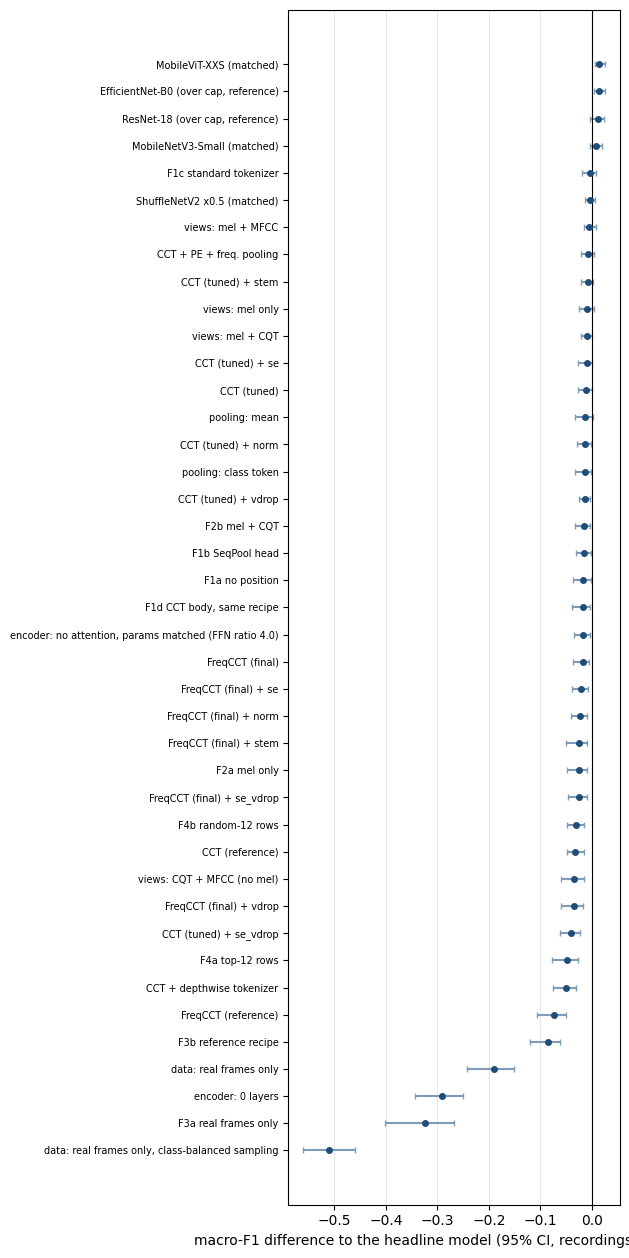

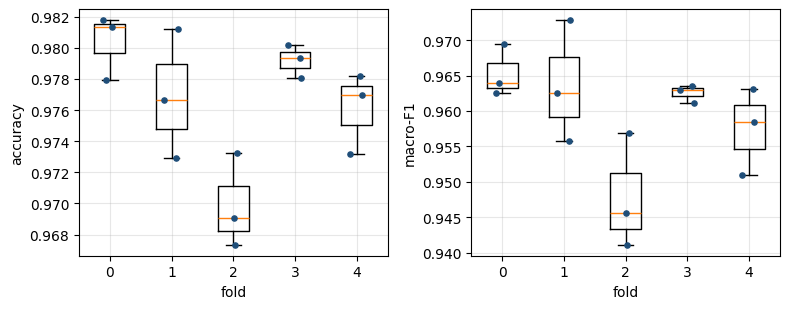

In [16]:
# CELL 11a | Statistical figures for the headline model: paired differences (forest) and the 3 seeds x 5 folds spread.
import matplotlib.pyplot as plt
R = collect(); head_tid = f"M_{HEAD_KEY}_paper_f0_s0"; ih = np.load(os.path.join(trial_dir(head_tid), "preds.npz"))["test_idx"]
ph = np.load(os.path.join(trial_dir(head_tid), "preds.npz"))["test_probs"].argmax(1); yt = y[ih]; rec = M["rec_idx"].values[ih]
others = R[(R.protocol == "paper") & (R.fold == 0) & (R.seed == 0) & (R.trial != head_tid) & R.phase.isin(["main", "A", "E", "F", "H", "fusion"])].copy()
E_ = others[others.phase == "E"]
if len(E_): others = pd.concat([others[others.phase != "E"], E_.sort_values("val_macro_f1", ascending=False).groupby("arch").head(1)])
rows = []
for r in others.itertuples():
    z = np.load(os.path.join(trial_dir(r.trial), "preds.npz"))
    if not np.array_equal(z["test_idx"], ih): continue                                  # same test frames only (the real-only runs share them too)
    d, lo, hi = bspc.bootstrap_diff(yt, z["test_probs"].argmax(1), ph, rec, B=300)
    rows.append(dict(model=r.label, group=r.phase, diff=d, lo=lo, hi=hi))
Fz = pd.DataFrame(rows).sort_values("diff"); save_table(Fz.round(4), "table19_paired_macroF1_vs_headline_fold0", show=False)
fig, ax = plt.subplots(figsize=(6.4, 0.28 * len(Fz) + 1.2))
ax.errorbar(Fz["diff"], range(len(Fz)), xerr=[Fz["diff"] - Fz["lo"], Fz["hi"] - Fz["diff"]], fmt="o", color="#1f4e79", ecolor="#7f9bb8", capsize=2, ms=4)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(range(len(Fz))); ax.set_yticklabels(Fz.model, fontsize=7); ax.set_xlabel("macro-F1 difference to the headline model (95% CI, recordings resampled)")
ax.grid(axis="x", alpha=.3); fig.tight_layout(); save_fig(fig, "figP3_forest_vs_headline")
Rh = R[(R.model == HEAD_KEY) & (R.phase == "main") & (R.protocol == "paper")]
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
for a, c, t in zip(ax, ("test_accuracy", "test_macro_f1"), ("accuracy", "macro-F1")):
    folds = sorted(Rh.fold.unique()); a.boxplot([Rh[Rh.fold == f][c] for f in folds], positions=folds, widths=.5, showfliers=False)
    a.scatter(Rh.fold + np.random.default_rng(0).uniform(-.12, .12, len(Rh)), Rh[c], s=14, color="#1f4e79", zorder=3); a.set_xlabel("fold"); a.set_ylabel(t); a.grid(alpha=.3)
fig.tight_layout(); save_fig(fig, "figP4_seed_fold_spread")


## 12. Learning curves

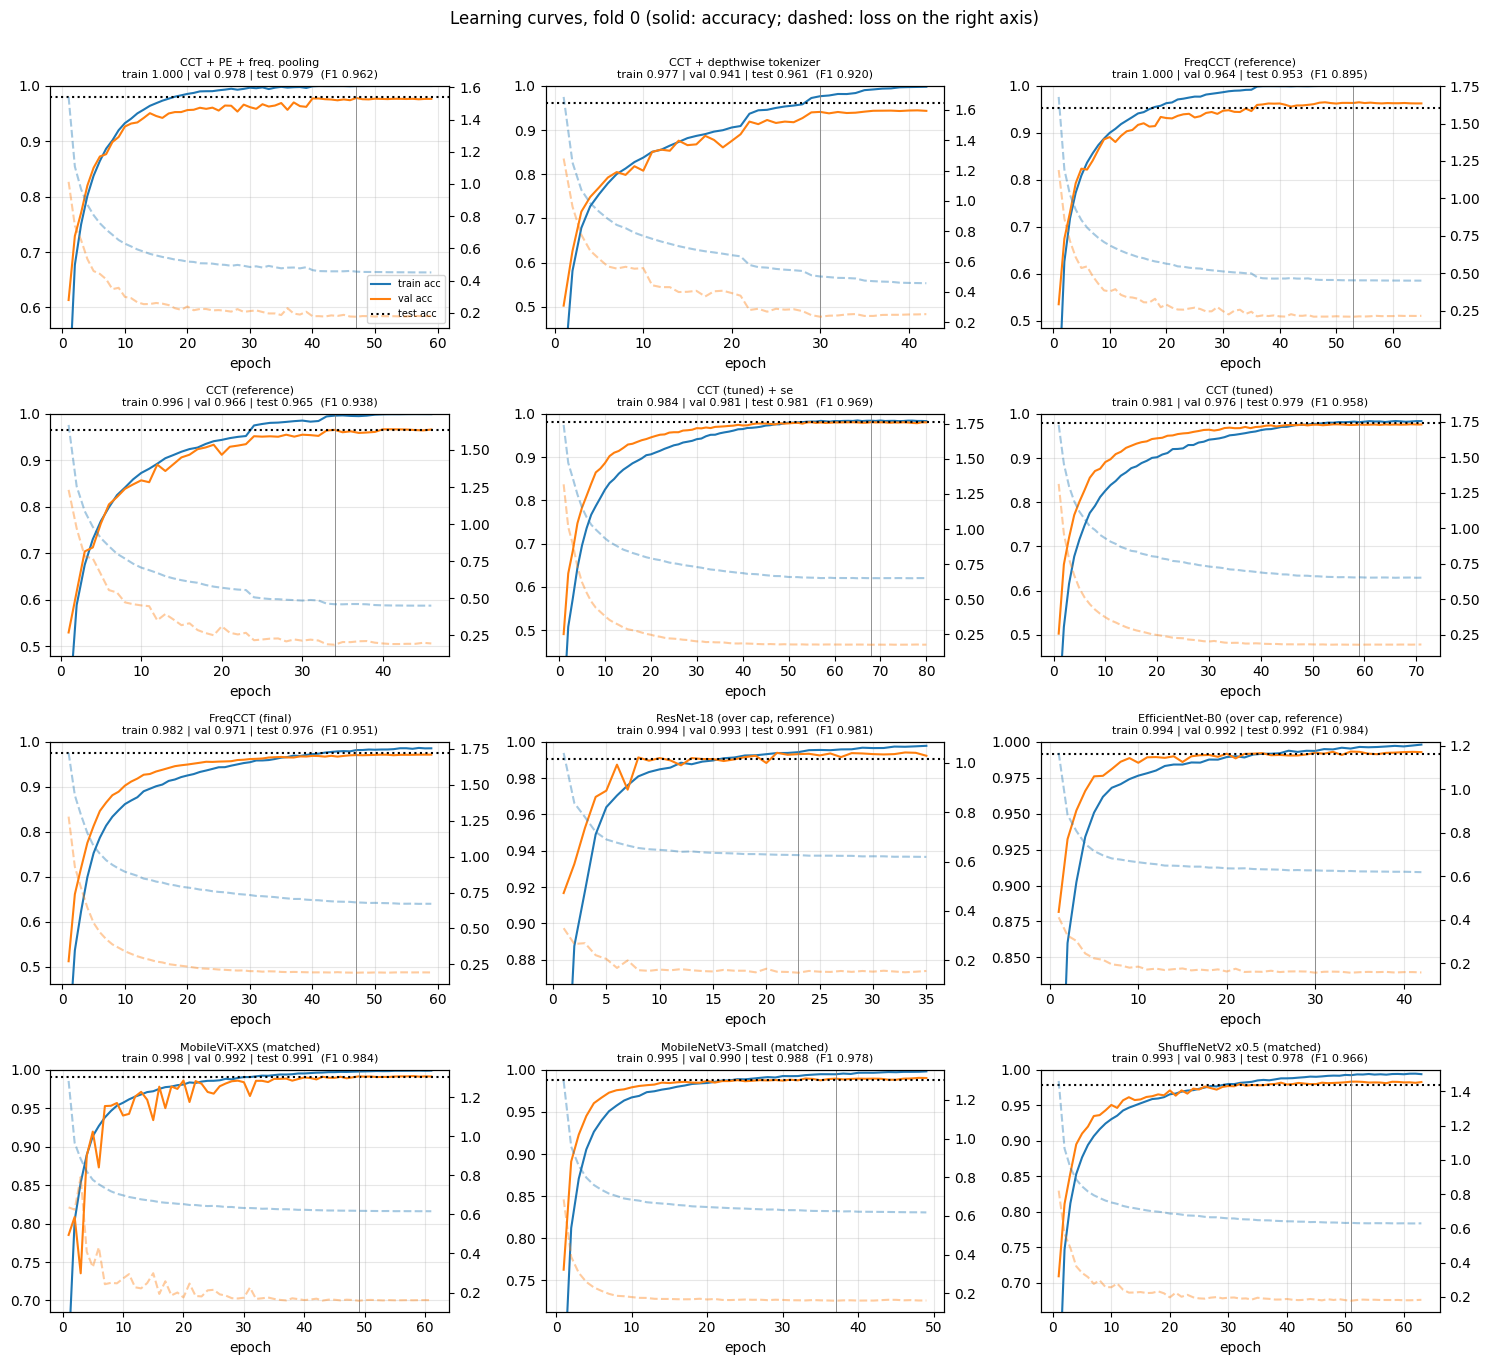

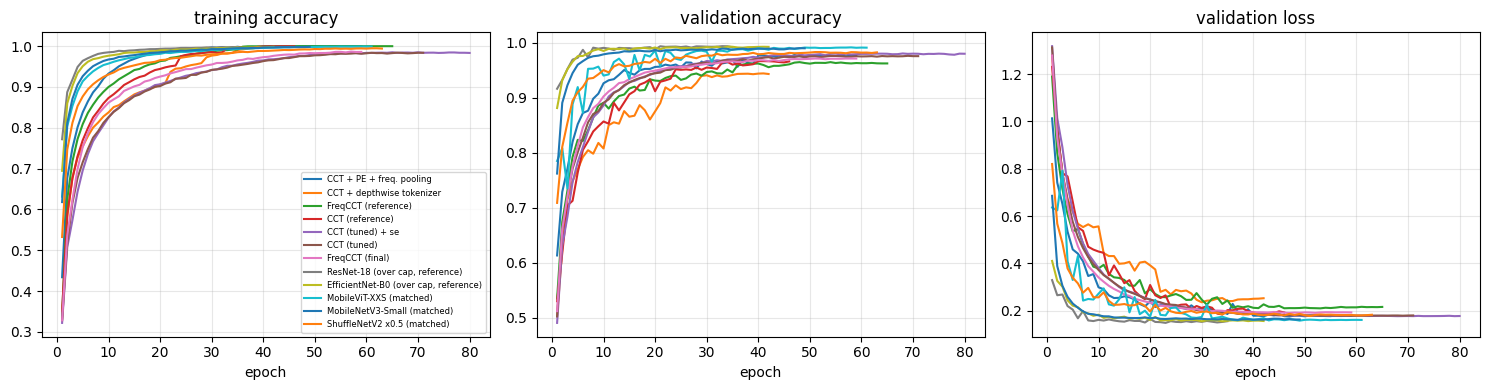


[table08b_accuracy_train_val_test]  saved: tables/table08b_accuracy_train_val_test.csv


,label,best_epoch,epochs_run,train_acc,val_acc,test_acc,test_macro_f1
0,CCT + PE + freq. pooling,47,59,0.9997,0.9782,0.9792,0.9619
1,CCT + depthwise tokenizer,30,42,0.9768,0.9412,0.9606,0.9198
2,FreqCCT (reference),53,65,0.9998,0.9637,0.9534,0.8954
3,CCT (reference),34,46,0.9963,0.9657,0.9652,0.9377
4,CCT (tuned) + se,68,80,0.9843,0.9809,0.9813,0.9695
5,CCT (tuned),59,71,0.9814,0.9759,0.9792,0.9584
6,FreqCCT (final),47,59,0.9819,0.9708,0.9758,0.9514
7,"ResNet-18 (over cap, reference)",23,35,0.9944,0.9933,0.9907,0.9808
8,"EfficientNet-B0 (over cap, reference)",30,42,0.9937,0.9924,0.9915,0.9841
9,MobileViT-XXS (matched),49,61,0.9979,0.9917,0.9911,0.9843


'/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/tables/table08b_accuracy_train_val_test.csv'

In [17]:
# CELL 12 | Learning curves of every model: train / validation loss and accuracy per epoch, with the final train / validation / test numbers.
import matplotlib.pyplot as plt
R = collect(); sel = R[(R.protocol == "paper") & (R.fold == 0) & (R.seed == 0) & (R.phase.isin(["main", "A"]) | ((R.phase == "E")))].copy()
E = sel[sel.phase == "E"]
if len(E): sel = pd.concat([sel[sel.phase != "E"], E.sort_values("val_macro_f1", ascending=False).groupby("arch").head(1)])
sel = sel.reset_index(drop=True); H = {r.trial: pd.read_csv(os.path.join(trial_dir(r.trial), "history.csv")) for r in sel.itertuples()}
def final_line(r):
    h = H[r.trial].iloc[int(r.best_epoch) - 1]
    return f"train {h.train_acc:.3f} | val {h.val_acc:.3f} | test {r.test_accuracy:.3f}  (F1 {r.test_macro_f1:.3f})"
n = len(sel); cols = 3; rws = int(np.ceil(n / cols))
fig, axs = plt.subplots(rws, cols, figsize=(5 * cols, 3.4 * rws), squeeze=False)
for ax, r in zip(axs.flat, sel.itertuples()):
    h = H[r.trial]; ax.plot(h.epoch, h.train_acc, label="train acc"); ax.plot(h.epoch, h.val_acc, label="val acc")
    ax.axhline(r.test_accuracy, color="k", ls=":", label="test acc"); ax.axvline(r.best_epoch, color="gray", lw=.6)
    ax2 = ax.twinx(); ax2.plot(h.epoch, h.train_loss, "--", color="tab:blue", alpha=.4); ax2.plot(h.epoch, h.val_loss, "--", color="tab:orange", alpha=.4)
    ax.set_title(f"{r.label}\n{final_line(r)}", fontsize=8); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.set_ylim(max(0, min(h.val_acc.min(), r.test_accuracy) - .05), 1.0)
axs.flat[0].legend(fontsize=7, loc="lower right")
for ax in list(axs.flat)[n:]: ax.axis("off")
fig.suptitle("Learning curves, fold 0 (solid: accuracy; dashed: loss on the right axis)", y=1.0); fig.tight_layout(); save_fig(fig, "figC1_learning_curves_individual")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for r in sel.itertuples():
    h = H[r.trial]; ax[0].plot(h.epoch, h.train_acc, label=r.label); ax[1].plot(h.epoch, h.val_acc); ax[2].plot(h.epoch, h.val_loss)
ax[0].set_title("training accuracy"); ax[1].set_title("validation accuracy"); ax[2].set_title("validation loss")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(fontsize=6); fig.tight_layout(); save_fig(fig, "figC2_learning_curves_together")
tab = sel[["label", "best_epoch", "epochs_run"]].copy()
tab["train_acc"] = [H[t].iloc[int(b) - 1].train_acc for t, b in zip(sel.trial, sel.best_epoch)]; tab["val_acc"] = sel.val_acc; tab["test_acc"] = sel.test_accuracy
tab["test_macro_f1"] = sel.test_macro_f1; save_table(tab.round(4), "table08b_accuracy_train_val_test")


## 12a. Standalone figures per model (v2)

In [18]:
# CELL 12a | One standalone figure per model and per plot type (fold 0, seed 0, real test frames): confusion, ROC, precision-recall, learning curve, reliability.
# Models: every main model, the FreqCCT/CCT reference runs of phase A, and the best learning rate of every baseline. Files: figures/figM_<model>_<plot>.png|pdf|svg
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
R = collect(); S_ = R[(R.protocol == "paper") & (R.fold == 0) & (R.seed == 0) & R.phase.isin(["main", "A", "E"])].copy()
E_ = S_[S_.phase == "E"]
if len(E_): S_ = pd.concat([S_[S_.phase != "E"], E_.sort_values("val_macro_f1", ascending=False).groupby("arch").head(1)])
COL = "#1f4e79"; mrows = []
def figname(r): return "figM_" + "".join(ch if ch.isalnum() else "_" for ch in r.label.lower()).strip("_")
for r in S_.itertuples():
    z = np.load(os.path.join(trial_dir(r.trial), "preds.npz")); P, yt = z["test_probs"], y[z["test_idx"]]; pred = P.argmax(1); nm = figname(r); present = [c for c in range(7) if (yt == c).any()]
    cm = np.array(json.load(open(os.path.join(trial_dir(r.trial), "metrics.json")))["confusion"], float); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, a = plt.subplots(figsize=(4.4, 4)); a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(7)); a.set_yticks(range(7)); a.set_xticklabels([c[:6] for c in CLASSES], rotation=55, ha="right"); a.set_yticklabels([c[:6] for c in CLASSES])
    for i in range(7):
        for j in range(7):
            if cm[i, j]: a.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > .5 else "black")
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(r.label, fontsize=9); save_fig(fig, nm + "_confusion", show=False)
    fig, a = plt.subplots(figsize=(4.2, 4)); aucs = []
    for c in present:
        fpr, tpr, _ = roc_curve(yt == c, P[:, c]); aucs.append(auc(fpr, tpr)); a.plot(fpr, tpr, lw=1, label=CLASSES[c][:6])
    a.plot([0, 1], [0, 1], "k:", lw=.7); a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate"); a.set_title(r.label, fontsize=9); a.legend(fontsize=6, frameon=False, loc="lower right")
    save_fig(fig, nm + "_roc", show=False)
    fig, a = plt.subplots(figsize=(4.2, 4)); aps = []
    for c in present:
        pr, rc, _ = precision_recall_curve(yt == c, P[:, c]); aps.append(average_precision_score(yt == c, P[:, c])); a.plot(rc, pr, lw=1, label=CLASSES[c][:6])
    a.set_xlabel("recall"); a.set_ylabel("precision"); a.set_title(r.label, fontsize=9); a.legend(fontsize=6, frameon=False, loc="lower left"); save_fig(fig, nm + "_pr", show=False)
    h = pd.read_csv(os.path.join(trial_dir(r.trial), "history.csv")); fig, a = plt.subplots(1, 2, figsize=(7.4, 3))
    a[0].plot(h.epoch, h.train_loss, color=COL, label="train"); a[0].plot(h.epoch, h.val_loss, color="#c0504d", label="validation"); a[0].set_ylabel("loss")
    a[1].plot(h.epoch, h.train_acc, color=COL); a[1].plot(h.epoch, h.val_acc, color="#c0504d"); a[1].set_ylabel("accuracy")
    for q in a: q.axvline(r.best_epoch, color="gray", lw=.6); q.set_xlabel("epoch")
    a[0].legend(frameon=False, fontsize=7); fig.suptitle(r.label, fontsize=9); fig.tight_layout(); save_fig(fig, nm + "_curves", show=False)
    conf, ok = P.max(1), (pred == yt); edges = np.linspace(0, 1, 11); bi = np.clip(np.digitize(conf, edges) - 1, 0, 9); ece = 0.0; xs_, ys_ = [], []
    for b in range(10):
        m_ = bi == b
        if m_.any(): ece += m_.mean() * abs(ok[m_].mean() - conf[m_].mean()); xs_.append(conf[m_].mean()); ys_.append(ok[m_].mean())
    fig, a = plt.subplots(figsize=(4, 4)); a.plot([0, 1], [0, 1], "k:", lw=.7); a.plot(xs_, ys_, "o-", color=COL, ms=4); a.set_xlabel("confidence"); a.set_ylabel("accuracy"); a.set_title(r.label, fontsize=9)
    save_fig(fig, nm + "_reliability", show=False)
    mrows.append(dict(model=r.label, accuracy=r.test_accuracy, macro_F1=r.test_macro_f1, MCC=r.test_mcc, bal_acc=r.test_bal_acc, macro_AUC=float(np.mean(aucs)), macro_AP=float(np.mean(aps)), ECE=ece,
                      rec_vote_acc=r.rec_accuracy, params=int(r.params), MFLOPs=round(r.mflops, 1)))
save_table(pd.DataFrame(mrows).round(4), "table20_model_metrics_auc_ap_ece_fold0"); print(len(S_), "models x 5 plot types saved to figures/ (figM_*)")



[table20_model_metrics_auc_ap_ece_fold0]  saved: tables/table20_model_metrics_auc_ap_ece_fold0.csv


,model,accuracy,macro_F1,MCC,bal_acc,macro_AUC,macro_AP,ECE,rec_vote_acc,params,MFLOPs
0,CCT + PE + freq. pooling,0.9792,0.9619,0.9332,0.9824,0.9978,0.9854,0.1125,0.9802,190151,124.2
1,CCT + depthwise tokenizer,0.9606,0.9198,0.8766,0.9640,0.9954,0.9677,0.0698,0.9699,141000,83.0
2,FreqCCT (reference),0.9534,0.8954,0.8610,0.9692,0.9957,0.9717,0.0924,0.9643,158023,83.0
3,CCT (reference),0.9652,0.9377,0.8896,0.9664,0.9945,0.9608,0.0740,0.9723,173128,124.2
4,CCT (tuned) + se,0.9813,0.9695,0.9410,0.9907,0.9994,0.9931,0.1171,0.9849,173187,124.2
5,CCT (tuned),0.9792,0.9584,0.9337,0.9848,0.9994,0.9923,0.1107,0.9834,173128,124.2
6,FreqCCT (final),0.9758,0.9514,0.9244,0.9867,0.9992,0.9925,0.1250,0.9834,124999,72.5
7,"ResNet-18 (over cap, reference)",0.9907,0.9808,0.9697,0.9948,0.9998,0.9971,0.1206,0.9929,11180103,773.8
8,"EfficientNet-B0 (over cap, reference)",0.9915,0.9841,0.9718,0.9901,0.9997,0.9954,0.1227,0.9921,4016515,168.2
9,MobileViT-XXS (matched),0.9911,0.9843,0.9707,0.9920,0.9999,0.9989,0.1230,0.9937,953271,109.6


12 models x 5 plot types saved to figures/ (figM_*)


## 13. Efficiency

In [19]:
# CELL 13 | Efficiency: parameters, MFLOPs (counted and formula), CPU latency (1 thread), peak activation, training time, feature-extraction time.
import torch
torch.set_num_threads(1)
R = collect(); rows = []
cands = [("CCT (reference)", dict(MAIN_CORE["cct_ref"])), ("FreqCCT (final)", dict(MAIN_CORE["freqcct_final"]))]
if "cct_tuned" in MAIN_CORE: cands.insert(1, ("CCT (tuned)", dict(MAIN_CORE["cct_tuned"])))
for name, _ in [(b, 0) for b in bspc.BASELINES]:
    cands.append((bspc.BASELINES[name], dict(arch=name, scale=2, pretrained=False)))
for lab, spec in cands:
    m = bspc.build_model(spec); sh = (bspc.n_channels_of(spec), 4 * bspc.n_rows_of(spec), 40); lat = bspc.cpu_latency_ms(m, sh, reps=60 if SMOKE else 300)
    tm = R[R.label.str.startswith(lab.split(" (")[0]) & (R.protocol == "paper") & (R.fold == 0) & (R.seed == 0)] if len(R) else R
    rows.append(dict(model=lab, params=bspc.n_params(m), mflops_counted=round(bspc.counted_mflops(m, sh), 1), mflops_formula=round(bspc.spec_mflops(spec), 1),
                     latency_ms_median=round(lat[0], 2), latency_ms_p90=round(lat[1], 2), peak_activation_kB=round(bspc.peak_activation_kb(m, sh), 1),
                     weights_kB_fp32=round(bspc.n_params(m) * 4 / 1e3, 1)))
t08 = pd.DataFrame(rows); save_table(t08, "table08_efficiency")
try:                                                              # share of the feature extraction (one 5 s frame)
    import librosa, time as _t
    xx = np.random.randn(20000).astype(np.float32); tt = {}
    for nm, fn in (("mel", lambda: librosa.feature.melspectrogram(y=xx, sr=4000, n_fft=1024, hop_length=524, n_mels=64)),
                   ("cqt", lambda: librosa.cqt(xx, sr=4000, hop_length=512, fmin=32.7, n_bins=64, bins_per_octave=12)),
                   ("mfcc", lambda: librosa.feature.mfcc(y=xx, sr=4000, n_mfcc=30, n_mels=30, n_fft=1024, hop_length=512))):
        fn(); t0 = _t.perf_counter(); [fn() for _ in range(5)]; tt[nm] = (_t.perf_counter() - t0) / 5 * 1e3
    save_table(pd.DataFrame([dict(step=k, ms_per_frame=round(v, 2), share=f"{100*v/sum(tt.values()):.1f}%") for k, v in tt.items()]), "table08c_feature_extraction_time")
except Exception as e: print("feature-extraction timing skipped:", type(e).__name__)



[table08_efficiency]  saved: tables/table08_efficiency.csv


,model,params,mflops_counted,mflops_formula,latency_ms_median,latency_ms_p90,peak_activation_kB,weights_kB_fp32
0,CCT (reference),173128,124.2,124.2,6.41,7.95,655.4,692.5
1,CCT (tuned),173128,124.2,124.2,6.43,7.21,655.4,692.5
2,FreqCCT (final),124999,72.5,72.5,5.81,6.57,655.4,500.0
3,ShuffleNetV2 x0.5,348967,17.2,NaN,9.11,11.57,245.8,1395.9
4,MNASNet 0.5,946479,45.2,NaN,7.80,8.57,245.8,3785.9
5,MobileNetV3-Small,931047,24.5,NaN,6.84,7.71,184.3,3724.2
6,MobileViT-XXS,953271,109.6,NaN,13.96,16.14,327.7,3813.1
7,EfficientNet-B0,4016515,168.2,NaN,16.06,17.95,983.0,16066.1
8,ResNet-18,11180103,773.8,NaN,19.63,21.93,655.4,44720.4



[table08c_feature_extraction_time]  saved: tables/table08c_feature_extraction_time.csv


,step,ms_per_frame,share
0,mel,2.81,9.5%
1,cqt,25.00,84.4%
2,mfcc,1.80,6.1%


## 14. Explainability 1/3 (X1 to X4)

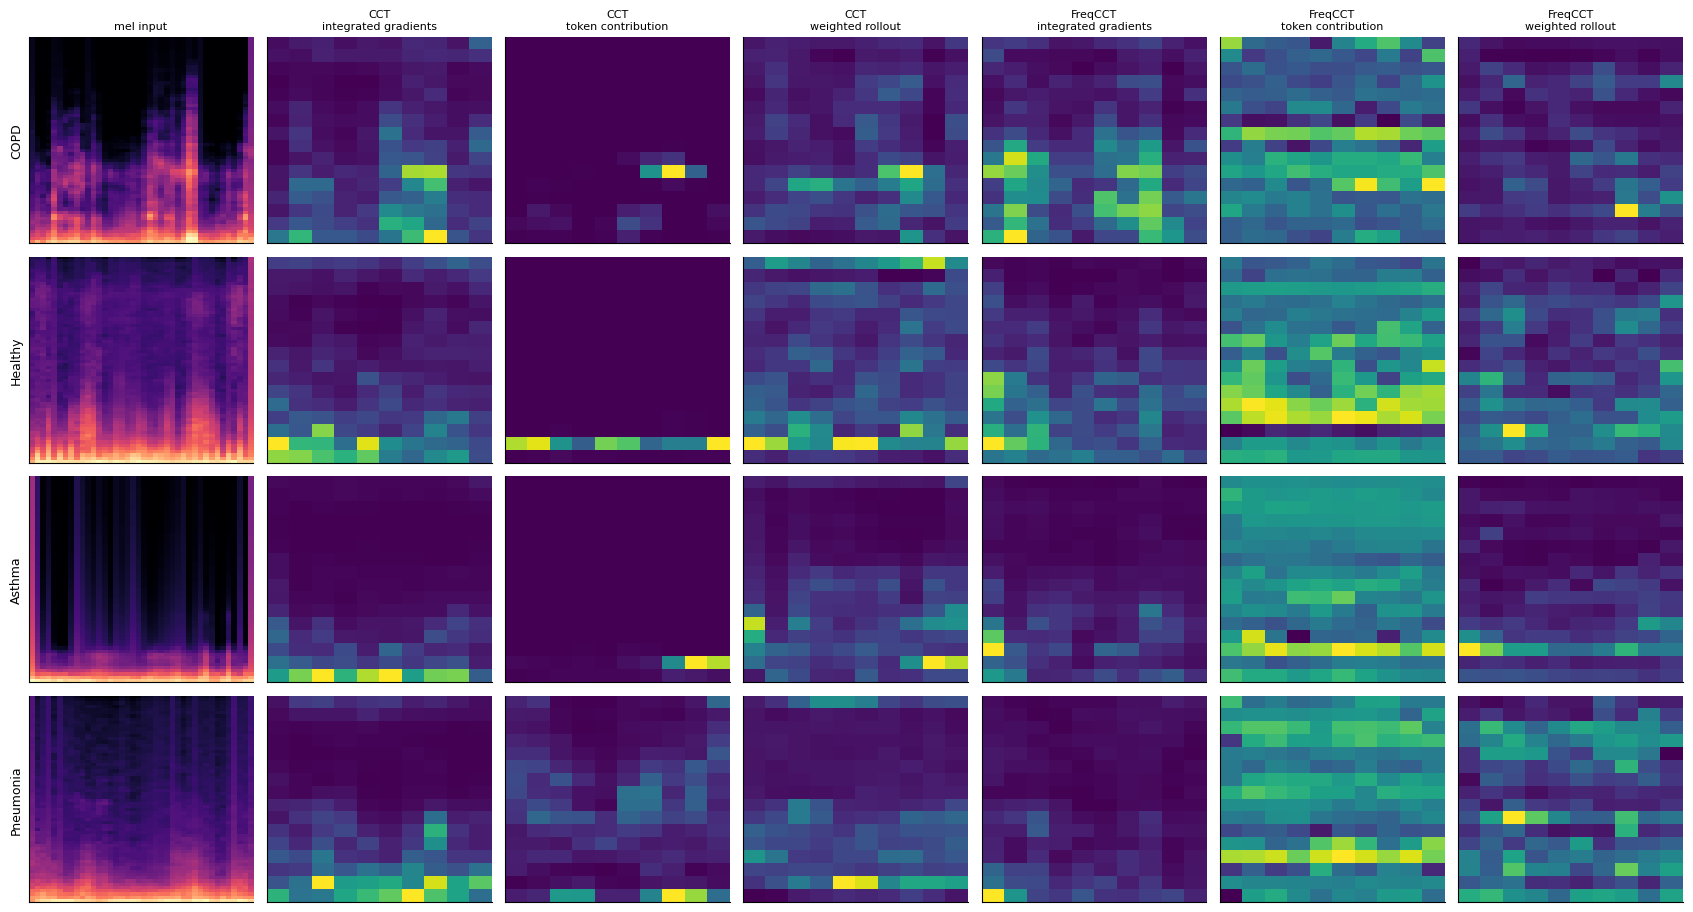

test   model                                    metric  value
  X3     CCT                   locality ratio, layer 1 0.9249
  X3     CCT                   locality ratio, layer 2 1.0733
  X3     CCT                   locality ratio, layer 3 1.0589
  X3     CCT                   locality ratio, layer 4 1.0563
  X3 FreqCCT                   locality ratio, layer 1 0.8435
  X3 FreqCCT                   locality ratio, layer 2 1.0940
  X3 FreqCCT                   locality ratio, layer 3 1.0004
  X3 FreqCCT                   locality ratio, layer 4 0.9938
  X4     CCT        deletion AUC (IG), lower is better 0.2200
  X4     CCT      insertion AUC (IG), higher is better 0.4296
  X4     CCT   deletion AUC (CONTRIB), lower is better 0.2257
  X4     CCT insertion AUC (CONTRIB), higher is better 0.2936
  X4     CCT   deletion AUC (ROLLOUT), lower is better 0.2223
  X4     CCT insertion AUC (ROLLOUT), higher is better 0.2885
  X4     CCT    deletion AUC (CWROLL), lower is better 0.2099
  X4    

In [20]:
# CELL 14 | Explainability 1 of 3: X1 integrated gradients, X2 token-contribution maps and contribution-weighted rollout,
# X3 attention locality, X4 deletion / insertion. Fold 0 test frames only, final CCT and final FreqCCT.
import torch, matplotlib.pyplot as plt
_trap = getattr(np, "trapezoid", None) or np.trapz
_cct_k = "cct_tuned" if "cct_tuned" in MAIN_CORE else "cct_ref"; _fq_k = "freqcct_final"
if MAIN_CORE[HEAD_KEY]["arch"] == "cct": _cct_k = HEAD_KEY                  # v2: the dynamically selected headline model is the one explained
else: _fq_k = HEAD_KEY
XAI_KEY = {"CCT": _cct_k, "FreqCCT": _fq_k}
XM = {n: bspc.load_model(MAIN_CORE[k], trial_dir(f"M_{k}_paper_f0_s0"), device) for n, k in XAI_KEY.items()}
te0 = SP["paper"][0][2]                                                    # real test frames of fold 0
rs = np.random.default_rng(0)
XS = np.sort(np.concatenate([rs.choice(te0[y[te0] == c], size=min(40, int((y[te0] == c).sum())), replace=False) for c in range(7) if (y[te0] == c).any()]))
ES = np.sort(rs.choice(te0, size=min(1200, len(te0)), replace=False))
xs = Xg[torch.as_tensor(XS, device=device)].float(); ys = torch.as_tensor(y[XS], device=device)
XAI_ROWS = []
def add(test, model, metric, value): XAI_ROWS.append(dict(test=test, model=model, metric=metric, value=value))
def pred_of(model, x):
    with torch.no_grad(): return torch.cat([model(x[i:i + 512]).argmax(1) for i in range(0, len(x), 512)])
STEPS = 8 if SMOKE else 24

def all_maps(model, x, tgt):
    c = model.contributions(x, tgt)
    return dict(IG=bspc.input_to_token(bspc.integrated_gradients(model, x, tgt, steps=STEPS)), CONTRIB=c,
                ROLLOUT=bspc.rollout_map(model, x), CWROLL=bspc.rollout_map(model, x, c))

MAPS, PRED = {}, {}
for n, mdl in XM.items():
    PRED[n] = pred_of(mdl, xs); MAPS[n] = all_maps(mdl, xs, PRED[n])
    add("X0", n, "accuracy on the explanation sample", float((PRED[n] == ys).float().mean()))

# ---- X2 example figure: one frame per class, input and three maps per model ----
show = [c for c in (0, 1, 2, 3) if (y[XS] == c).any()]; ex = [int(np.where(y[XS] == c)[0][0]) for c in show]
fig, axs = plt.subplots(len(ex), 7, figsize=(17, 2.3 * len(ex)), squeeze=False)
for i, e in enumerate(ex):
    axs[i, 0].imshow(xs[e, 0].cpu(), aspect="auto", origin="lower", cmap="magma"); axs[i, 0].set_ylabel(CLASSES[int(y[XS][e])], fontsize=9)
    k = 1
    for n in XM:
        for nm in ("IG", "CONTRIB", "CWROLL"):
            mp = MAPS[n][nm][e].detach().cpu().numpy(); axs[i, k].imshow(mp, aspect="auto", origin="lower", cmap="viridis"); k += 1
            if i == 0: axs[i, k - 1].set_title(f"{n}\n{ {'IG':'integrated gradients','CONTRIB':'token contribution','CWROLL':'weighted rollout'}[nm] }", fontsize=8)
axs[0, 0].set_title("mel input", fontsize=8)
for a in axs.flat: a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); save_fig(fig, "figX1_explanation_examples")

# ---- X3 attention locality: observed mean token distance / distance under uniform attention (below 1 = local) ----
rr, cc = np.divmod(np.arange(160), 10)
for n, mdl in XM.items():
    nf = mdl.nf; rr, cc = np.divmod(np.arange(nf * mdl.nt), mdl.nt)
    D = torch.as_tensor(np.abs(rr[:, None] - rr[None]) + np.abs(cc[:, None] - cc[None]), dtype=torch.float32, device=device)
    for li, A in enumerate(bspc.attention_stack(mdl, xs[:64])):
        add("X3", n, f"locality ratio, layer {li + 1}", float(((A * D).sum(-1).mean() / D.mean()).cpu()))

# ---- X4 deletion / insertion on correctly classified frames ----
fr = np.linspace(0, 1, 11)
def curve(model, x, tgt, score, mode):
    B, n = x.shape[0], score.flatten(1).shape[1]; order = score.flatten(1).argsort(1, descending=True); out = []
    for f in fr:
        k = int(round(f * n)); m = torch.zeros(B, n, device=x.device);
        if k: m.scatter_(1, order[:, :k], 1.0)
        m = bspc.token_to_input(m.view(B, model.nf, model.nt))
        xx = x * (1 - m) if mode == "del" else x * m
        with torch.no_grad(): out.append(F.softmax(model(xx), 1).gather(1, tgt[:, None])[:, 0].cpu().numpy())
    return np.stack(out, 1)                                             # (B, steps)
import torch.nn.functional as F
for n, mdl in XM.items():
    ok = (PRED[n] == ys); x, t = xs[ok], PRED[n][ok]
    mp = {k: v[ok] for k, v in MAPS[n].items()}; mp["RANDOM"] = torch.rand_like(mp["IG"])
    for nm, sc in mp.items():
        d, ins = curve(mdl, x, t, sc, "del"), curve(mdl, x, t, sc, "ins")
        add("X4", n, f"deletion AUC ({nm}), lower is better", float(_trap(d.mean(0), fr))); add("X4", n, f"insertion AUC ({nm}), higher is better", float(_trap(ins.mean(0), fr)))
print(pd.DataFrame(XAI_ROWS).query("test in ['X3','X4']").round(4).to_string(index=False))


## 15. Explainability 2/3 (X5 to X7)

In [21]:
# CELL 15 | Explainability 2 of 3: X5 randomization check, X6 channel Shapley, X7 band attribution (Hz).
import copy, torch.nn as nn
from scipy.stats import spearmanr
from math import factorial
# ---- X5: re-initialise the model from the head down to the tokenizer; a faithful map must stop resembling the original ----
THRESHOLD_X5 = 0.30        # declared before computing: median Spearman after the FULL cascade must be below this
def reinit(mod):
    for m in mod.modules():
        if isinstance(m, nn.MultiheadAttention): m._reset_parameters()
        elif hasattr(m, "reset_parameters"): m.reset_parameters()
for n, mdl in XM.items():
    m2 = copy.deepcopy(mdl); xb = xs[::3][:60]; tg = PRED[n][::3][:60]; base = all_maps(mdl, xb, tg)
    groups = [("head", [getattr(m2, a) for a in ("fc", "norm", "pool", "tp") if hasattr(m2, a)])] + \
             [(f"block {i + 1}", [m2.blocks[i]]) for i in reversed(range(len(m2.blocks)))] + [("tokenizer + position", [m2.tok])]
    for gname, mods in groups:
        for m in mods: reinit(m)
        if gname.startswith("tokenizer") and getattr(m2, "pos", None) is not None: nn.init.trunc_normal_(m2.pos, std=0.02)
        new = all_maps(m2, xb, tg)
        for nm in ("IG", "CONTRIB", "CWROLL"):
            rho = [spearmanr(base[nm][i].flatten().detach().cpu(), new[nm][i].flatten().detach().cpu())[0] for i in range(len(xb))]
            add("X5", n, f"Spearman after re-initialising up to {gname} ({nm})", float(np.nanmedian(rho)))
    for nm in ("IG", "CONTRIB", "CWROLL"):
        v = [r["value"] for r in XAI_ROWS if r["test"] == "X5" and r["model"] == n and r["metric"].endswith(f"({nm})")][-1]
        add("X5", n, f"PASS (<{THRESHOLD_X5}) after full cascade ({nm})", bool(v < THRESHOLD_X5))
# ---- X6: exact Shapley value of each input channel for macro-F1 (absent channel = its training mean) ----
chmean = Xg[torch.as_tensor(np.random.default_rng(1).choice(SP["paper"][0][0], size=min(3000, len(SP["paper"][0][0])), replace=False), device=device)].float().mean((0, 2, 3))
xl = Xg[torch.as_tensor(ES, device=device)].float(); yl = y[ES]
for n, mdl in XM.items():
    def v(S):
        xx = xl.clone()
        for c in range(3):
            if c not in S: xx[:, c] = chmean[c]
        return bspc.macro_f1_present(yl, pred_of(mdl, xx).cpu().numpy())
    V = {S: v(S) for r in range(4) for S in map(frozenset, __import__("itertools").combinations(range(3), r))}
    phi = [sum(factorial(len(S)) * factorial(2 - len(S)) / factorial(3) * (V[S | {c}] - V[S]) for S in V if c not in S) for c in range(3)]
    tot = sum(phi)
    for c, nm in enumerate(("mel", "CQT", "MFCC")): add("X6", n, f"Shapley share of macro-F1, {nm}", float(phi[c] / tot) if tot > 0 else float("nan"))
# ---- X7: where in frequency does the evidence sit? |IG| per input row, by class; Hz ranges of the 16 token rows ----
hz = bspc.token_row_hz(); rows = []
for n, mdl in XM.items():
    ig = bspc.integrated_gradients(mdl, xs, PRED[n], steps=STEPS).abs()           # (B,3,64,40)
    for ch, chn in enumerate(("mel", "CQT", "MFCC")):
        share = ig[:, ch].view(len(xs), 16, 4, 40).sum((2, 3)); share = share / (share.sum(1, keepdim=True) + 1e-9)
        for c in range(7):
            sel = (ys == c).cpu().numpy()
            if not sel.any(): continue
            s = share[torch.as_tensor(sel, device=device)].mean(0).cpu().numpy()
            for r in range(16):
                rows.append(dict(model=n, channel=chn, cls=CLASSES[c], token_row=r, share=round(float(s[r]), 4),
                                 hz_range=(f"{hz.mel_lo_hz[r]}-{hz.mel_hi_hz[r]}" if chn == "mel" else f"{hz.cqt_lo_hz[r]}-{hz.cqt_hi_hz[r]}" if chn == "CQT" else "n/a")))
t12b = pd.DataFrame(rows); save_table(t12b, "table12b_band_attribution", show=False)
top = t12b[t12b.channel == "mel"].sort_values("share", ascending=False).groupby(["model", "cls"]).head(3).sort_values(["model", "cls", "share"], ascending=[True, True, False])
print("[table12b_band_attribution] saved; top 3 mel token rows per class:"); display(top)
print(pd.DataFrame(XAI_ROWS).query("test in ['X5','X6']").round(4).to_string(index=False))


[table12b_band_attribution] saved; top 3 mel token rows per class:


,model,channel,cls,token_row,share,hz_range
32,CCT,mel,Asthma,0,0.4924,26-103
33,CCT,mel,Asthma,1,0.1749,129-206
34,CCT,mel,Asthma,2,0.1299,232-309
80,CCT,mel,Bronchiectasis,0,0.3143,26-103
81,CCT,mel,Bronchiectasis,1,0.1213,129-206
82,CCT,mel,Bronchiectasis,2,0.1043,232-309
96,CCT,mel,Bronchiolitis,0,0.3923,26-103
97,CCT,mel,Bronchiolitis,1,0.1427,129-206
98,CCT,mel,Bronchiolitis,2,0.0985,232-309
0,CCT,mel,COPD,0,0.2848,26-103


test   model                                                              metric     value
  X5     CCT                      Spearman after re-initialising up to head (IG)  0.877019
  X5     CCT                 Spearman after re-initialising up to head (CONTRIB)  0.215639
  X5     CCT                  Spearman after re-initialising up to head (CWROLL)  0.949795
  X5     CCT                   Spearman after re-initialising up to block 4 (IG)  0.868317
  X5     CCT              Spearman after re-initialising up to block 4 (CONTRIB)  0.177426
  X5     CCT               Spearman after re-initialising up to block 4 (CWROLL)  0.913934
  X5     CCT                   Spearman after re-initialising up to block 3 (IG)  0.863931
  X5     CCT              Spearman after re-initialising up to block 3 (CONTRIB)  -0.04303
  X5     CCT               Spearman after re-initialising up to block 3 (CWROLL)  0.804204
  X5     CCT                   Spearman after re-initialising up to block 2 (IG)  0.859712

## 16. Explainability 3/3 (X8 to X10, S1) and Table 12

In [22]:
# CELL 16 | Explainability 3 of 3: X8 shift / shuffle, X9 stationary-stripe test, X10 source probe, S1 Grad-CAM check. Then Table 12.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
xe = Xg[torch.as_tensor(ES, device=device)].float(); ye = y[ES]
# ---- X8: does the prediction survive moving or shuffling the evidence? ----
for n, mdl in XM.items():
    p0 = pred_of(mdl, xe)
    for k in (5, 10, 20): add("X8", n, f"prediction flips after circular time shift by {k} columns", float((pred_of(mdl, xe.roll(k, dims=3)) != p0).float().mean()))
    fl = []
    for s in range(3):
        perm = torch.as_tensor(np.random.default_rng(s).permutation(mdl.nf * mdl.nt), device=device)
        with torch.no_grad(): ps = torch.cat([mdl(xe[i:i + 512], perm=perm).argmax(1) for i in range(0, len(xe), 512)])
        fl.append(float((ps != p0).float().mean()))
    add("X8", n, "prediction flips after shuffling the 160 tokens (0 = order-blind)", float(np.mean(fl)))
# ---- X9: rows that carry constant energy over time (device hum / stationary stripe) ----
mel = Xg[torch.as_tensor(ES, device=device), 0].float(); rstd, rmean = mel.std(2), mel.mean(2)
thr = torch.quantile(rstd.flatten(), 0.05); stat = (rstd <= thr) & (rmean > rmean.median(1, keepdim=True).values)
for c in range(7):
    s = (ye == c)
    if s.any(): add("X9", "data", f"share of {CLASSES[c]} frames containing a stationary row", float(stat[torch.as_tensor(s, device=device)].any(1).float().mean()))
for n, mdl in XM.items():
    p0 = pred_of(mdl, xe); xx = xe.clone(); rnd = xe.clone(); g = torch.Generator(device="cpu").manual_seed(0)
    for b in range(len(xe)):
        r = torch.where(stat[b])[0]
        if len(r):
            xx[b, 0, r] = mel[b].mean(); rr_ = torch.as_tensor(np.random.default_rng(b).choice(64, len(r), replace=False), device=device); rnd[b, 0, rr_] = mel[b].mean()
    has = stat.any(1)
    if has.any():
        add("X9", n, "flip rate when stationary rows are flattened (frames that have them)", float((pred_of(mdl, xx)[has] != p0[has]).float().mean()))
        add("X9", n, "flip rate when the same number of random rows is flattened (control)", float((pred_of(mdl, rnd)[has] != p0[has]).float().mean()))
    ig = bspc.integrated_gradients(mdl, xs, PRED[n], steps=STEPS).abs()[:, 0].sum(2)           # (B,64) mel-row attribution
    melxs = xs[:, 0]; st = (melxs.std(2) <= thr) & (melxs.mean(2) > melxs.mean(2).median(1, keepdim=True).values)
    if st.any(): add("X9", n, "attribution on stationary rows / their share of rows (>1 = over-attended)", float(((ig * st).sum() / ig.sum()) / st.float().mean()))
# ---- X10: can the recording source be read from the frozen embedding? (patient-grouped, so patient identity cannot leak) ----
pk_e, src_e = M["pkey"].values[ES], M["source"].values[ES]
for n, mdl in XM.items():
    with torch.no_grad(): emb = torch.cat([mdl(xe[i:i + 512], ret_emb=True)[1].cpu() for i in range(0, len(xe), 512)]).numpy()
    if len(np.unique(src_e)) > 1 and len(np.unique(pk_e)) >= 5:
        accs = []
        for tr_, te_ in GroupKFold(5).split(emb, src_e, groups=pk_e):
            if len(np.unique(src_e[tr_])) < 2: continue
            accs.append((LogisticRegression(max_iter=300).fit(emb[tr_], src_e[tr_]).predict(emb[te_]) == src_e[te_]).mean())
        add("X10", n, "source predicted from the embedding (patient-grouped CV accuracy)", float(np.mean(accs)) if accs else float("nan"))
        add("X10", n, "majority-source baseline", float(pd.Series(src_e).value_counts(normalize=True).iloc[0]))
# ---- S1 supplement: Grad-CAM on the last tokenizer stage; how often is it blank? ----
for n, mdl in XM.items():
    store = {}; h = mdl.tok.net.register_forward_hook(lambda m_, i, o: store.__setitem__("a", o))
    with torch.enable_grad():
        z = mdl(xs); h.remove(); g, = torch.autograd.grad(z.gather(1, PRED[n][:, None]).sum(), store["a"])
    cam = F.relu((g.mean((2, 3), keepdim=True) * store["a"]).sum(1)).detach()
    add("S1", n, "share of frames with an all-zero Grad-CAM map", float((cam.flatten(1).sum(1) == 0).float().mean()))
t12 = pd.DataFrame(XAI_ROWS); t12["value"] = t12["value"].map(lambda v: round(v, 4) if isinstance(v, float) else v)
save_table(t12, "table12_xai_summary")



[table12_xai_summary]  saved: tables/table12_xai_summary.csv


,test,model,metric,value
0,X0,CCT,accuracy on the explanation sample,0.9876
1,X0,FreqCCT,accuracy on the explanation sample,0.9793
2,X3,CCT,"locality ratio, layer 1",0.9249
3,X3,CCT,"locality ratio, layer 2",1.0733
4,X3,CCT,"locality ratio, layer 3",1.0589
...,...,...,...,...
100,X10,CCT,majority-source baseline,0.5825
101,X10,FreqCCT,source predicted from the embedding (patient-g...,0.9642
102,X10,FreqCCT,majority-source baseline,0.5825
103,S1,CCT,share of frames with an all-zero Grad-CAM map,0.0331


'/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/tables/table12_xai_summary.csv'

## 16a. Explainability of the headline model (v2)

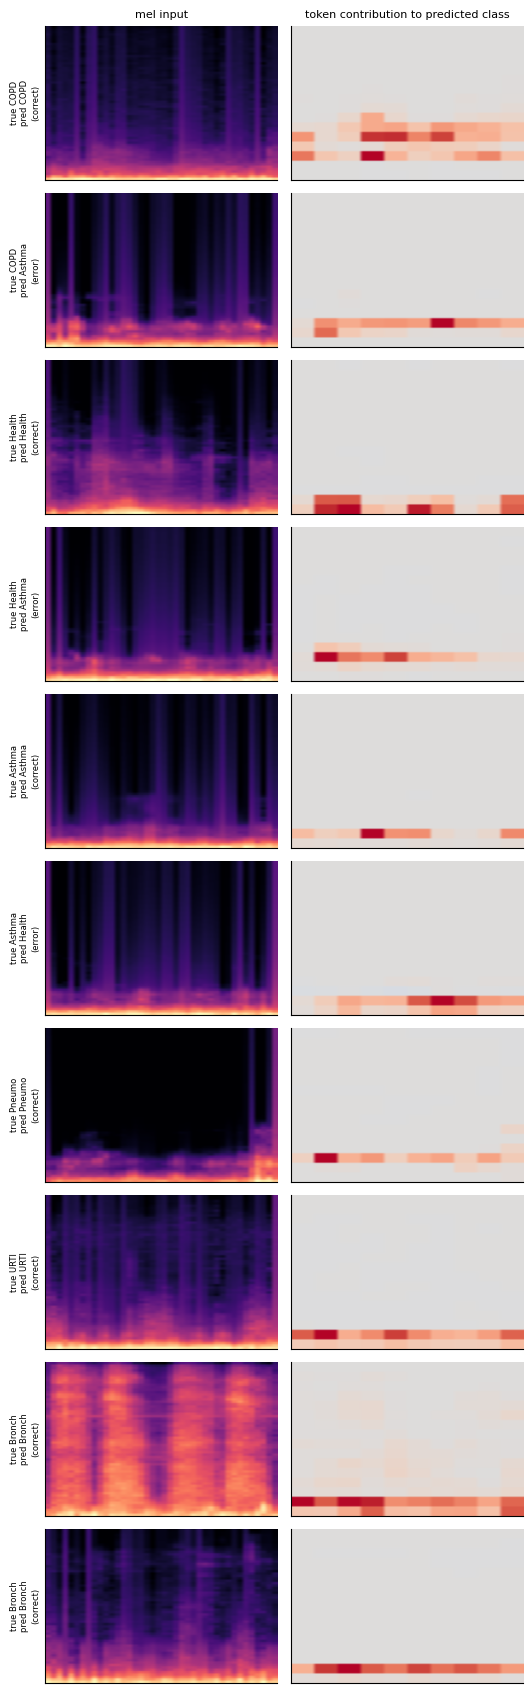


[table21_view_gate_weights_by_class]  saved: tables/table21_view_gate_weights_by_class.csv


,class,mel,CQT,MFCC
0,Asthma,0.989,0.443,0.253
1,Bronchiectasis,0.986,0.468,0.296
2,Bronchiolitis,0.988,0.456,0.275
3,COPD,0.987,0.456,0.278
4,Healthy,0.988,0.448,0.261
5,Pneumonia,0.988,0.449,0.266
6,URTI,0.988,0.455,0.276


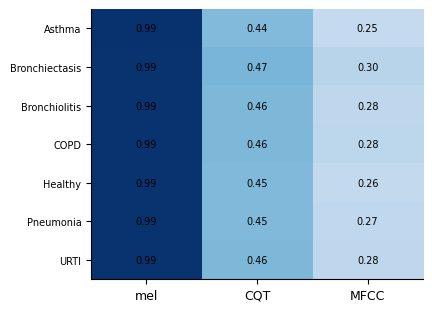

In [23]:
# CELL 16a | Explainability for the headline model, after test evaluation: where it looked when it was right and when it was wrong, and which view it trusted.
# Token contribution = exact additive share of each final token to the predicted-class logit (no gradient, no approximation). Fold 0 test frames only.
import torch, matplotlib.pyplot as plt
hm_ = bspc.load_model(HEAD_CORE, trial_dir(f"M_{HEAD_KEY}_paper_f0_s0"), device)
te0 = SP["paper"][0][2]; xt = Xg[torch.as_tensor(te0, device=device)]
with torch.no_grad():
    Pt = torch.cat([torch.softmax(hm_(xt[i:i + 1024].float()), 1).cpu() for i in range(0, len(xt), 1024)]).numpy()
pred, conf, yt = Pt.argmax(1), Pt.max(1), y[te0]
picks = []
for c in range(7):
    if not (yt == c).any(): continue
    ok = np.where((yt == c) & (pred == c))[0]; bad = np.where((yt == c) & (pred != c))[0]
    picks += [(int(i), "correct") for i in ok[np.argsort(-conf[ok])][:1]] + [(int(i), "error") for i in bad[np.argsort(-conf[bad])][:1]]
fig, axs = plt.subplots(len(picks), 2, figsize=(5.4, 1.7 * len(picks)), squeeze=False)
for r_, (i, kind) in enumerate(picks):
    x1 = xt[i:i + 1].float(); tgt = torch.tensor([int(pred[i])], device=device)
    try: cmap_ = hm_.contributions(x1, tgt)[0].cpu().numpy()
    except Exception: cmap_ = np.zeros((hm_.nf, hm_.nt))
    axs[r_, 0].imshow(x1[0, 0].cpu(), aspect="auto", origin="lower", cmap="magma")
    axs[r_, 1].imshow(np.repeat(np.repeat(cmap_, 4, 0), 4, 1), aspect="auto", origin="lower", cmap="coolwarm", vmin=-np.abs(cmap_).max() - 1e-9, vmax=np.abs(cmap_).max() + 1e-9)
    axs[r_, 0].set_ylabel(f"true {CLASSES[yt[i]][:6]}\npred {CLASSES[pred[i]][:6]}\n({kind})", fontsize=6)
    for a in axs[r_]: a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_title("mel input", fontsize=8); axs[0, 1].set_title("token contribution to predicted class", fontsize=8)
fig.tight_layout(); save_fig(fig, "figX2_correct_and_error_examples")
if getattr(hm_, "fuse", None) is not None and hm_.fuse.mode == "se":                 # which view does the gate favour, per true class
    with torch.no_grad():
        G = torch.cat([hm_.fuse.gate(xt[i:i + 1024].float()).cpu() for i in range(0, len(xt), 1024)]).numpy()
    names = ["mel", "CQT", "MFCC"]; tg = pd.DataFrame({**{names[k]: G[:, k] for k in range(3)}, "class": [CLASSES[c] for c in yt]}).groupby("class").mean().round(3)
    save_table(tg.reset_index(), "table21_view_gate_weights_by_class")
    fig, a = plt.subplots(figsize=(4.4, 3.2)); a.imshow(tg.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    a.set_xticks(range(3)); a.set_xticklabels(names); a.set_yticks(range(len(tg))); a.set_yticklabels(tg.index, fontsize=7)
    for i in range(tg.shape[0]):
        for j in range(3): a.text(j, i, f"{tg.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.tight_layout(); save_fig(fig, "figX3_view_gate_by_class")


## 17. Paper figures

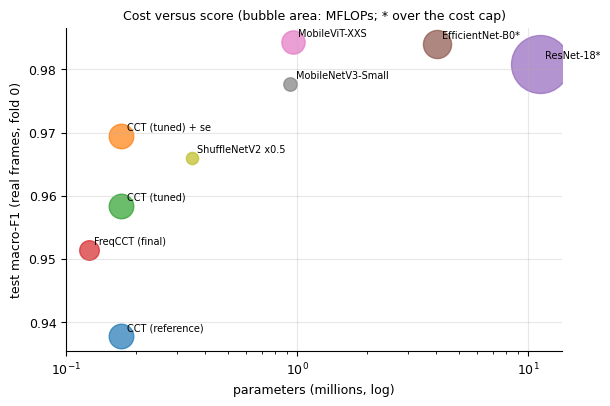

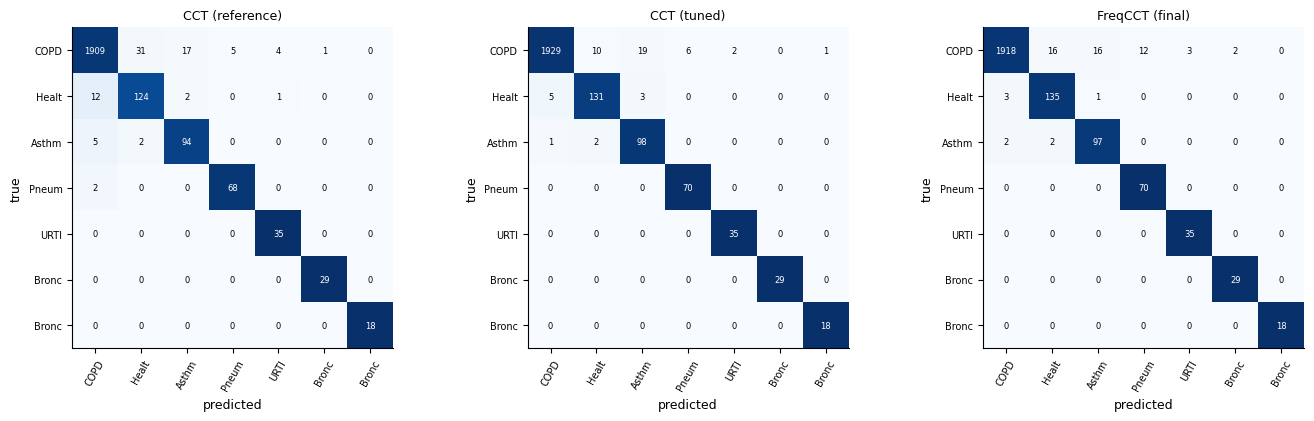

In [24]:
# CELL 17 | Paper figures: cost versus score, confusion matrices of the two final models.
import matplotlib.pyplot as plt
R = collect(); d = R[(R.protocol == "paper") & (R.fold == 0) & (R.seed == 0) & (R.phase.isin(["main", "E"]))].copy()
d = pd.concat([d[d.phase == "main"], d[d.phase == "E"].sort_values("val_macro_f1", ascending=False).groupby("arch").head(1)])
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for r in d.itertuples():
    ax.scatter(r.params / 1e6, r.test_macro_f1, s=40 + r.mflops * 2.2, alpha=.7); ax.annotate(r.label.replace(" (matched)", "").replace(" (over cap, reference)", "*"), (r.params / 1e6, r.test_macro_f1), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("parameters (millions, log)"); ax.set_ylabel("test macro-F1 (real frames, fold 0)"); ax.grid(alpha=.3)
ax.set_title("Cost versus score (bubble area: MFLOPs; * over the cost cap)", fontsize=9); save_fig(fig, "figP1_cost_vs_score")
keys = [k for k in ("cct_ref", "cct_tuned", "freqcct_final") if k in MAIN_CORE]
fig, axs = plt.subplots(1, len(keys), figsize=(4.6 * len(keys), 4.2), squeeze=False)
for a, k in zip(axs[0], keys):
    cm = np.array(json.load(open(os.path.join(trial_dir(f"M_{k}_paper_f0_s0"), "metrics.json")))["confusion"], float); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1); a.set_xticks(range(7)); a.set_yticks(range(7)); a.set_xticklabels([c[:5] for c in CLASSES], rotation=60, fontsize=7); a.set_yticklabels([c[:5] for c in CLASSES], fontsize=7)
    for i in range(7):
        for j in range(7): a.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > .5 else "black")
    a.set_title(LABELS[k], fontsize=9); a.set_xlabel("predicted"); a.set_ylabel("true")
fig.tight_layout(); save_fig(fig, "figP2_confusion_matrices")


## 18. Manifest and freshness check

In [25]:
# CELL 18 | Manifest and freshness check. Fails loudly if anything in this run folder is stale, missing or from other code.
need_tables = ["table01a_dataset", "table01b_splits", "table02_configs_and_cost", "table03_main_results_reference_protocol", "table04_per_class_fold0",
               "table05_paired_comparisons_fold0", "table06_baselines_vs_ours_fold0", "table07_ablations_fold0", "table08_efficiency", "table09_epochs_run",
               "table11_posthoc_prior_correction_and_recording_vote", "table12_xai_summary", "table13_tuning_trials", "table14_locked_configs",
               "table16_headline_selection_validation", "table17_headline_3seeds_x_5folds", "table18_must_ablations_headline_fold0", "table19_paired_macroF1_vs_headline_fold0",
               "table20_model_metrics_auc_ap_ece_fold0"]
if FUSION_MODELS: need_tables.append("table15_view_fusion_fold0_validation")
need_figs = ["figC1_learning_curves_individual", "figC2_learning_curves_together", "figX1_explanation_examples", "figP1_cost_vs_score", "figP2_confusion_matrices", "figT1_tuning_history", "figP3_forest_vs_headline", "figP4_seed_fold_spread", "figX2_correct_and_error_examples"]
problems = []
for t in need_tables:
    p = os.path.join(RUN_DIR, "tables", t + ".csv")
    if not os.path.exists(p): problems.append(f"missing table {t}")
    elif os.path.getmtime(p) < RUN_START: problems.append(f"stale table {t} (older than this run)")
for f in need_figs:
    for ext in ("png", "pdf", "svg"):
        p = os.path.join(RUN_DIR, "figures", f"{f}.{ext}")
        if not os.path.exists(p): problems.append(f"missing figure {f}.{ext}")
        elif os.path.getmtime(p) < RUN_START: problems.append(f"stale figure {f}.{ext}")
unfinished, wrong = [], []
for tid in os.listdir(os.path.join(RUN_DIR, "trials")):
    d = trial_dir(tid); st = json.load(open(os.path.join(d, "status.json"))) if os.path.exists(os.path.join(d, "status.json")) else {}
    if st.get("state") == "pruned": continue
    if st.get("state") != "done": unfinished.append(tid); continue
    c = json.load(open(os.path.join(d, "config.json")))
    if c["data"] != bspc.DATA_FP: wrong.append(f"{tid}: data fingerprint differs")
    if c["lib"] != bspc.LIB_HASH: wrong.append(f"{tid}: trained with other code ({c['lib']})")
problems += [f"unfinished run {t}" for t in unfinished] + wrong
files = {}
for sub in ("tables", "figures", "configs"):
    for f in sorted(os.listdir(os.path.join(RUN_DIR, sub))):
        p = os.path.join(RUN_DIR, sub, f); files[f"{sub}/{f}"] = dict(bytes=os.path.getsize(p), sha1=hashlib.sha1(open(p, "rb").read()).hexdigest()[:12])
json.dump(dict(run_id=RUN_ID, checked=datetime.datetime.now().isoformat(timespec="seconds"), library=bspc.LIB_HASH, data=bspc.DATA_FP,
               n_trials_done=len([t for t in os.listdir(os.path.join(RUN_DIR, 'trials'))]), problems=problems, files=files),
          open(os.path.join(RUN_DIR, "manifest.json"), "w"), indent=2)
print(f"manifest written: {len(files)} files | trials: {len(os.listdir(os.path.join(RUN_DIR, 'trials')))}")
print("OK: every output belongs to this run, this data and this code" if not problems else "Warning: problems:\n  " + "\n  ".join(problems))


manifest written: 246 files | trials: 150
⚠️ problems:
  unfinished run V3_cct_l_plain_paper_f0_s0


In [26]:
import json, numpy as np
def load(tid):
    d = trial_dir(tid); spec = json.load(open(f"{d}/config.json"))["spec"]
    return spec, bspc.load_model(spec, d, device), np.load(f"{d}/preds.npz")

sa, ma, pa = load("M_cct_tuned_fused_paper_f0_s0")        # CCT tuned + SE
sb, mb, pb = load("E_mobilevitxxs_lr0.001_paper_f0_s0")   # MobileViT-XXS
te = pa["test_idx"]; assert (te == pb["test_idx"]).all()
yte, rec = y[te], M["rec_idx"].values[te]

va = SP["paper"][0][1]; yva = y[va]
Pva = [bspc.predict_probs(m, Xg, va, s, device, use_amp=True) for m, s in ((ma, sa), (mb, sb))]
Pte = [pa["test_probs"], pb["test_probs"]]

def fuse(P, w):                                            # weighted log-probability average
    z = w*np.log(P[0]+1e-9) + (1-w)*np.log(P[1]+1e-9); z = np.exp(z - z.max(1, keepdims=True))
    return z / z.sum(1, keepdims=True)

ws = np.linspace(0, 1, 11)
w_val = ws[int(np.argmax([bspc.scores(yva, fuse(Pva, w).argmax(1))["macro_f1"] for w in ws]))]
for name, w in (("CCT alone", 1.0), ("MobileViT alone", 0.0), ("fused 50/50", 0.5), (f"fused w={w_val:.1f} (val-chosen)", w_val)):
    s = bspc.scores(yte, fuse(Pte, w).argmax(1)); print(f"{name:32s} acc {s['accuracy']:.4f}  macro-F1 {s['macro_f1']:.4f}  MCC {s['mcc']:.4f}")

# oracle ceiling and significance
ca, cb = Pte[0].argmax(1) == yte, Pte[1].argmax(1) == yte
print("frames only CCT right:", int((ca & ~cb).sum()), "| only MobileViT right:", int((~ca & cb).sum()))
print(bspc.bootstrap_diff(yte, fuse(Pte, w_val).argmax(1), Pte[1].argmax(1), rec))   # fused minus MobileViT

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.14MB            

model.safetensors: downloading bytes:           |  0.00B            

CCT alone                        acc 0.9813  macro-F1 0.9695  MCC 0.9410
MobileViT alone                  acc 0.9911  macro-F1 0.9843  MCC 0.9707
fused 50/50                      acc 0.9932  macro-F1 0.9879  MCC 0.9776
fused w=0.4 (val-chosen)         acc 0.9919  macro-F1 0.9848  MCC 0.9735
frames only CCT right: 9 | only MobileViT right: 32
(0.000542257592174078, -0.0029782458100159363, 0.0036073251446474787)


In [28]:
import json, itertools, numpy as np, pandas as pd
def load(tid):
    d = trial_dir(tid); spec = json.load(open(f"{d}/config.json"))["spec"]
    return spec, bspc.load_model(spec, d, device), np.load(f"{d}/preds.npz")

TR = {"CCT+SE": "M_cct_tuned_fused_paper_f0_s0", "FreqCCT": "M_freqcct_final_paper_f0_s0",
      "MobileViT": "E_mobilevitxxs_lr0.001_paper_f0_s0", "MobileNetV3-S": "E_mobilenetv3s_lr0.001_paper_f0_s0",
      "ShuffleNetV2": "E_shufflenet05_lr0.001_paper_f0_s0"}
COST = {"CCT+SE": (173187, 124.2, 692.5, 5.94), "FreqCCT": (124999, 72.5, 500.0, 5.53), "MobileViT": (953271, 109.6, 3813.1, 12.51),
        "MobileNetV3-S": (931047, 24.5, 3724.2, 6.58), "ShuffleNetV2": (348967, 17.2, 1395.9, 8.45)}
va = SP["paper"][0][1]; yva = y[va]; EXTRACT_MS = 27.5
L = {k: load(t) for k, t in TR.items()}
te = L["CCT+SE"][2]["test_idx"]; yte, rec = y[te], M["rec_idx"].values[te]
Pva = {k: bspc.predict_probs(m, Xg, va, s, device, use_amp=True) for k, (s, m, p) in L.items()}
Pte = {k: p["test_probs"] for k, (s, m, p) in L.items()}

def fuse(Pa, Pb, w):
    z = w*np.log(Pa+1e-9) + (1-w)*np.log(Pb+1e-9); z = np.exp(z - z.max(1, keepdims=True)); return z / z.sum(1, keepdims=True)

rows = []
for a, b in [("CCT+SE","MobileViT"), ("CCT+SE","MobileNetV3-S"), ("CCT+SE","ShuffleNetV2"), ("FreqCCT","MobileNetV3-S"), ("FreqCCT","MobileViT")]:
    ws = np.linspace(0, 1, 11)
    w = ws[int(np.argmax([bspc.scores(yva, fuse(Pva[a], Pva[b], x).argmax(1))["macro_f1"] for x in ws]))]
    pf = fuse(Pte[a], Pte[b], w).argmax(1); s = bspc.scores(yte, pf)
    best = max((a, b), key=lambda k: bspc.scores(yte, Pte[k].argmax(1))["macro_f1"])      # stronger single model
    d0, lo, hi = bspc.bootstrap_diff(yte, pf, Pte[best].argmax(1), rec)
    _, p_mc, n_f, n_b = bspc.mcnemar(pf == yte, Pte[best].argmax(1) == yte)
    both_wrong = int(((Pte[a].argmax(1) != yte) & (Pte[b].argmax(1) != yte)).sum())
    ca, cb = COST[a], COST[b]
    rows.append(dict(pair=f"{a} + {b}", w_val=round(w, 1), acc=round(s["accuracy"], 4), macro_F1=round(s["macro_f1"], 4), MCC=round(s["mcc"], 4),
                     ceiling_acc=round(1 - both_wrong/len(yte), 4), best_single=best, d_macroF1=round(d0, 4), CI=f"[{lo:.4f}, {hi:.4f}]", mcnemar_p=round(p_mc, 3),
                     params=ca[0]+cb[0], MFLOPs=round(ca[1]+cb[1], 1), weights_MB=round((ca[2]+cb[2])/1e3, 2),
                     model_ms=round(ca[3]+cb[3], 1), pipeline_ms=round(EXTRACT_MS+ca[3]+cb[3], 1)))
display(pd.DataFrame(rows))

,pair,w_val,acc,macro_F1,MCC,ceiling_acc,best_single,d_macroF1,CI,mcnemar_p,params,MFLOPs,weights_MB,model_ms,pipeline_ms
0,CCT+SE + MobileViT,0.4,0.9919,0.9848,0.9735,0.9949,MobileViT,0.0005,"[-0.0030, 0.0036]",0.683,1126458,233.8,4.51,18.4,45.9
1,CCT+SE + MobileNetV3-S,0.5,0.9894,0.9818,0.9653,0.9941,MobileNetV3-S,0.0041,"[-0.0018, 0.0116]",0.579,1104234,148.7,4.42,12.5,40.0
2,CCT+SE + ShuffleNetV2,0.5,0.9881,0.9794,0.9614,0.9915,CCT+SE,0.0099,"[0.0027, 0.0184]",0.003,522154,141.4,2.09,14.4,41.9
3,FreqCCT + MobileNetV3-S,0.2,0.9881,0.9777,0.9611,0.9928,MobileNetV3-S,0.0000,"[-0.0021, 0.0020]",0.480,1056046,97.0,4.22,12.1,39.6
4,FreqCCT + MobileViT,0.0,0.9911,0.9843,0.9707,0.9945,MobileViT,0.0000,"[0.0000, 0.0000]",1.000,1078270,182.1,4.31,18.0,45.5


---
# Part 2. Larger CCT variants, distillation and ensemble

The cells below continue from the run folder of Part 1. They train CCT-M and CCT-L (plain and distilled from MobileViT XXS and MobileNetV3 Small) on fold 0 and evaluate single models and the ensemble.


### V3-0. Setup: Drive mount, input folders, data

In [1]:
# V3-0 | Setup: Drive mount, input folders, library and data. Skipped automatically if the original notebook is already loaded in this session.
# Edit only these three lines if your folders differ (leave None to use the defaults below).
V3_RUN_DIR  = None    # default: <DRIVE>/Data/RespCCT_BSPC/runs/<run named in LATEST.txt>, e.g. .../runs/run_20261022_070616
V3_FEAT_SRC = None    # default: <DRIVE>/Data/SeedPaper_CCT/features   (feat_orig.npy, meta_orig.csv, feat_aug_<class>.npy, meta_aug_<class>.csv)
V3_RUN_ID   = "run_20261022_070616"   # the finished run to read from; set to None to follow LATEST.txt
import os, sys, hashlib, numpy as np, pandas as pd, torch
if all(n in globals() for n in ("bspc", "Xg", "y", "M", "SP", "aug_v", "device", "RUN_DIR", "CLASSES")):
    print("original notebook already loaded in this session: using its variables (RUN_DIR =", RUN_DIR, ")")
else:
    if V3_RUN_DIR is None:
        if not os.path.exists("/content/drive/MyDrive"):
            from google.colab import drive; drive.mount("/content/drive")
        BASE = "/content/drive/MyDrive/Data"; ROOT = os.path.join(BASE, "RespCCT_BSPC")
        rid = V3_RUN_ID or open(os.path.join(ROOT, "LATEST.txt")).read().strip()
        RUN_DIR = os.path.join(ROOT, "runs", rid)
        if V3_FEAT_SRC is None: V3_FEAT_SRC = os.path.join(BASE, "SeedPaper_CCT", "features")
    else:
        RUN_DIR = V3_RUN_DIR
    assert os.path.isdir(os.path.join(RUN_DIR, "trials")), f"not a run folder: {RUN_DIR}"
    assert V3_FEAT_SRC and os.path.exists(os.path.join(V3_FEAT_SRC, "feat_orig.npy")), f"feature folder not found: {V3_FEAT_SRC}"
    code_dir = os.path.join(RUN_DIR, "code")                          # the exact library this run was trained with (read only, never rewritten)
    assert os.path.exists(os.path.join(code_dir, "bspc_lib.py")), "RUN_DIR/code/bspc_lib.py missing"
    if code_dir not in sys.path: sys.path.insert(0, code_dir)
    import bspc_lib as bspc
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    CLASSES = bspc.CLASSES; LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
    parts = [np.load(os.path.join(V3_FEAT_SRC, "feat_orig.npy"))]
    mo = pd.read_csv(os.path.join(V3_FEAT_SRC, "meta_orig.csv")); mo["aug"] = 0; metas = [mo]
    for c in CLASSES[1:]:
        p = os.path.join(V3_FEAT_SRC, f"feat_aug_{c}.npy")
        if os.path.exists(p):
            parts.append(np.load(p)); m_ = pd.read_csv(os.path.join(V3_FEAT_SRC, f"meta_aug_{c}.csv")); m_["aug"] = 1; metas.append(m_)
    X = np.concatenate(parts); M = pd.concat(metas, ignore_index=True); del parts
    y = M["label"].map(LABEL_MAP).values.astype(np.int64)
    assert len(X) == len(M), "features and metadata differ in length"
    bspc.DATA_FP = hashlib.md5((str(X.shape) + M.to_csv(index=False)).encode()).hexdigest()[:10]
    Xg = torch.from_numpy(X).to(device); del X
    SP = bspc.make_splits(M, y); aug_v = M["aug"].values
    print("run folder:", RUN_DIR); print("features  :", V3_FEAT_SRC)
    print(f"device {device} | frames {len(Xg)} | library hash {bspc.LIB_HASH} | data fingerprint {bspc.DATA_FP}")


Mounted at /content/drive
run folder: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616
features  : /content/drive/MyDrive/Data/SeedPaper_CCT/features
device cuda | frames 68859 | library hash 425661e596 | data fingerprint 7acb7a62b9


### V3-1. Guard and snapshot

In [2]:
# V3-1 | Guard + snapshot of every existing file (to prove at the end that nothing old was touched).
import os, sys, json, time, copy, math, hashlib, shutil, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
need = ["bspc", "Xg", "y", "M", "SP", "aug_v", "device", "RUN_DIR", "CLASSES"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run cell V3-0 first (missing: {missing})"
V3_PREFIX = "V3_"

def _snap(root):
    out = {}
    for dp, dn, fn in os.walk(root):
        for f in fn:
            p = os.path.join(dp, f); rel = os.path.relpath(p, root); parts = rel.split(os.sep)
            if any(s.startswith(("V3_", "v3_")) or s == "selftest_v3" for s in parts): continue      # our own files
            st = os.stat(p); out[rel] = (st.st_size, int(st.st_mtime))
    return out
V3_SNAP_BEFORE = _snap(RUN_DIR)
print(f"run folder: {RUN_DIR}\nsnapshot of {len(V3_SNAP_BEFORE)} existing files taken (compared again in the last cell)")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
if device.type == "cuda": torch.backends.cudnn.benchmark = True


run folder: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616
snapshot of 1237 existing files taken (compared again in the last cell)
device: cuda Tesla T4


### V3-2. Settings and output folder

In [3]:
# V3-2 | Settings. Every value is fixed here; nothing is searched.
QUICK = bool(globals().get("V3_QUICK", False))       # True only for a fast code test (tiny schedule, subsampled frames)
FOLD, SEED = 0, 0
MAX_EPOCHS, PATIENCE = 150, 12
COS_EPOCHS, WARMUP, ES_START, WATCH = 135, 10, 80, 12
if QUICK: MAX_EPOCHS, PATIENCE, COS_EPOCHS, WARMUP, ES_START, WATCH = 4, 3, 3, 1, 2, 3
VRAM_TARGET, MAX_BATCH, REF_BATCH = 0.80, 512, 512     # probe keeps VRAM <= 80 %; batch is capped at 512 (raise MAX_BATCH to trade accuracy risk for speed)
TEACHER_TIDS = ["E_mobilevitxxs_lr0.001_paper_f0_s0", "E_mobilenetv3s_lr0.001_paper_f0_s0"]   # already trained on fold 0 in the original run

# learning rates are for batch 512 and are scaled by sqrt(batch / 512) if the probe picks another batch
MODELS = {
 "cct_m":     dict(arch="cct", e=128, layers=6, heads=4, ratio=2, pe=True, fusion="se", lr=2.0e-3, wd=0.03, sd=0.10, mlp_drop=0.09, attn_drop=0.08),
 "cct_l":     dict(arch="cct", e=192, layers=6, heads=6, ratio=2, pe=True, fusion="se", lr=1.5e-3, wd=0.05, sd=0.15, mlp_drop=0.10, attn_drop=0.10),
}
NAMES = {"cct_m": "CCT-M", "cct_l": "CCT-L"}
RUNS = [("cct_m", "plain"), ("cct_m", "kd"), ("cct_l", "plain"), ("cct_l", "kd")]   # edit to run a subset

# every table, figure and summary of this notebook goes into ONE new folder (set V3_OUT_DIR before this cell to put it elsewhere)
OUT_DIR = globals().get("V3_OUT_DIR") or os.path.join(RUN_DIR, "v3_outputs")
for _s in ("tables", "figures"): os.makedirs(os.path.join(OUT_DIR, _s), exist_ok=True)
def v3_table(df, name):
    p = os.path.join(OUT_DIR, "tables", name + ".csv"); df.to_csv(p, index=False); print(f"  saved table: {p}")
def v3_fig(fig, name):
    for ext in ("png", "pdf"): fig.savefig(os.path.join(OUT_DIR, "figures", f"{name}.{ext}"), dpi=200 if ext == "png" else None, bbox_inches="tight")
    import matplotlib.pyplot as plt; plt.close(fig); print(f"  saved figure: {os.path.join(OUT_DIR, 'figures', name)}.png / .pdf")
print("outputs go to:", OUT_DIR)
SETTINGS_PATH = os.path.join(RUN_DIR, "v3_settings.json")
BATCH = {k: (64 if QUICK else REF_BATCH) for k in MODELS}      # QUICK uses a small batch so a CPU test does not run out of RAM
if os.path.exists(SETTINGS_PATH) and not QUICK:                       # a restart must reuse the batch sizes of the runs already started
    BATCH.update(json.load(open(SETTINGS_PATH))["batch"]); print("batch sizes loaded from v3_settings.json:", BATCH)

def lr_factor(ep, warmup, cosT, floor):
    """Learning-rate multiplier at epoch ep (0-based): linear warm-up, then cosine to `floor` at epoch cosT, flat afterwards."""
    if ep < warmup: return (ep + 1) / warmup
    return max(floor, 0.5 * (1 + math.cos(math.pi * min(1.0, (ep - warmup) / max(1, cosT - warmup)))))

def model_spec(key, variant, lr_mult=1.0):
    m = dict(MODELS[key]); bs = BATCH[key]
    s = {**m, "lr": m["lr"] * math.sqrt(bs / REF_BATCH) * lr_mult, "batch_size": bs, "sched": "cosine", "warmup": WARMUP, "cos_epochs": COS_EPOCHS, "lr_floor": 0.01,
         "es_start": ES_START, "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "tmask": 8, "fmask": 0, "ema": 0.99, "clip": 1.0, "seed": SEED, "watch_epoch": WATCH}
    if variant == "plain": s.update(smooth=0.15, mixup=0.0)
    else: s.update(smooth=0.0, mixup=0.3, kd_alpha=0.8, kd_T=1.0, teachers=list(TEACHER_TIDS))
    s.update(model=f"{key}_{variant}", label=f"{NAMES[key]} ({'distilled' if variant == 'kd' else 'plain'})", phase="V3", protocol="paper", split="paper", fold=FOLD)
    return s

tr0, va0, te0 = SP["paper"][FOLD]
print(f"fold {FOLD}: train {len(tr0)} | val {len(va0)} (real {int((aug_v[va0]==0).sum())}) | test {len(te0)}")
print(f"schedule: max {MAX_EPOCHS} epochs, patience {PATIENCE}, warm-up {WARMUP}, cosine to epoch {COS_EPOCHS}, early stop allowed from epoch {ES_START}" + ("   [QUICK TEST MODE]" if QUICK else ""))


outputs go to: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs
batch sizes loaded from v3_settings.json: {'cct_m': 256, 'cct_l': 256}
fold 0: train 49578 | val 5509 (real 973) | test 2359
schedule: max 150 epochs, patience 12, warm-up 10, cosine to epoch 135, early stop allowed from epoch 80


### V3-3. Training engine

In [4]:
# V3-3 | Training engine. A copy of bspc.train_run with: settable schedule, early-stop start epoch, distillation, fast EMA, no per-step GPU sync,
# no weight decay on norms / biases / positions, and a divergence watchdog. The library file is not touched, so LIB_HASH and all old trials stay valid.
ENGINE_V3 = "v3.1"
class Diverged(Exception): pass
V3_DEFAULTS = dict(bspc.DEFAULT_TRAIN, cos_epochs=60, warmup=3, lr_floor=0.01, es_start=0, kd_alpha=0.0, kd_T=1.0, teachers=None, watch_epoch=12)

def _eval_v3(model, X, y, idx, S, device, use_amp):
    P = bspc.predict_probs(model, X, idx, S, device, bs=1024, use_amp=use_amp); yt = y[idx]
    return P, float(-np.log(P[np.arange(len(yt)), yt] + 1e-9).mean()), float((P.argmax(1) == yt).mean()), bspc.macro_f1_present(yt, P.argmax(1))

def _load_teachers(tids, ref, device):
    try: import timm
    except ImportError:
        import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True); import timm
    out = []
    for tid in tids:
        d = os.path.join(RUN_DIR, "trials", tid); c = json.load(open(os.path.join(d, "config.json")))
        ok = c["train"] == bspc.idx_hash(ref["train"]) and c["val"] == bspc.idx_hash(ref["val"]) and c["test"] == bspc.idx_hash(ref.get("test"))
        assert ok, f"teacher {tid} was trained on other frames than this fold: refused (it could have seen test frames)"
        sp = dict(c["spec"]); sp["pretrained"] = False                         # weights come from best.pt, no download
        m = bspc.load_model(sp, d, device).eval()
        for p in m.parameters(): p.requires_grad_(False)
        out.append(m)
    return out

def train_run_v3(spec, X, y, idx, out_dir, device, evaluate_test=False, meta=None, report=None, log=print, hist_every=5):
    assert os.path.basename(os.path.normpath(out_dir)).startswith(V3_PREFIX), "V3 runs write only into folders named V3_*: refusing to touch other results"
    S = {**V3_DEFAULTS, **spec}; assert S["sched"] == "cosine" and not S["balance"], "V3 supports the cosine schedule without class re-balancing only"
    os.makedirs(out_dir, exist_ok=True)
    cfg = dict(spec=S, train=bspc.idx_hash(idx["train"]), val=bspc.idx_hash(idx["val"]), test=bspc.idx_hash(idx.get("test")), lib=bspc.LIB_HASH, data=bspc.DATA_FP, engine=ENGINE_V3)
    cfg["hash"] = bspc.stable_hash(cfg)
    cpath, spath = os.path.join(out_dir, "config.json"), os.path.join(out_dir, "status.json")
    if os.path.exists(cpath):
        old = json.load(open(cpath))
        if old.get("hash") != cfg["hash"]: raise RuntimeError(f"{out_dir} holds a run with different settings/data/code ({old.get('hash')} vs {cfg['hash']}); nothing is overwritten.")
    else: bspc._json(cfg, cpath)
    st = json.load(open(spath)) if os.path.exists(spath) else {}
    if st.get("state") == "done" and os.path.exists(os.path.join(out_dir, "metrics.json")): return json.load(open(os.path.join(out_dir, "metrics.json")))
    if st.get("state") == "diverged": raise Diverged(f"{os.path.basename(out_dir)} diverged in an earlier attempt and is not resumed; the retry folder (_r1) is used instead")
    use_amp = device.type == "cuda"
    torch.manual_seed(42 + S["seed"]); np.random.seed(42 + S["seed"])
    model = bspc.build_model(S).to(device)
    dec = [p for n, p in model.named_parameters() if p.ndim >= 2 and not n.endswith("pos")]; nodec = [p for n, p in model.named_parameters() if not (p.ndim >= 2 and not n.endswith("pos"))]
    opt = torch.optim.AdamW([{"params": dec, "weight_decay": S["wd"]}, {"params": nodec, "weight_decay": 0.0}], lr=S["lr"])
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda ep: lr_factor(ep, S["warmup"], S["cos_epochs"], S["lr_floor"]))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ema = None
    if S["ema"] > 0: ema = copy.deepcopy(model).eval(); [p.requires_grad_(False) for p in ema.parameters()]
    teachers = _load_teachers(S["teachers"], idx.get("teacher_ref", idx), device) if (S["kd_alpha"] > 0 and S["teachers"]) else []
    hist, best, best_ep, bad, ep0, elapsed, steps = [], float("inf"), 0, 0, 0, 0.0, 0
    lp = os.path.join(out_dir, "last.pt")
    if os.path.exists(lp):
        ck = torch.load(lp, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sch.load_state_dict(ck["sch"]); scaler.load_state_dict(ck["scaler"])
        if ema is not None and ck.get("ema") is not None: ema.load_state_dict(ck["ema"])
        hist, best, best_ep, bad, ep0, elapsed, steps = ck["hist"], ck["best"], ck["best_ep"], ck["bad"], ck["epoch"], ck["elapsed"], ck["steps"]
        torch.set_rng_state(ck["rng"].cpu()); log(f"    resumed from epoch {ep0}")
    tr = torch.as_tensor(idx["train"], device=device); va = idx["val"]; yg = torch.as_tensor(y, device=device).long()
    gpu = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"
    bspc._json({**st, "state": "running", "epoch": ep0}, spath)
    stopped = False
    if (bad >= S["patience"] and ep0 >= S["es_start"]) or ep0 >= S["max_epochs"]: ep0 = S["max_epochs"]
    bs, T, a = S["batch_size"], S["kd_T"], S["kd_alpha"]
    for ep in range(ep0, S["max_epochs"]):
        t0 = time.time(); model.train(); perm = tr[torch.randperm(len(tr), device=device)]
        tot = torch.zeros((), device=device); corr = torch.zeros((), device=device); n_seen = 0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            if len(b) < 8: continue
            xb = bspc.prep(X[b].float(), S); yb = yg[b]
            if S["fmask"] or S["tmask"]: xb = bspc.spec_augment(xb, S["fmask"], S["tmask"])
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                if S["mixup"] > 0:
                    lam = float(np.random.beta(S["mixup"], S["mixup"])); pi = torch.randperm(len(b), device=device); xin = lam * xb + (1 - lam) * xb[pi]
                else: xin = xb
                outf = model(xin).float()
                if S["mixup"] > 0: ce = lam * F.cross_entropy(outf, yb, label_smoothing=S["smooth"]) + (1 - lam) * F.cross_entropy(outf, yb[pi], label_smoothing=S["smooth"])
                else: ce = F.cross_entropy(outf, yb, label_smoothing=S["smooth"])
                if teachers:
                    with torch.no_grad(): tp = torch.stack([F.softmax(t(xin).float() / T, 1) for t in teachers]).mean(0)
                    kd = F.kl_div(F.log_softmax(outf / T, 1), tp, reduction="batchmean") * (T * T)
                    loss = (1 - a) * ce + a * kd
                else: loss = ce
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            if S["clip"]: nn.utils.clip_grad_norm_(model.parameters(), S["clip"])
            scaler.step(opt); scaler.update(); steps += 1
            if ema is not None:
                d = min(S["ema"], (1 + steps) / (10 + steps))
                with torch.no_grad():
                    ep_, mp_ = list(ema.parameters()), [p.detach() for p in model.parameters()]
                    torch._foreach_mul_(ep_, d); torch._foreach_add_(ep_, mp_, alpha=1 - d)
                    for be, bm in zip(ema.buffers(), model.buffers()): be.copy_(bm)
            tot += loss.detach() * len(b); corr += (outf.argmax(1) == yb).sum(); n_seen += len(b)
        trl, tra = float(tot) / max(n_seen, 1), float(corr) / max(n_seen, 1)
        em = ema if ema is not None else model
        _, vl, vacc, vf1 = _eval_v3(em, X, y, va, S, device, use_amp)
        lr_now = opt.param_groups[0]["lr"]; sch.step()
        dt = time.time() - t0; elapsed += dt
        hist.append(dict(epoch=ep + 1, train_loss=trl, train_acc=tra, val_loss=vl, val_acc=vacc, val_macro_f1=vf1, lr=lr_now, seconds=dt))
        bad_now = not (math.isfinite(trl) and math.isfinite(vl))
        if not bad_now and vl < best - 1e-4:
            best, best_ep, bad = vl, ep + 1, 0; bspc._save(copy.deepcopy(em.state_dict()), os.path.join(out_dir, "best.pt"))
        else: bad += 1
        bspc._save(dict(model=model.state_dict(), opt=opt.state_dict(), sch=sch.state_dict(), scaler=scaler.state_dict(), ema=None if ema is None else ema.state_dict(),
                        hist=hist, best=best, best_ep=best_ep, bad=bad, epoch=ep + 1, elapsed=elapsed, steps=steps, rng=torch.get_rng_state()), lp)
        pd.DataFrame(hist).to_csv(os.path.join(out_dir, "history.csv"), index=False); bspc._json({"state": "running", "epoch": ep + 1}, spath)
        if ep == 0 or (ep + 1) % hist_every == 0:
            left = (S["cos_epochs"] - ep - 1) * dt / 60
            log(f"    epoch {ep+1:3d} ({dt:.0f}s) lr {lr_now:.5f} | train loss {trl:.3f} acc {tra:.3f} | val loss {vl:.3f} acc {vacc:.3f} F1 {vf1:.3f} | ~{max(left,0):.0f} min to end of cosine")
        if report is not None: report(ep + 1, vf1, vl)
        if bad_now or (ep + 1 == S["watch_epoch"] and not (min(h["val_loss"] for h in hist[max(0, ep - 4):]) < hist[0]["val_loss"] - 1e-4)):
            bspc._json({"state": "diverged", "epoch": ep + 1}, spath)
            raise Diverged(f"{os.path.basename(out_dir)}: loss not finite or not below its epoch-1 value by epoch {ep+1}")
        if bad >= S["patience"] and ep + 1 >= S["es_start"]: stopped = True; log(f"    early stopping at epoch {ep+1} (best epoch {best_ep})"); break
    em = ema if ema is not None else model
    em.load_state_dict(torch.load(os.path.join(out_dir, "best.pt"), map_location=device))
    Pv, vl, vacc, vf1 = _eval_v3(em, X, y, va, S, device, use_amp)
    shape = (bspc.n_channels_of(S), 4 * bspc.n_rows_of(S), 40); h = hist[best_ep - 1]
    m = dict(trial=os.path.basename(out_dir), epochs_run=len(hist), best_epoch=best_ep, early_stopped=bool(stopped), val_loss=vl, val_acc=vacc, val_macro_f1=vf1,
             train_acc_at_best=h["train_acc"], params=bspc.n_params(em), mflops=bspc.counted_mflops(em, shape), mflops_analytic=bspc.spec_mflops(S), batch_size=bs,
             kd=bool(teachers), seconds_total=elapsed, seconds_per_epoch=float(np.mean([r["seconds"] for r in hist])),
             seconds_to_best=float(sum(r["seconds"] for r in hist[:best_ep])), minutes=elapsed / 60.0, gpu=gpu, hash=cfg["hash"])
    arrays = dict(val_idx=np.asarray(va), val_probs=Pv.astype(np.float32))
    if evaluate_test and idx.get("test") is not None:
        te = np.asarray(idx["test"]); Pt = bspc.predict_probs(em, X, te, S, device, bs=1024, use_amp=use_amp); yt = y[te]; pr = Pt.argmax(1)
        sc = bspc.scores(yt, pr); cm, pcr = bspc.per_class(yt, pr)
        m.update({f"test_{k}": v for k, v in sc.items()}); m["per_class"] = pcr; m["confusion"] = cm.tolist()
        if meta is not None:
            Pr, yr, _ = bspc.rec_vote(Pt, yt, meta["rec_idx"].values[te]); sr = bspc.scores(yr, Pr.argmax(1)); m.update({f"rec_{k}": v for k, v in sr.items()})
        arrays.update(test_idx=te, test_probs=Pt.astype(np.float32))
    np.savez_compressed(os.path.join(out_dir, "preds.npz"), **arrays)
    bspc._json(m, os.path.join(out_dir, "metrics.json"))
    bspc._json(dict(seconds_total=elapsed, minutes=elapsed / 60, seconds_per_epoch=m["seconds_per_epoch"], epochs=len(hist), best_epoch=best_ep, seconds_to_best=m["seconds_to_best"], gpu=gpu),
               os.path.join(out_dir, "time.json"))
    bspc._json({"state": "done", "epoch": len(hist)}, spath)
    try: os.remove(lp)
    except OSError: pass
    return m
print("train_run_v3 defined (engine", ENGINE_V3, ")")


train_run_v3 defined (engine v3.1 )


### V3-4. Cheap checks

In [5]:
# V3-4 | Cheap checks before any training: model sizes, the schedule, and the early-stop gate.
rows = []
for k in MODELS:
    spec = model_spec(k, "plain"); mdl = bspc.build_model(spec); shape = (bspc.n_channels_of(spec), 4 * bspc.n_rows_of(spec), 40)
    rows.append(dict(model=NAMES[k], params=bspc.n_params(mdl), mflops_formula=round(bspc.spec_mflops(spec), 1), mflops_counted=round(bspc.counted_mflops(mdl, shape), 1)))
    assert abs(rows[-1]["mflops_formula"] - rows[-1]["mflops_counted"]) < 0.5, "formula and counter disagree"
    del mdl
print(pd.DataFrame(rows).to_string(index=False))
# schedule: identical to the old one with old settings, and shaped as intended with the new ones
old = lambda ep: (ep + 1) / 3 if ep < 3 else max(0.01, 0.5 * (1 + math.cos(math.pi * min(1.0, (ep - 3) / 57))))
assert all(abs(old(e) - lr_factor(e, 3, 60, 0.01)) < 1e-12 for e in range(300)), "old schedule not reproduced"
f = [lr_factor(e, 10, 135, 0.01) for e in range(150)]
assert abs(f[9] - 1.0) < 1e-9 and f[134] == 0.01 and f[149] == 0.01 and all(f[i] >= f[i + 1] - 1e-12 for i in range(10, 149)), "schedule shape wrong"
print(f"schedule ok: peak at epoch 10, {f[67]:.2f} at epoch 68, floor 0.01 from epoch 135")
# early-stop gate (pure logic of the line used in train_run_v3)
gate = lambda bad, ep1, pat=12, es=80: bad >= pat and ep1 >= es
assert not gate(20, 79) and gate(12, 80) and not gate(11, 120) and gate(15, 100), "early-stop gate wrong"
print("early-stop gate ok: no stop before epoch 80; from epoch 80 stop after 12 epochs without a validation-loss gain")


model  params  mflops_formula  mflops_counted
CCT-M  967619           536.8           536.8
CCT-L 2151811          1135.5          1135.5
schedule ok: peak at epoch 10, 0.57 at epoch 68, floor 0.01 from epoch 135
early-stop gate ok: no stop before epoch 80; from epoch 80 stop after 12 epochs without a validation-loss gain


### V3-5. VRAM and speed probe (GPU)

In [6]:
# V3-5 | VRAM and speed probe (GPU only). Picks, per model, the batch with the best throughput that stays under 80 % of VRAM, capped at MAX_BATCH.
# It measures real training steps (forward, backward, EMA update), the teacher cost, and prints the estimated total time. It never trains a model.
def _teachers_for_probe():
    return _load_teachers(TEACHER_TIDS, dict(train=SP["paper"][FOLD][0], val=SP["paper"][FOLD][1], test=SP["paper"][FOLD][2]), device)

def _probe(key, bs, with_kd, steps=15):
    spec = {**V3_DEFAULTS, **model_spec(key, "kd" if with_kd else "plain")}; model = bspc.build_model(spec).to(device).train()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4); scaler = torch.amp.GradScaler("cuda"); ema = copy.deepcopy(model).eval()
    tr = torch.as_tensor(SP["paper"][FOLD][0], device=device); yg = torch.as_tensor(y, device=device).long()
    teachers = _teachers_for_probe() if with_kd else []
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    def step():
        b = tr[torch.randint(len(tr), (bs,), device=device)]; xb = bspc.spec_augment(bspc.prep(Xg[b].float(), spec), 0, 8); yb = yg[b]
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            out = model(xb).float(); loss = F.cross_entropy(out, yb)
            if teachers:
                with torch.no_grad(): tp = torch.stack([F.softmax(t(xb).float(), 1) for t in teachers]).mean(0)
                loss = 0.2 * loss + 0.8 * F.kl_div(F.log_softmax(out, 1), tp, reduction="batchmean")
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        with torch.no_grad():
            ep_, mp_ = list(ema.parameters()), [p.detach() for p in model.parameters()]; torch._foreach_mul_(ep_, 0.99); torch._foreach_add_(ep_, mp_, alpha=0.01)
    for _ in range(4): step()
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(steps): step()
    torch.cuda.synchronize(); dt = (time.time() - t0) / steps
    ema.eval(); bspc.predict_probs(ema, Xg, SP["paper"][FOLD][1][:1024], spec, device, bs=1024, use_amp=True); torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated() / torch.cuda.get_device_properties(0).total_memory
    del model, opt, ema, teachers; torch.cuda.empty_cache()
    return dict(model=NAMES[key], kd=with_kd, batch=bs, ms_per_step=round(dt * 1e3, 1), frames_per_s=round(bs / dt), epoch_s=round(len(tr) / (bs / dt), 1), vram_pct=round(100 * peak, 1))

if device.type != "cuda": print("no GPU: probe skipped, batch stays", BATCH)
elif QUICK: print("QUICK mode: probe skipped")
else:
    P = []
    for key in MODELS:
        for bs in (256, 512, 1024, 2048):
            try: P.append(_probe(key, bs, False))
            except torch.cuda.OutOfMemoryError: import gc; gc.collect(); torch.cuda.empty_cache(); P.append(dict(model=NAMES[key], kd=False, batch=bs, ms_per_step=np.nan, frames_per_s=0, epoch_s=np.nan, vram_pct=np.nan)); break
    PR = pd.DataFrame(P); print(PR.to_string(index=False))
    for key in MODELS:
        d = PR[(PR.model == NAMES[key]) & (PR.batch <= MAX_BATCH) & (PR.vram_pct <= 100 * VRAM_TARGET) & (PR.frames_per_s > 0)]
        if d.empty: BATCH[key] = 256; print('warning: no batch fit the VRAM target for', NAMES[key], '-> 256'); continue
        top = d.frames_per_s.max(); BATCH[key] = int(d[d.frames_per_s >= 0.95 * top].batch.min())
    json.dump(dict(batch=BATCH, saved=time.strftime("%Y-%m-%d %H:%M:%S")), open(SETTINGS_PATH, "w"), indent=2)
    print("\nchosen batch sizes:", BATCH, "(saved to v3_settings.json; a restart reuses them)")
    est = []
    for key, variant in RUNS:
        b = BATCH[key]; r = _probe(key, b, variant == "kd"); n_ep = MAX_EPOCHS if variant == "kd" else COS_EPOCHS + 5
        ev = 0.06 * r["epoch_s"]                                                      # validation pass, about 6 % of a training epoch (estimate)
        est.append(dict(run=f"{NAMES[key]} {variant}", batch=b, epoch_s=round(r["epoch_s"] + ev, 1), epochs=n_ep, minutes=round((r["epoch_s"] + ev) * n_ep / 60), vram_pct=r["vram_pct"]))
    E = pd.DataFrame(est); print(E.to_string(index=False)); print(f"\nESTIMATED TOTAL: {E.minutes.sum()/60:.1f} h  (range about {E.minutes.sum()*0.8/60:.1f} to {E.minutes.sum()*1.2/60:.1f} h; runs end early when patience triggers)")
    print(f"VRAM at the chosen batches: {E.vram_pct.min():.0f} to {E.vram_pct.max():.0f} % of {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GB (dataset included). "
          f"To use more, raise MAX_BATCH; larger batches usually cost accuracy on a dataset this size.")


model    kd  batch  ms_per_step  frames_per_s  epoch_s  vram_pct
CCT-M False    256        143.6          1783     27.8      17.2
CCT-M False    512        281.7          1817     27.3      27.5
CCT-M False   1024        562.1          1822     27.2      47.9
CCT-M False   2048       1156.4          1771     28.0      88.9
CCT-L False    256        231.2          1107     44.8      22.5
CCT-L False    512        464.2          1103     44.9      37.7
CCT-L False   1024        941.9          1087     45.6      68.3
CCT-L False   2048          NaN             0      NaN       NaN

chosen batch sizes: {'cct_m': 256, 'cct_l': 256} (saved to v3_settings.json; a restart reuses them)
        run  batch  epoch_s  epochs  minutes  vram_pct
CCT-M plain    256     31.8     140       74      17.2
   CCT-M kd    256     44.4     150      111      19.9
CCT-L plain    256     49.8     140      116      22.5
   CCT-L kd    256     62.9     150      157      23.1

ESTIMATED TOTAL: 7.6 h  (range about 6

### V3-6. Smoke test

In [7]:
# V3-6 | Smoke test of the real code path: 2 epochs per model and variant on a small subset, checkpoint + resume, reuse, refusal of changed settings,
# teacher leakage guard, and the V3_ folder guard. Writes only into RUN_DIR/selftest_v3, which is deleted at the end.
class _Stop(Exception): pass
st_root = os.path.join(RUN_DIR, "selftest_v3"); shutil.rmtree(st_root, ignore_errors=True)
rs = np.random.default_rng(0)
sub = np.sort(rs.choice(tr0, size=min(600, len(tr0)), replace=False)); sub_va = np.sort(rs.choice(va0, size=min(200, len(va0)), replace=False))
full = dict(train=tr0, val=va0, test=te0)
tiny = dict(max_epochs=2, cos_epochs=2, warmup=1, es_start=0, patience=5, watch_epoch=10**6)
for key, variant in RUNS:
    sp = {**model_spec(key, variant), **tiny}; d = os.path.join(st_root, f"V3_smoke_{key}_{variant}")
    idx = dict(train=sub, val=sub_va, teacher_ref=full)
    def stop1(ep, f1, vl):
        if ep == 1: raise _Stop()
    try: train_run_v3(sp, Xg, y, idx, d, device, log=lambda *a: None, report=stop1)
    except _Stop: pass
    assert os.path.exists(os.path.join(d, "last.pt")), "no checkpoint after epoch 1"
    msgs = []; m = train_run_v3(sp, Xg, y, idx, d, device, log=msgs.append)
    assert m["epochs_run"] == 2 and any("resumed from epoch 1" in s for s in msgs), "resume did not continue from epoch 1"
    assert m["kd"] == (variant == "kd"), "distillation flag wrong"
    assert train_run_v3(sp, Xg, y, idx, d, device, log=msgs.append)["hash"] == m["hash"], "finished run not reused"
    print(f"  ok  {NAMES[key]:10s} {variant:5s} | 2 epochs, resume ok, val acc {m['val_acc']:.3f}, {m['params']} params, {m['seconds_per_epoch']:.1f} s/epoch (subset)")
try: train_run_v3({**sp, "lr": 0.5}, Xg, y, idx, d, device, log=print); raise AssertionError("changed settings were accepted")
except RuntimeError: print("  ok  changed settings in an existing folder are refused")
try: train_run_v3(sp, Xg, y, idx, os.path.join(RUN_DIR, "trials", "M_cct_tuned_fused_paper_f0_s0"), device); raise AssertionError("wrote into an old trial")
except AssertionError as e:
    assert "V3_" in str(e) and "refusing" in str(e), e; print("  ok  writing into an old trial folder is refused")
bad_idx = dict(train=sub, val=sub_va, test=te0[:50], teacher_ref=dict(train=sub, val=sub_va, test=te0[:50]))
try: train_run_v3({**model_spec("cct_m", "kd"), **tiny}, Xg, y, bad_idx, os.path.join(st_root, "V3_smoke_leak"), device, log=lambda *a: None); raise AssertionError("leaky teacher accepted")
except AssertionError as e:
    assert "refused" in str(e) and "teacher" in str(e), e; print("  ok  a teacher trained on other frames is refused")
shutil.rmtree(st_root, ignore_errors=True)
print("smoke test passed; selftest_v3 removed")


  ok  CCT-M      plain | 2 epochs, resume ok, val acc 0.145, 967619 params, 0.6 s/epoch (subset)
  ok  CCT-M      kd    | 2 epochs, resume ok, val acc 0.140, 967619 params, 0.7 s/epoch (subset)
  ok  CCT-L      plain | 2 epochs, resume ok, val acc 0.140, 2151811 params, 0.9 s/epoch (subset)
  ok  CCT-L      kd    | 2 epochs, resume ok, val acc 0.140, 2151811 params, 0.8 s/epoch (subset)
  ok  changed settings in an existing folder are refused
  ok  writing into an old trial folder is refused
  ok  a teacher trained on other frames is refused
smoke test passed; selftest_v3 removed


### V3-7. Train the four models

In [8]:
 b  # V3-7 | Run the matrix. Resumable: re-run this cell after a disconnect and it continues. A run whose loss diverges is retried once with half the learning rate.
def run_v3(key, variant, lr_mult=1.0, suffix=""):
    spec = model_spec(key, variant, lr_mult); tid = f"V3_{key}_{variant}_paper_f{FOLD}_s{SEED}{suffix}"
    tr, va, te = SP["paper"][FOLD]; idx = dict(train=tr, val=va, test=te)
    if QUICK:                                                                         # code test only: subsample frames, teachers keep their real split
        r = np.random.default_rng(1); idx = dict(train=np.sort(r.choice(tr, min(256, len(tr)), replace=False)), val=np.sort(r.choice(va, min(128, len(va)), replace=False)), test=te, teacher_ref=dict(train=tr, val=va, test=te))
    m = train_run_v3(spec, Xg, y, idx, os.path.join(RUN_DIR, "trials", tid), device, evaluate_test=True, meta=M, log=print)
    print(f"  done {tid}: best epoch {m['best_epoch']}/{m['epochs_run']} | val acc {m['val_acc']:.4f} F1 {m['val_macro_f1']:.4f} | TEST acc {m['test_accuracy']:.4f} macro-F1 {m['test_macro_f1']:.4f} MCC {m['test_mcc']:.4f} | {m['minutes']:.0f} min")
    return m

V3_FAILED, V3_DONE = [], {}
t_all = time.time()
for key, variant in RUNS:
    print(f"\n===== {NAMES[key]} {variant} =====")
    try: V3_DONE[(key, variant)] = run_v3(key, variant)
    except Diverged as e:
        print("  watchdog:", e, "-> retrying once with half the learning rate (recorded as a failed first attempt)")
        try: V3_DONE[(key, variant)] = run_v3(key, variant, lr_mult=0.5, suffix="_r1")
        except Exception as e2: V3_FAILED.append((key, variant, repr(e2))); print("  retry failed:", e2)
    except Exception as e: V3_FAILED.append((key, variant, repr(e))); print("  FAILED:", repr(e))
print(f"\nfinished {len(V3_DONE)}/{len(RUNS)} runs in {(time.time()-t_all)/3600:.2f} h this session" + (f" | failures: {V3_FAILED}" if V3_FAILED else ""))



===== CCT-M plain =====
  done V3_cct_m_plain_paper_f0_s0: best epoch 91/103 | val acc 0.9858 F1 0.9858 | TEST acc 0.9843 macro-F1 0.9681 MCC 0.9497 | 54 min

===== CCT-M kd =====
  done V3_cct_m_kd_paper_f0_s0: best epoch 114/126 | val acc 0.9866 F1 0.9866 | TEST acc 0.9864 macro-F1 0.9748 MCC 0.9558 | 93 min

===== CCT-L plain =====
    resumed from epoch 37
    epoch  40 (49s) lr 0.00093 | train loss 0.702 acc 0.956 | val loss 0.216 acc 0.971 F1 0.971 | ~77 min to end of cosine
    epoch  45 (49s) lr 0.00088 | train loss 0.690 acc 0.962 | val loss 0.207 acc 0.978 F1 0.978 | ~73 min to end of cosine
    epoch  50 (49s) lr 0.00083 | train loss 0.679 acc 0.967 | val loss 0.207 acc 0.979 F1 0.979 | ~69 min to end of cosine
    epoch  55 (49s) lr 0.00077 | train loss 0.664 acc 0.975 | val loss 0.204 acc 0.981 F1 0.981 | ~65 min to end of cosine
    epoch  60 (49s) lr 0.00071 | train loss 0.659 acc 0.977 | val loss 0.201 acc 0.981 F1 0.981 | ~61 min to end of cosine
    epoch  65 (49s) l

### V3-8. Test report

In [9]:
# V3-8 | Test report. Single models, a model ensemble, post-hoc prior correction (tau chosen on REAL validation frames only), and a paired comparison with
# the pretrained models of the original run. The headline model is chosen by validation macro-F1 on real frames, never by test scores.
TAUS = np.linspace(0, 1.5, 16)
tr, va, te = SP["paper"][FOLD]; yt = y[te]; rec = M["rec_idx"].values[te]
real_tr = tr[aug_v[tr] == 0]; p_real = np.bincount(y[real_tr], minlength=7) / len(real_tr); p_tr = np.bincount(y[tr], minlength=7) / len(tr)
def _tid(key, variant):
    for suf in ("", "_r1"):
        t = f"V3_{key}_{variant}_paper_f{FOLD}_s{SEED}{suf}"
        if os.path.exists(os.path.join(RUN_DIR, "trials", t, "metrics.json")): return t
    return None
def _load(tid):
    d = os.path.join(RUN_DIR, "trials", tid); z = np.load(os.path.join(d, "preds.npz")); return json.load(open(os.path.join(d, "metrics.json"))), z
def _row(name, Pt, Pv, vidx, extra=None):
    yv, vm = y[vidx], aug_v[vidx] == 0
    f1 = [bspc.macro_f1_present(yv[vm], bspc.logit_adjust(Pv[vm], p_tr, p_real, t).argmax(1)) for t in TAUS]; tau = float(TAUS[int(np.argmax(f1))])
    out = []
    for tag, P, tv in ((name, Pt, 0.0), (name + " + prior", bspc.logit_adjust(Pt, p_tr, p_real, tau), tau)):
        pv = Pv if tv == 0 else bspc.logit_adjust(Pv, p_tr, p_real, tv); s = bspc.scores(yt, P.argmax(1)); Pr, yr, _ = bspc.rec_vote(P, yt, rec); sr = bspc.scores(yr, Pr.argmax(1))
        cm = np.array(bspc.confusion_matrix(yt, P.argmax(1), labels=list(range(7))))
        out.append(dict(model=tag, tau=tv, val_f1_real=bspc.macro_f1_present(yv[vm], pv[vm].argmax(1)), test_acc=s["accuracy"], test_macro_f1=s["macro_f1"], test_mcc=s["mcc"],
                        test_errors=int((P.argmax(1) != yt).sum()), copd_errors=int(cm[0].sum() - cm[0, 0]), rec_vote_acc=sr["accuracy"], rec_vote_f1=sr["macro_f1"], **(extra or {})))
    return out
rows, PT, PV, PVI = [], {}, {}, {}
for key, variant in RUNS:
    tid = _tid(key, variant)
    if tid is None: print("not finished, skipped:", key, variant); continue
    m, z = _load(tid); assert np.array_equal(z["test_idx"], te), "test frames differ from the fold-0 split"
    PT[(key, variant)], PV[(key, variant)], PVI[(key, variant)] = z["test_probs"], z["val_probs"], z["val_idx"]
    rows += _row(f"{NAMES[key]} {variant}", z["test_probs"], z["val_probs"], z["val_idx"], dict(params=m["params"], mflops=round(m["mflops"], 1), epochs=m["epochs_run"], best_epoch=m["best_epoch"], minutes=round(m["minutes"], 1)))
for tag, members in (("ensemble plain", [k for k in PT if k[1] == "plain"]), ("ensemble distilled", [k for k in PT if k[1] == "kd"]), ("ensemble all", list(PT))):
    if len(members) >= 2:
        assert all(np.array_equal(PVI[members[0]], PVI[k]) for k in members), "ensemble members use different validation frames"
        rows += _row(f"{tag} ({len(members)})", np.mean([PT[k] for k in members], 0), np.mean([PV[k] for k in members], 0), PVI[members[0]])
REF_TRIALS = {"MobileViT-XXS (pretrained, original run)": "E_mobilevitxxs_lr0.001_paper_f0_s0", "MobileNetV3-S (pretrained, original run)": "E_mobilenetv3s_lr0.001_paper_f0_s0",
              "CCT tuned + SE, 173 k (original run, seed 0)": "M_cct_tuned_fused_paper_f0_s0"}
REFP = {}
for name, tid in REF_TRIALS.items():
    if not os.path.exists(os.path.join(RUN_DIR, "trials", tid, "preds.npz")): print("reference not found:", tid); continue
    m, z = _load(tid); REFP[name] = z["test_probs"]
    rows += [r for r in _row(name, z["test_probs"], z["val_probs"], z["val_idx"], dict(params=m["params"], mflops=round(m["mflops"], 1), epochs=m["epochs_run"], best_epoch=m["best_epoch"], minutes=round(m["minutes"], 1))) if "+ prior" not in r["model"]]
T = pd.DataFrame(rows)
if not any(' plain' in r['model'] or ' kd' in r['model'] for r in rows): print('No V3 run has finished yet: nothing to report.')
else:
    v3_table(T.round(4), "v3_table01_fold0_results"); print(T[["model", "tau", "val_f1_real", "test_acc", "test_macro_f1", "test_mcc", "test_errors", "copd_errors", "rec_vote_acc"]].round(4).to_string(index=False))
    own = T[(T.model.str.contains(" plain| kd")) & (~T.model.str.contains("prior|ensemble|pretrained|original"))]
    best = own.sort_values(["val_f1_real", "params"], ascending=[False, True])
    near = best[best.val_f1_real >= best.val_f1_real.max() - 0.002].sort_values("params"); head = near.iloc[0].model
    print(f"\nHEADLINE (rule: highest validation macro-F1 on real frames, ties within 0.002 -> fewer parameters): {head}")
    hk = [k for k in PT if f"{NAMES[k[0]]} {k[1]}" == head][0]; ph = PT[hk].argmax(1)
    sig = []
    for rname, Pref in REFP.items():
        for cname, Pc in ((f"{head}", PT[hk]), ("ensemble all", np.mean([PT[k] for k in PT], 0) if len(PT) >= 2 else PT[hk]), ("ensemble all + prior", None)):
            if Pc is None:
                k0 = list(PT)[0]; yv0, vm0 = y[PVI[k0]], aug_v[PVI[k0]] == 0; allv = np.mean([PV[k] for k in PT], 0)
                f1 = [bspc.macro_f1_present(yv0[vm0], bspc.logit_adjust(allv[vm0], p_tr, p_real, t).argmax(1)) for t in TAUS]
                Pc = bspc.logit_adjust(np.mean([PT[k] for k in PT], 0), p_tr, p_real, float(TAUS[int(np.argmax(f1))]))
            a, b = Pc.argmax(1) == yt, Pref.argmax(1) == yt; chi, p, n01, n10 = bspc.mcnemar(a, b); d0, lo, hi = bspc.bootstrap_diff(yt, Pc.argmax(1), Pref.argmax(1), rec, B=1000, metric="accuracy")
            sig.append(dict(candidate=cname, reference=rname, acc_diff=d0, ci_low=lo, ci_high=hi, only_candidate_right=n01, only_reference_right=n10, mcnemar_p=p))
    S_ = pd.DataFrame(sig); v3_table(S_.round(4), "v3_table02_paired_vs_pretrained"); print("\nPaired comparison on the same test frames (accuracy difference, 95 % bootstrap interval over recordings, McNemar):"); print(S_.round(4).to_string(index=False))
    print("\nNote: one fold, one seed. A difference whose interval contains 0 is not evidence that one model is better. Near-duplicate frames across train and test inflate every model on this split.")
    json.dump(dict(headline=head, fold=FOLD, seed=SEED, rule="highest validation macro-F1 on real frames; ties within 0.002 -> fewer parameters"), open(os.path.join(OUT_DIR, "headline.json"), "w"), indent=2)


  saved table: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/tables/v3_table01_fold0_results.csv
                                       model  tau  val_f1_real  test_acc  test_macro_f1  test_mcc  test_errors  copd_errors  rec_vote_acc
                                 CCT-M plain  0.0       0.9713    0.9843         0.9681    0.9497           37           31        0.9865
                         CCT-M plain + prior  0.6       0.9746    0.9890         0.9794    0.9637           26           18        0.9905
                                    CCT-M kd  0.0       0.9868    0.9864         0.9748    0.9558           32           24        0.9881
                            CCT-M kd + prior  0.2       0.9881    0.9873         0.9760    0.9583           30           21        0.9889
                                 CCT-L plain  0.0       0.9694    0.9792         0.9637    0.9333           49           37        0.9818
                         CCT-L plain + prior

### V3-8b. Figures (training curves and more)

In [10]:
# V3-8b | Figures and index, all saved to OUT_DIR/figures: training curves (all runs and one per run), confusion matrices, per-class recall, summary bars.
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
if "T" not in globals() or not len(T): print("run V3-8 first")
else:
    cols = plt.get_cmap("tab10").colors; ran = [(k, v) for k, v in RUNS if _tid(k, v)]; made = []
    def _try(label, fn):
        try: fn(); made.append(label)
        except Exception as e: print(f"  figure '{label}' skipped: {e!r}")
    def _hist(key, variant): return pd.read_csv(os.path.join(RUN_DIR, "trials", _tid(key, variant), "history.csv"))
    def f_all():
        fig, ax = plt.subplots(2, 3, figsize=(15, 8)); ax = ax.ravel()
        spec_ = [("val_loss", "validation loss"), ("val_acc", "validation accuracy"), ("val_macro_f1", "validation macro-F1"), ("train_loss", "training loss"), ("train_acc", "training accuracy"), ("lr", "learning rate")]
        for n, (k, v) in enumerate(ran):
            h = _hist(k, v); mm = _load(_tid(k, v))[0]
            for a_, (c, t) in zip(ax, spec_):
                a_.plot(h.epoch, h[c], color=cols[n % 10], ls="-" if v == "plain" else "--", label=f"{NAMES[k]} {v}")
                if c != "lr": a_.plot([mm["best_epoch"]], [h[c].iloc[mm["best_epoch"] - 1]], "o", color=cols[n % 10], ms=5)
        for a_, (c, t) in zip(ax, spec_): a_.set_title(t, fontsize=10); a_.set_xlabel("epoch"); a_.grid(alpha=.25)
        ax[0].legend(fontsize=8); ax[0].set_ylim(top=min(ax[0].get_ylim()[1], 2.0)); fig.suptitle("Training curves, all V3 runs (dot = best epoch; dashed = distilled)"); fig.tight_layout(); v3_fig(fig, "curves_all_runs")
    def f_each():
        for k, v in ran:
            h = _hist(k, v); mm = _load(_tid(k, v))[0]; fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
            ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation"); ax[0].set_title("loss")
            ax[1].plot(h.epoch, h.train_acc, label="train"); ax[1].plot(h.epoch, h.val_acc, label="validation"); ax[1].set_title("accuracy"); ax[1].set_ylim(max(0, h.val_acc.min() - .02), 1.0)
            ax[2].plot(h.epoch, h.lr, color="k"); ax[2].set_title("learning rate")
            for a_ in ax: a_.axvline(mm["best_epoch"], color="r", ls=":", lw=1); a_.set_xlabel("epoch"); a_.grid(alpha=.25)
            ax[0].legend(fontsize=8); fig.suptitle(f"{NAMES[k]} {v}: best epoch {mm['best_epoch']} of {mm['epochs_run']} (red line), val acc {mm['val_acc']:.4f}", fontsize=10); fig.tight_layout(); v3_fig(fig, f"curves_{k}_{v}")
    def f_cm():
        items = [(f"{NAMES[k]} {v}", _load(_tid(k, v))[0]["confusion"]) for k, v in ran]
        for rname, tid in REF_TRIALS.items():
            if os.path.exists(os.path.join(RUN_DIR, "trials", tid, "metrics.json")): items.append((rname, json.load(open(os.path.join(RUN_DIR, "trials", tid, "metrics.json")))["confusion"]))
        for title, cm in items:
            cm = np.array(cm); nm = cm / np.maximum(cm.sum(1, keepdims=True), 1); fig, ax = plt.subplots(figsize=(5.8, 5.2)); im = ax.imshow(nm, vmin=0, vmax=1, cmap="Blues")
            ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES, fontsize=8)
            for i in range(7):
                for j in range(7):
                    if cm[i, j]: ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7, color="white" if nm[i, j] > .5 else "black")
            ax.set_xlabel("predicted"); ax.set_ylabel("true (row-normalised, counts shown)"); ax.set_title(title, fontsize=9); fig.colorbar(im, fraction=.046); fig.tight_layout()
            v3_fig(fig, "confusion_" + "".join(ch if ch.isalnum() else "_" for ch in title)[:60])
    def f_pc():
        items = [(f"{NAMES[k]} {v}", _load(_tid(k, v))[0]["per_class"]) for k, v in ran]
        for rname, tid in list(REF_TRIALS.items())[:2]:
            if os.path.exists(os.path.join(RUN_DIR, "trials", tid, "metrics.json")): items.append((rname.split(" (")[0], json.load(open(os.path.join(RUN_DIR, "trials", tid, "metrics.json")))["per_class"]))
        fig, ax = plt.subplots(figsize=(11, 4)); w = 0.8 / len(items)
        for n, (title, pc) in enumerate(items): ax.bar(np.arange(7) + n * w, [r["recall"] for r in pc], w, label=title, color=cols[n % 10])
        ax.set_xticks(np.arange(7) + 0.4 - w / 2); ax.set_xticklabels(CLASSES, fontsize=8); ax.set_ylabel("recall (test)"); ax.set_ylim(0.85, 1.005); ax.legend(fontsize=7, ncol=3); ax.grid(axis="y", alpha=.25)
        ax.set_title("Per-class recall on the fold-0 test frames (axis starts at 0.85)"); fig.tight_layout(); v3_fig(fig, "per_class_recall")
    def f_sum():
        d = T.sort_values("test_acc"); fig, ax = plt.subplots(figsize=(9, 0.38 * len(d) + 1.5)); yy = np.arange(len(d))
        ax.barh(yy - .2, d.test_acc, .38, label="accuracy", color=cols[0]); ax.barh(yy + .2, d.test_macro_f1, .38, label="macro-F1", color=cols[1])
        ax.set_yticks(yy); ax.set_yticklabels(d.model, fontsize=7); ax.set_xlim(max(0, d.test_acc.min() - .03), 1.0); ax.legend(fontsize=8); ax.grid(axis="x", alpha=.25)
        ax.set_title("Fold-0 test results, one seed (differences below about 0.5 points are within noise)", fontsize=9); fig.tight_layout(); v3_fig(fig, "summary_bars")
    for lab, fn in (("curves_all_runs", f_all), ("curves_each_run", f_each), ("confusion_matrices", f_cm), ("per_class_recall", f_pc), ("summary_bars", f_sum)): _try(lab, fn)
    idx_txt = ["V3 outputs (fold 0, seed 0)", "", "tables/v3_table01_fold0_results.csv : every model, ensembles, +prior rows, pretrained references",
               "tables/v3_table02_paired_vs_pretrained.csv : accuracy difference, bootstrap interval, McNemar", "headline.json : model chosen by validation macro-F1 (never by test)",
               "figures/curves_all_runs : all training curves     figures/curves_<model>_<variant> : one per run", "figures/confusion_* : test confusion matrices     figures/per_class_recall     figures/summary_bars",
               "trial folders (weights, predictions, history) : " + os.path.join(RUN_DIR, "trials", "V3_*")]
    open(os.path.join(OUT_DIR, "README.txt"), "w").write("\n".join(idx_txt)); print("figures made:", made); print("all outputs are in:", OUT_DIR)


  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/figures/curves_all_runs.png / .pdf
  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/figures/curves_cct_m_plain.png / .pdf
  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/figures/curves_cct_m_kd.png / .pdf
  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/figures/curves_cct_l_plain.png / .pdf
  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/figures/curves_cct_l_kd.png / .pdf
  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/figures/confusion_CCT_M_plain.png / .pdf
  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outputs/figures/confusion_CCT_M_kd.png / .pdf
  saved figure: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/v3_outp

### V3-9. Integrity check

In [11]:
# V3-9 | Integrity: no pre-existing file may have changed or disappeared. (Files named V3_* / v3_* are ours.)
now = _snap(RUN_DIR)
changed = [r for r, v in V3_SNAP_BEFORE.items() if r not in now or now[r] != v]
print("old results untouched:", not changed)
if changed: print("files that differ from the snapshot taken in V3-1 (check whether another cell of the original notebook ran in between):\n ", "\n  ".join(changed[:30]))
print('output folder:', OUT_DIR, '| files in it:', sum(len(f) for _, _, f in os.walk(OUT_DIR)))
mine = [r for dp, dn, fn in os.walk(RUN_DIR) for f in fn for r in [os.path.relpath(os.path.join(dp, f), RUN_DIR)] if any(s.startswith(("V3_", "v3_")) for s in r.split(os.sep))]
print(f"files written by this notebook: {len(mine)}")


old results untouched: False
files that differ from the snapshot taken in V3-1 (check whether another cell of the original notebook ran in between):
  manifest.json
  tables/table01b_splits.csv
  tables/table01c_patient_fold_test_frames.csv
  tables/table01a_dataset.csv
  tables/selftest_models.csv
  tables/table13_tuning_trials.csv
  tables/table14_locked_configs.csv
  tables/table15_view_fusion_fold0_validation.csv
  tables/table16_headline_selection_validation.csv
  tables/table17_headline_3seeds_x_5folds.csv
  tables/table17b_headline_accuracy_fold_by_seed.csv
  tables/table07b_row_ranking.csv
  tables/table18_must_ablations_headline_fold0.csv
  tables/table02_configs_and_cost.csv
  tables/table03_main_results_reference_protocol.csv
  tables/table03b_seed_variation_fold0.csv
  tables/table04_per_class_fold0.csv
  tables/table05_paired_comparisons_fold0.csv
  tables/table06_baselines_vs_ours_fold0.csv
  tables/table07_ablations_fold0.csv
  tables/table09_epochs_run.csv
  tables/tabl

---
## Part 3: ONNX export, timing and explanations

### RespCCT / FreqCCT: ONNX Runtime (CPU), XAI, confusion matrices, curves
Run **Runtime > Run all** on a Colab T4 runtime. The notebook mounts Google Drive, finds the finished run, reads the features and checkpoints, and writes everything to a **new** folder: `<run>/colab_outputs/`. Nothing in your run is changed or overwritten.
- ONNX Runtime benchmark uses the **CPU only** and records the CPU model, cores and library versions.
- XAI: SHAP (library, band and view level), time-frequency occlusion, attention rollout. Grad-CAM and Integrated Gradients are left out on purpose (noisy or failed the randomization check).
- Edit only the `CONFIG` cell if your folders differ.

In [17]:
# 1 | Install and mount
import subprocess, sys, os
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime", "shap", "timm", "psutil"], check=False)
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount("/content/drive")

In [18]:
# 2 | CONFIG (defaults match your folders; change only if different)
RUN_ID    = "run_20261022_070616"
BASE      = "/content/drive/MyDrive/Data"
ROOT      = os.path.join(BASE, "RespCCT_BSPC")
RUN_DIR   = os.path.join(ROOT, "runs", RUN_ID)
FEAT_DIR  = os.path.join(BASE, "SeedPaper_CCT", "features")     # feat_orig.npy, meta_orig.csv, feat_aug_<class>.npy, meta_aug_<class>.csv
FOLD, SEED = 0, 0
OUT = os.path.join(RUN_DIR, "colab_outputs")
for d in ("onnx", "figures", "tables"): os.makedirs(os.path.join(OUT, d), exist_ok=True)
assert os.path.isdir(os.path.join(RUN_DIR, "trials")), f"run folder not found: {RUN_DIR}"
assert os.path.exists(os.path.join(FEAT_DIR, "feat_orig.npy")), f"feature folder not found: {FEAT_DIR}"
print("run:", RUN_DIR, "\nout:", OUT)

run: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616 
out: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/colab_outputs


In [19]:
# 3 | Load library, features, labels, splits (same code path as the training notebook)
import json, time, hashlib, numpy as np, pandas as pd, torch, torch.nn.functional as F
sys.path.insert(0, os.path.join(RUN_DIR, "code")); import bspc_lib as bspc
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = bspc.CLASSES; LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
parts = [np.load(os.path.join(FEAT_DIR, "feat_orig.npy"))]
mo = pd.read_csv(os.path.join(FEAT_DIR, "meta_orig.csv")); mo["aug"] = 0; metas = [mo]
for c in CLASSES[1:]:
    p = os.path.join(FEAT_DIR, f"feat_aug_{c}.npy")
    if os.path.exists(p):
        parts.append(np.load(p)); m_ = pd.read_csv(os.path.join(FEAT_DIR, f"meta_aug_{c}.csv")); m_["aug"] = 1; metas.append(m_)
X = np.concatenate(parts); M = pd.concat(metas, ignore_index=True); del parts
y = M["label"].map(LABEL_MAP).values.astype(np.int64); assert len(X) == len(M)
SP = bspc.make_splits(M, y); tr, va, te = SP["paper"][FOLD]
Xg = torch.from_numpy(X).to(device); del X
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "", "| frames", len(Xg), "| test frames", len(te))

device: cpu  | frames 68859 | test frames 2359


In [20]:
# 4 | Model registry: paper name -> trial folder (only models named in the paper). Missing trials are skipped.
REG = {
 "RespCCT":              f"M_cct_tuned_fused_paper_f{FOLD}_s{SEED}",
 "RespCCT (no gate)":    f"M_cct_tuned_paper_f{FOLD}_s{SEED}",
 "FreqCCT":              f"M_freqcct_final_paper_f{FOLD}_s{SEED}",
 "CCT-M":                f"V3_cct_m_plain_paper_f{FOLD}_s{SEED}",
 "CCT-M + KD":           f"V3_cct_m_kd_paper_f{FOLD}_s{SEED}",
 "CCT-L":                f"V3_cct_l_plain_paper_f{FOLD}_s{SEED}",
 "CCT-L + KD":           f"V3_cct_l_kd_paper_f{FOLD}_s{SEED}",
 "ShuffleNetV2 x0.5":    f"E_shufflenet05_lr0.001_paper_f{FOLD}_s{SEED}",
 "MobileNetV3 Small":    f"E_mobilenetv3s_lr0.001_paper_f{FOLD}_s{SEED}",
 "MobileViT XXS":        f"E_mobilevitxxs_lr0.001_paper_f{FOLD}_s{SEED}",
 "EfficientNet B0":      f"E_effnetb0_lr0.001_paper_f{FOLD}_s{SEED}",
 "ResNet 18":            f"E_resnet18_lr0.001_paper_f{FOLD}_s{SEED}",
}
TR = os.path.join(RUN_DIR, "trials")
REG = {k: v for k, v in REG.items() if os.path.exists(os.path.join(TR, v, "best.pt"))}
print(f"{len(REG)} models found:", list(REG))
def load(name, dev="cpu"):
    d = os.path.join(TR, REG[name]); spec = json.load(open(os.path.join(d, "config.json")))["spec"]; spec["pretrained"] = False
    return bspc.load_model(spec, d, dev), spec
def preds(name):
    z = np.load(os.path.join(TR, REG[name], "preds.npz")); return z["test_idx"], z["test_probs"]

12 models found: ['RespCCT', 'RespCCT (no gate)', 'FreqCCT', 'CCT-M', 'CCT-M + KD', 'CCT-L', 'CCT-L + KD', 'ShuffleNetV2 x0.5', 'MobileNetV3 Small', 'MobileViT XXS', 'EfficientNet B0', 'ResNet 18']


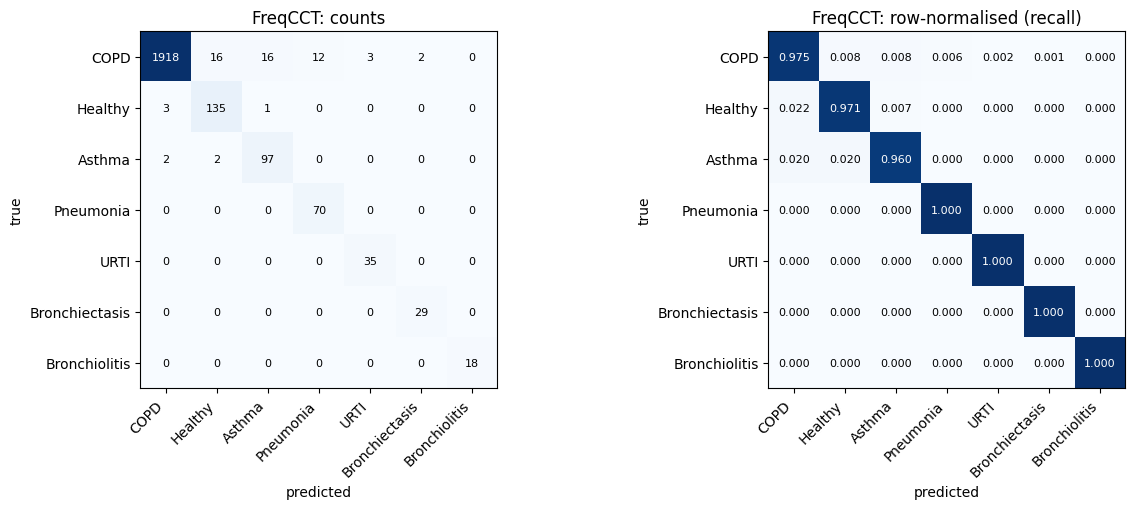

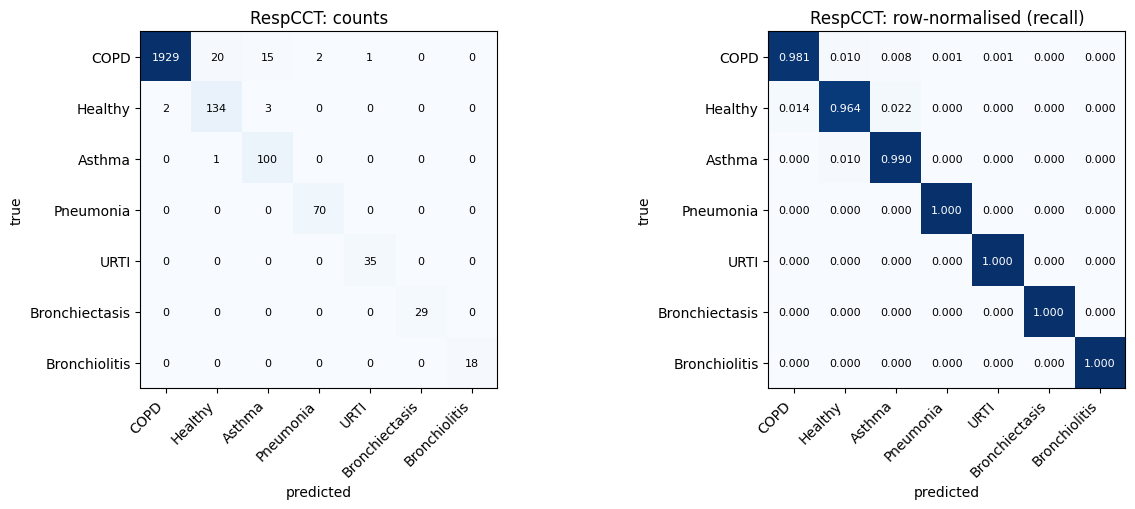

In [21]:
# 5 | Two confusion matrices: FreqCCT and CCT (RespCCT). Counts and row-normalised.
import matplotlib; import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
def save(fig, name):
    for ext in ("png", "pdf"): fig.savefig(os.path.join(OUT, "figures", f"{name}.{ext}"), dpi=200, bbox_inches="tight")
    plt.show()
def cm_plot(name):
    idx, P = preds(name); yt = y[idx]; cm = confusion_matrix(yt, P.argmax(1), labels=range(7)); cmn = cm / cm.sum(1, keepdims=True).clip(1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
    for a, mat, t, fmt in ((ax[0], cm, "counts", "d"), (ax[1], cmn, "row-normalised (recall)", ".3f")):
        a.imshow(mat, cmap="Blues"); a.set_xticks(range(7)); a.set_yticks(range(7)); a.set_xticklabels(CLASSES, rotation=45, ha="right"); a.set_yticklabels(CLASSES)
        a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{name}: {t}")
        for i in range(7):
            for j in range(7): a.text(j, i, format(mat[i, j], fmt), ha="center", va="center", fontsize=8, color="white" if mat[i, j] > mat.max() / 2 else "black")
    fig.tight_layout(); save(fig, "confusion_" + name.replace(" ", "_").replace("(", "").replace(")", "")); pd.DataFrame(cm, CLASSES, CLASSES).to_csv(os.path.join(OUT, "tables", f"confusion_{name.replace(' ', '_')}.csv"))
for n in ("FreqCCT", "RespCCT"):
    if n in REG: cm_plot(n)

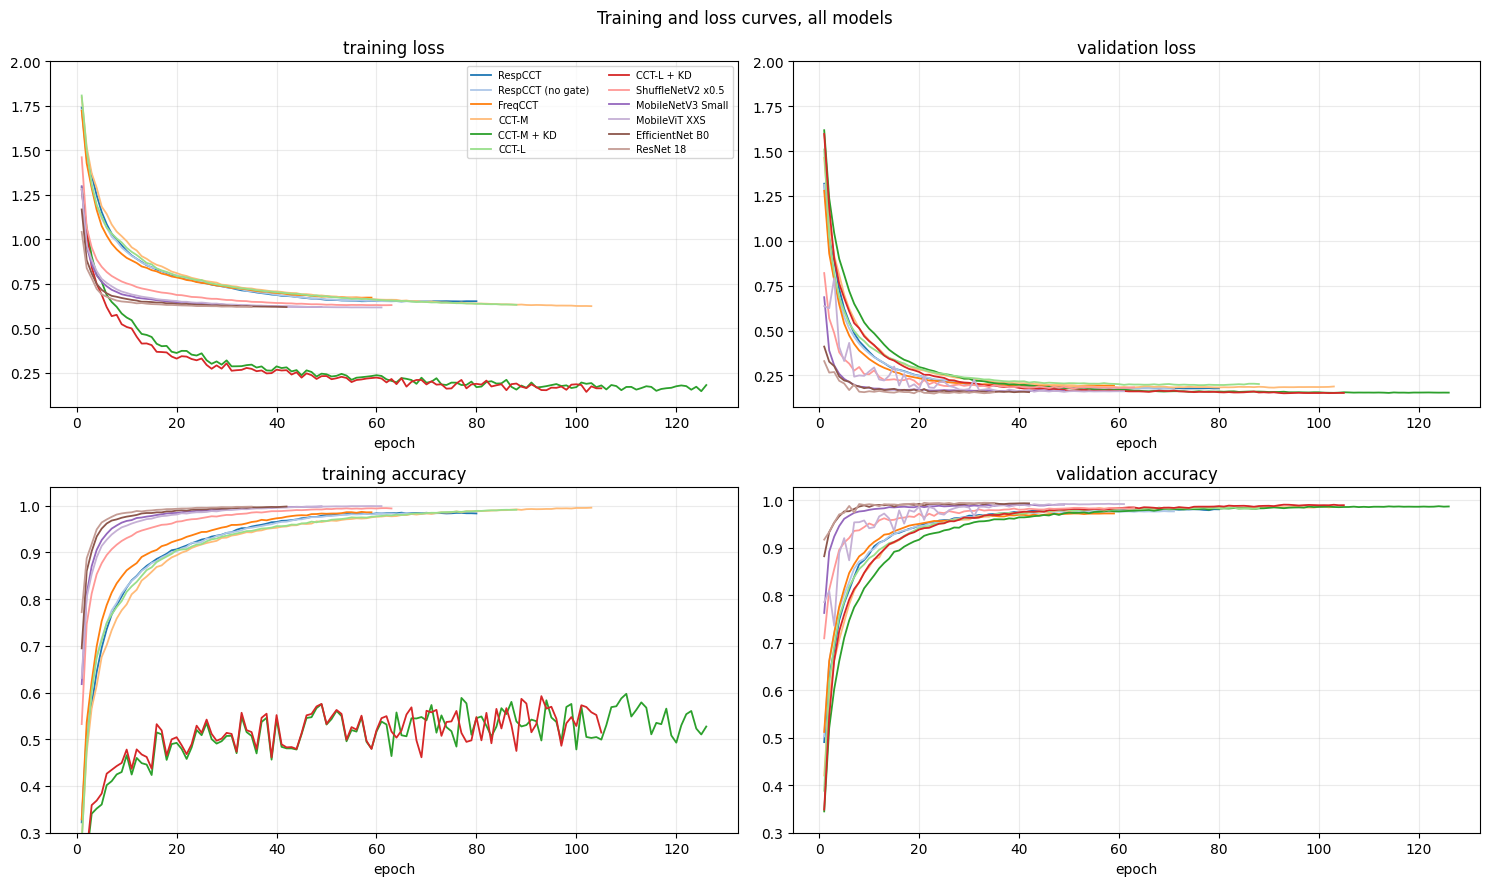

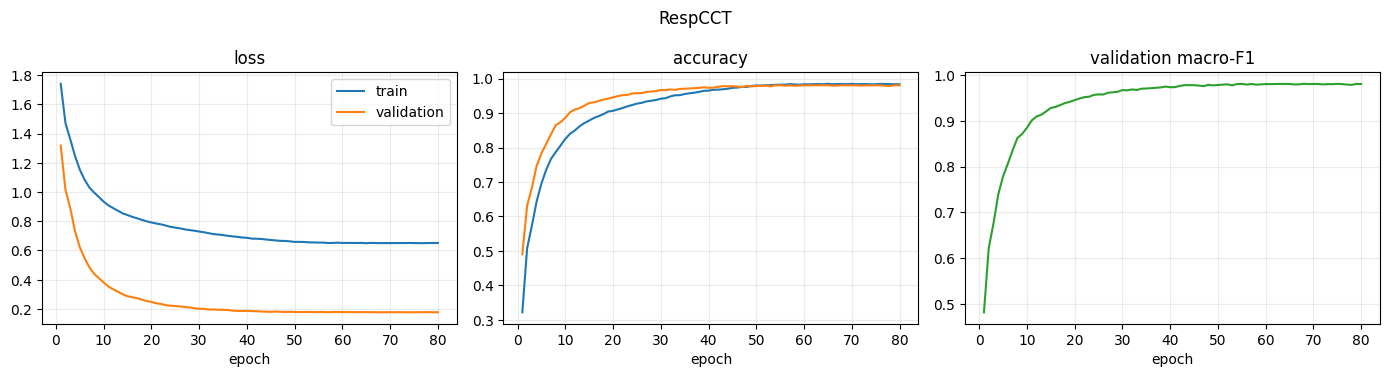

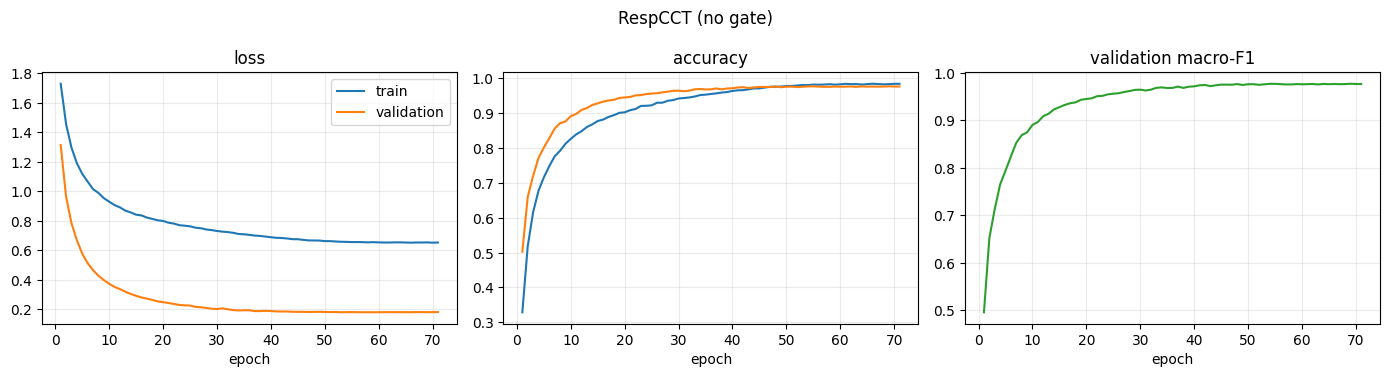

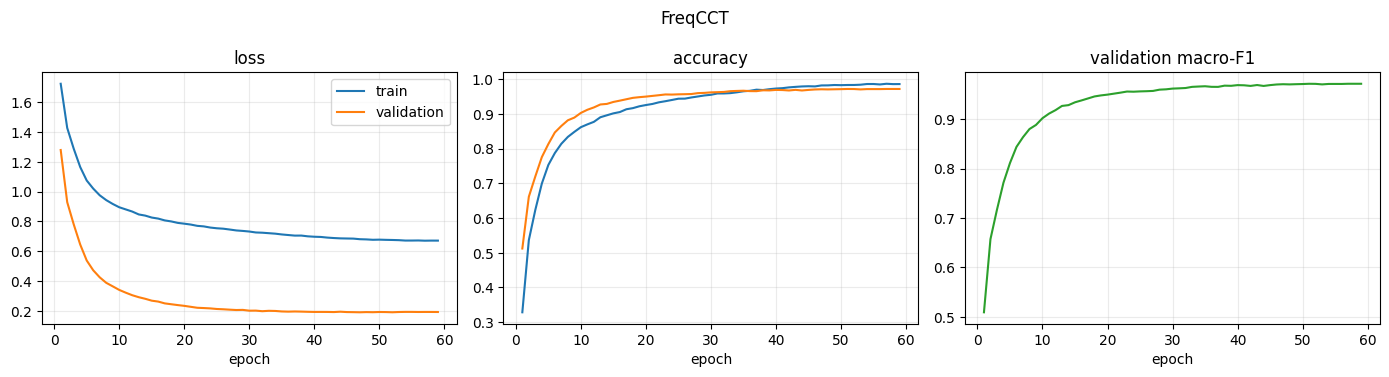

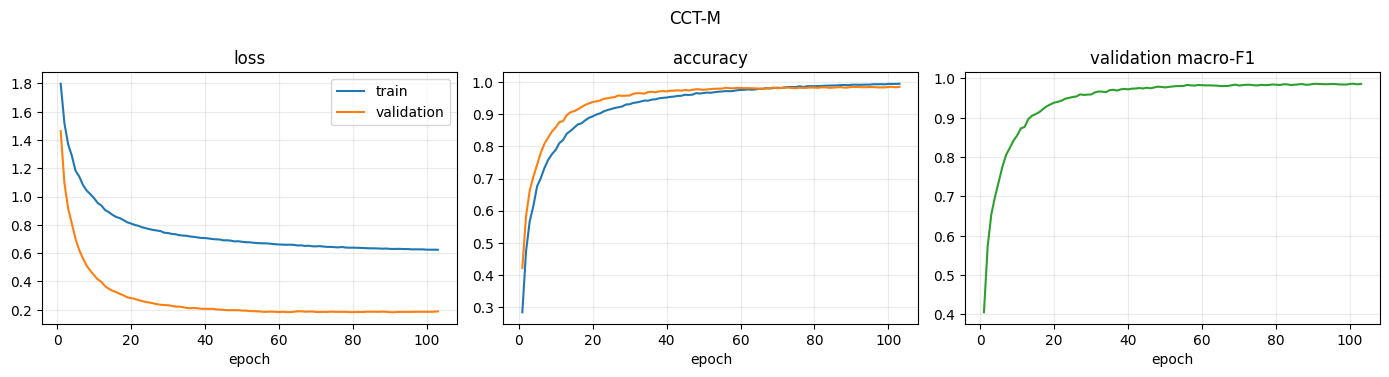

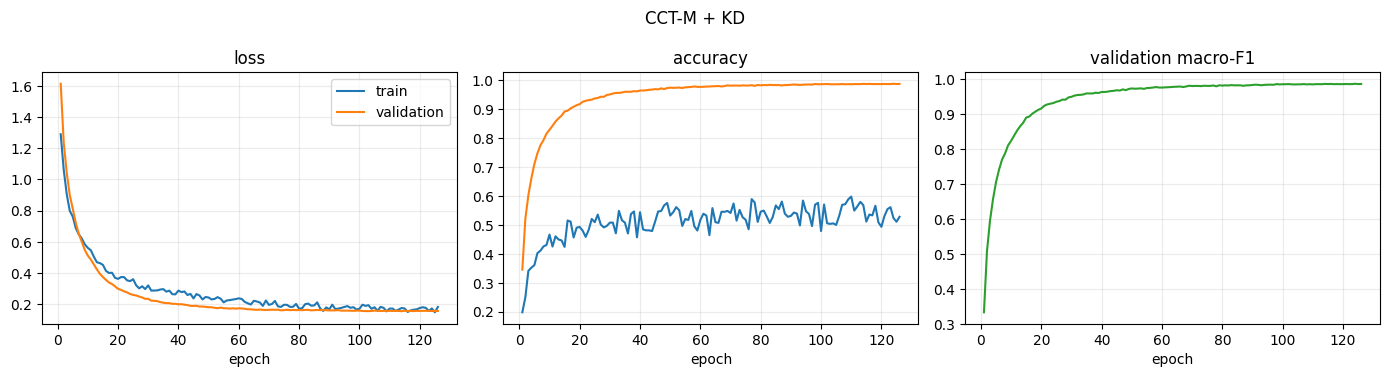

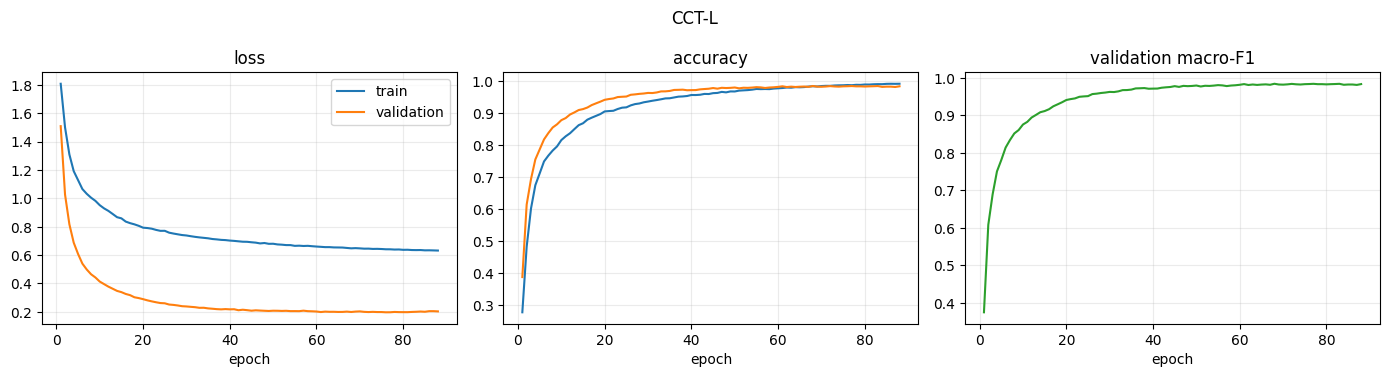

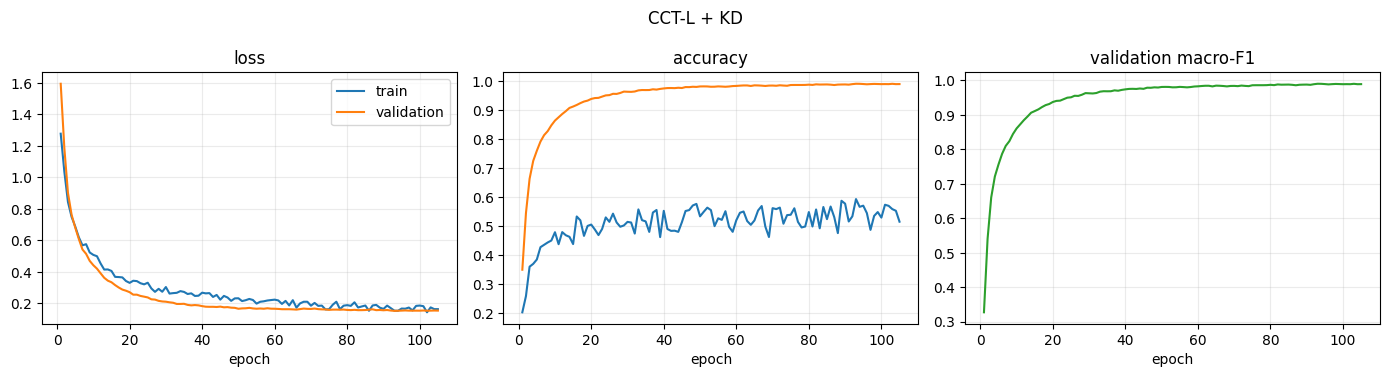

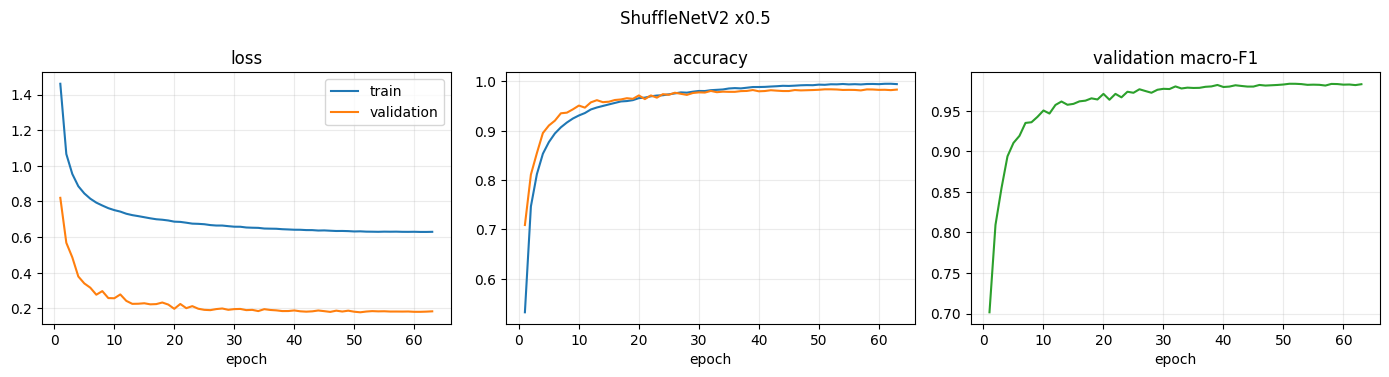

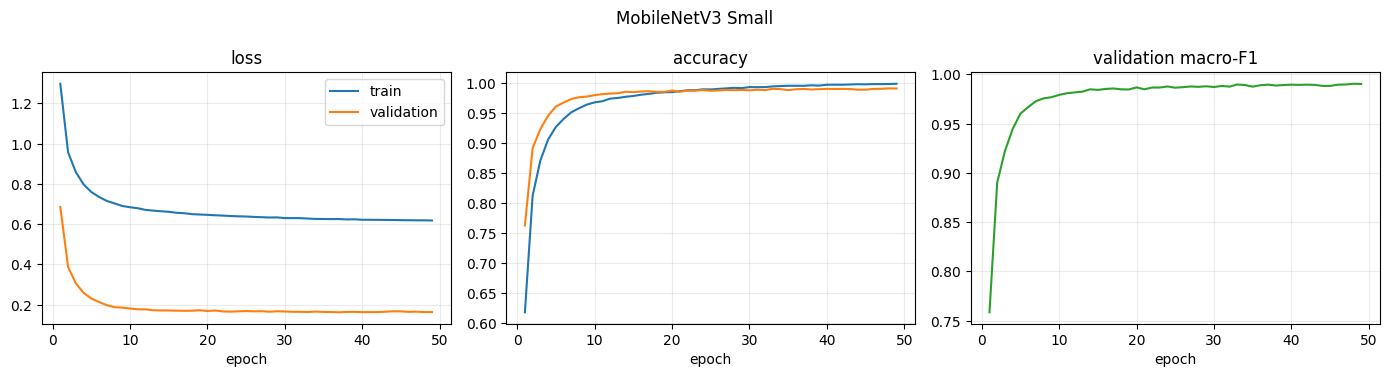

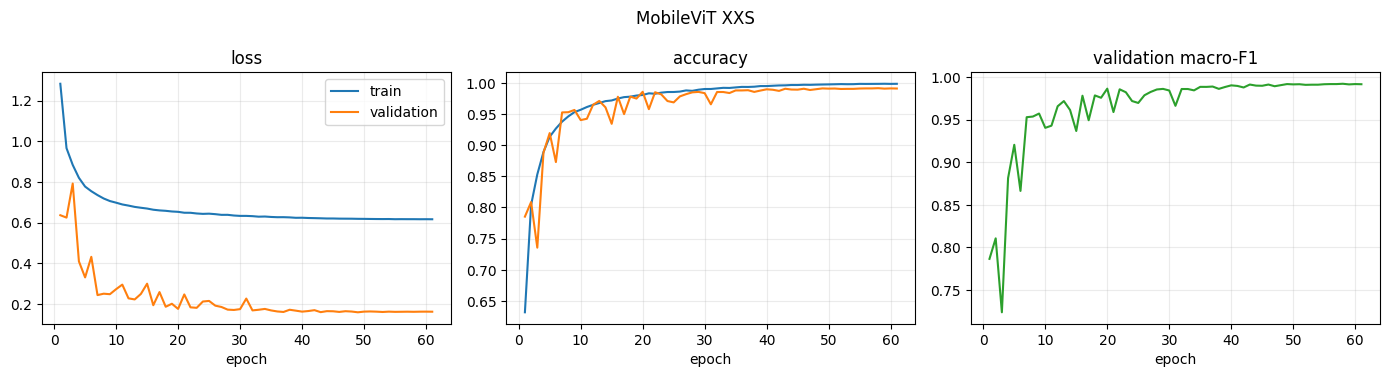

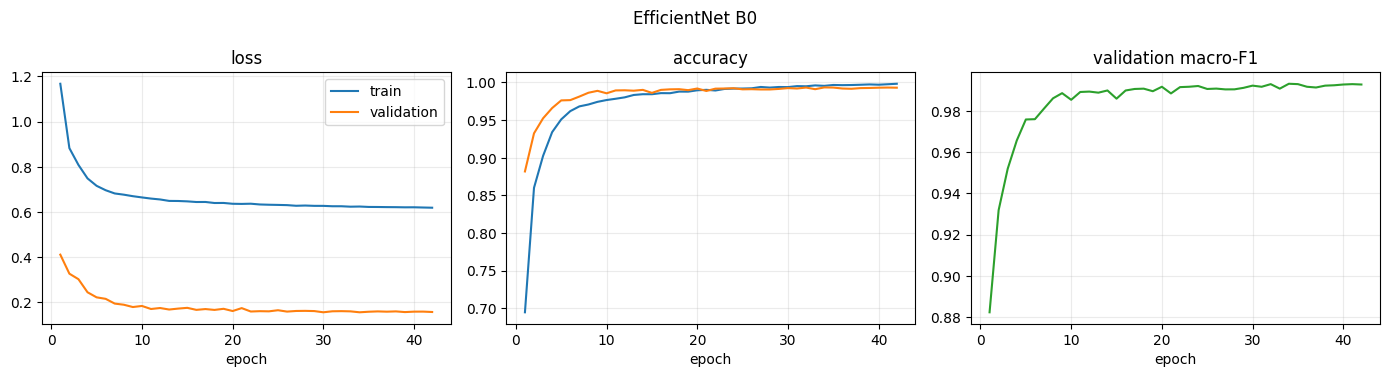

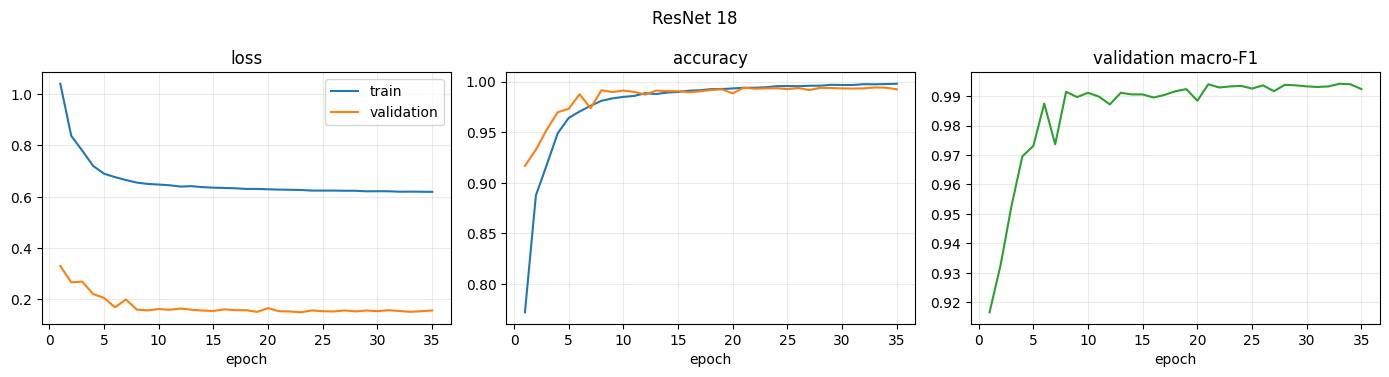

In [22]:
# 6 | Training and loss curves: (a) all models in one diagram, (b) one figure per model, with CCT-M and CCT-L (plain and KD) shown separately.
H = {n: pd.read_csv(os.path.join(TR, REG[n], "history.csv")) for n in REG}
cols = plt.get_cmap("tab20").colors
fig, ax = plt.subplots(2, 2, figsize=(15, 9)); ax = ax.ravel()
for k, (n, h) in enumerate(H.items()):
    for a, c in zip(ax, ("train_loss", "val_loss", "train_acc", "val_acc")): a.plot(h.epoch, h[c], color=cols[k % 20], label=n, lw=1.3)
for a, t in zip(ax, ("training loss", "validation loss", "training accuracy", "validation accuracy")): a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.25)
ax[0].set_ylim(top=2.0); ax[1].set_ylim(top=2.0); ax[2].set_ylim(bottom=0.3); ax[3].set_ylim(bottom=0.3); ax[0].legend(fontsize=7, ncol=2)
fig.suptitle("Training and loss curves, all models"); fig.tight_layout(); save(fig, "curves_all_models")
def one(n):
    h = H[n]; fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation"); ax[0].set_title("loss")
    ax[1].plot(h.epoch, h.train_acc, label="train"); ax[1].plot(h.epoch, h.val_acc, label="validation"); ax[1].set_title("accuracy")
    ax[2].plot(h.epoch, h.val_macro_f1, color="C2"); ax[2].set_title("validation macro-F1")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.25)
    ax[0].legend(); fig.suptitle(n); fig.tight_layout(); save(fig, "curves_" + n.replace(" ", "_").replace("+", "plus"))
for n in H: one(n)

,0
CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
Cores,1 physical / 2 logical
RAM_GB,12.7
Software,"ONNX Runtime 1.31.1, Python 3.13.18, PyTorch 2..."
Settings,"CPUExecutionProvider only, 1 thread, batch 1 (..."


/tmp/ipykernel_1622/462377092.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  try: torch.onnx.export(m, dummy, path, dynamo=False, **kw)
/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/code/bspc_lib.py:99: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if ret_emb: return out, emb
/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/code/bspc_lib.py:100: TracerWarning: Converting a tensor to a Python boole

RespCCT ok 6.458 ms


/tmp/ipykernel_1622/462377092.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  try: torch.onnx.export(m, dummy, path, dynamo=False, **kw)
/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/code/bspc_lib.py:99: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if ret_emb: return out, emb
/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/code/bspc_lib.py:100: TracerWarning: Converting a tensor to a Python boole

RespCCT (no gate) ok 3.73 ms


/tmp/ipykernel_1622/462377092.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  try: torch.onnx.export(m, dummy, path, dynamo=False, **kw)
/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/code/bspc_lib.py:146: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if ret_emb: return out, emb
/content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/code/bspc_lib.py:147: TracerWarning: Converting a tensor to a Python bool

... (12 outputs left out)

EfficientNet B0 ok 6.846 ms


/tmp/ipykernel_1622/462377092.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  try: torch.onnx.export(m, dummy, path, dynamo=False, **kw)


ResNet 18 ok 16.168 ms


,Model,Params,ONNX MB,Median ms,p99 ms,Throughput fps,Peak RAM MB,Macro F1,argmax agree,Pareto
0,RespCCT,173187,0.743,6.458,49.528,286.2,0.0,0.9695,1.0,yes
1,RespCCT (no gate),173128,0.742,3.730,6.292,286.0,8.6,0.9584,1.0,yes
2,FreqCCT,124999,0.559,3.111,20.207,381.2,8.6,0.9514,1.0,yes
3,CCT-M,967619,3.813,12.604,27.183,80.0,17.6,0.9681,1.0,
4,CCT-M + KD,967619,3.813,12.504,23.840,80.3,17.6,0.9748,1.0,yes
5,CCT-L,2151811,8.330,24.165,47.663,40.4,33.9,0.9637,1.0,
6,CCT-L + KD,2151811,8.330,24.204,46.502,40.5,33.9,0.9680,1.0,
7,MobileViT XXS,953271,3.840,7.769,18.944,246.2,2.2,0.9843,1.0,yes
8,EfficientNet B0,4016515,15.314,6.846,13.911,155.9,44.9,0.9841,1.0,yes
9,ResNet 18,11180103,42.640,16.168,28.039,66.1,111.9,0.9808,1.0,


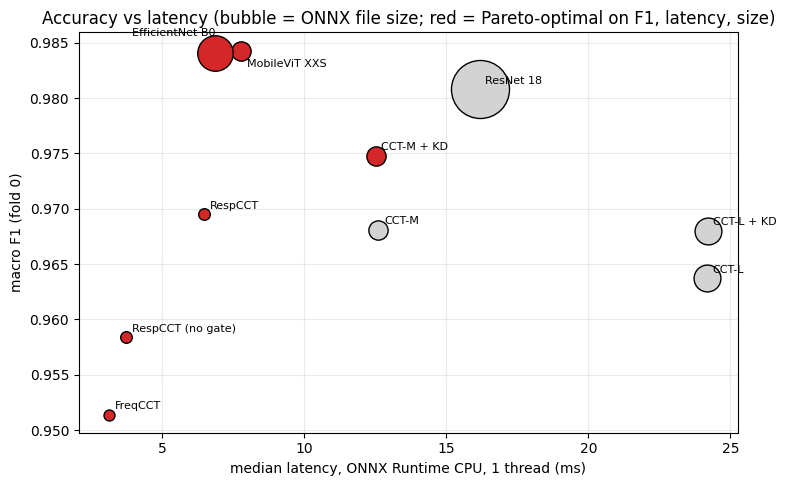

In [16]:
# 7 | ONNX Runtime, CPU only. Table A = hardware and settings. Table B = one row per model.
import onnx, onnxruntime as ort, platform, psutil, gc
# ShuffleNetV2 and MobileNetV3 are left out of this table at the authors' request. They are FASTER than the CCTs in ONNX Runtime, so say so in the paper.
EXCLUDE_ONNX = {"ShuffleNetV2 x0.5", "MobileNetV3 Small"}
THREADS, BATCH_T, WARM, RUNS, REPEATS = 1, 8, 50, 500, 3
def cpu_model():
    try:
        for l in open("/proc/cpuinfo"):
            if l.startswith("model name"): return l.split(":", 1)[1].strip()
    except Exception: pass
    return platform.processor()
TA = pd.DataFrame([dict(CPU=cpu_model(), Cores=f"{psutil.cpu_count(logical=False)} physical / {os.cpu_count()} logical", RAM_GB=round(psutil.virtual_memory().total / 2**30, 1),
        Software=f"ONNX Runtime {ort.__version__}, Python {platform.python_version()}, PyTorch {torch.__version__}",
        Settings=f"CPUExecutionProvider only, {THREADS} thread, batch 1 (latency) and {BATCH_T} (throughput), warm-up {WARM}, {RUNS} runs x {REPEATS} repeats")])
TA.to_csv(os.path.join(OUT, "tables", "onnx_table_A_hardware.csv"), index=False); display(TA.T)
real_te = te[:256]; xs = Xg[torch.as_tensor(real_te, device=device)].float().cpu().numpy()
def export(name):
    m, spec = load(name, "cpu"); path = os.path.join(OUT, "onnx", name.replace(" ", "_").replace("+", "plus") + ".onnx"); dummy = torch.zeros(1, 3, 64, 40)
    kw = dict(opset_version=17, input_names=["x"], output_names=["logits"], dynamic_axes={"x": {0: "b"}, "logits": {0: "b"}}, do_constant_folding=True)
    try: torch.onnx.export(m, dummy, path, dynamo=False, **kw)
    except TypeError: torch.onnx.export(m, dummy, path, **kw)
    return m, path
def sess(path):
    so = ort.SessionOptions(); so.intra_op_num_threads = THREADS; so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL; so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(path, so, providers=["CPUExecutionProvider"])
def bench(s, x, warm=WARM, runs=RUNS):
    for _ in range(warm): s.run(None, {"x": x})
    t = np.empty(runs)
    for i in range(runs): a = time.perf_counter_ns(); s.run(None, {"x": x}); t[i] = (time.perf_counter_ns() - a) / 1e6
    return t
proc = psutil.Process(); rows = []
for n in REG:
    if n in EXCLUDE_ONNX: continue
    try:
        m, path = export(n); idx_, P_ = preds(n); f1 = bspc.macro_f1_present(y[idx_], P_.argmax(1))
        with torch.no_grad(): ref = m(torch.from_numpy(xs)).numpy()
        gc.collect(); rss0 = proc.memory_info().rss; s1 = sess(path)
        out = np.concatenate([s1.run(None, {"x": xs[i:i + 1]})[0] for i in range(len(xs))]); agree = float((ref.argmax(1) == out.argmax(1)).mean())
        t = np.concatenate([bench(s1, xs[:1]) for _ in range(REPEATS)]); tb = np.concatenate([bench(s1, xs[:BATCH_T], 20, 100) for _ in range(REPEATS)])
        ram = (proc.memory_info().rss - rss0) / 2**20; del s1; gc.collect()
        rows.append({"Model": n, "Params": bspc.n_params(m), "ONNX MB": round(os.path.getsize(path) / 2**20, 3), "Median ms": round(float(np.median(t)), 3), "p99 ms": round(float(np.percentile(t, 99)), 3),
                     "Throughput fps": round(BATCH_T * 1000 / float(np.median(tb)), 1), "Peak RAM MB": round(ram, 1), "Macro F1": round(float(f1), 4), "argmax agree": agree})
        print(n, "ok", rows[-1]["Median ms"], "ms")
    except Exception as e: print(n, "FAILED:", repr(e)[:200])
TB = pd.DataFrame(rows)
def pareto(r, df):
    for _, o in df.iterrows():
        if o["Model"] == r["Model"]: continue
        if o["Macro F1"] >= r["Macro F1"] and o["Median ms"] <= r["Median ms"] and o["ONNX MB"] <= r["ONNX MB"] and (o["Macro F1"] > r["Macro F1"] or o["Median ms"] < r["Median ms"] or o["ONNX MB"] < r["ONNX MB"]): return False
    return True
TB["Pareto"] = ["yes" if pareto(r, TB) else "" for _, r in TB.iterrows()]
TB.to_csv(os.path.join(OUT, "tables", "onnx_table_B_models.csv"), index=False); display(TB)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for _, r in TB.iterrows():
    ax.scatter(r["Median ms"], r["Macro F1"], s=40 + 40 * r["ONNX MB"], c="tab:red" if r["Pareto"] else "lightgray", edgecolor="k", zorder=3)
    xytext = (4, 4)
    if "Mobile" in r["Model"]:
        xytext = (4, -12)
    elif "EfficientNet" in r["Model"]:
        xytext = (-60, 12)
    ax.annotate(r["Model"], (r["Median ms"], r["Macro F1"]), fontsize=8, xytext=xytext, textcoords="offset points")
ax.set_xlabel("median latency, ONNX Runtime CPU, 1 thread (ms)"); ax.set_ylabel("macro F1 (fold 0)"); ax.set_title("Accuracy vs latency (bubble = ONNX file size; red = Pareto-optimal on F1, latency, size)"); ax.grid(alpha=.25); save(fig, "onnx_pareto")

In [23]:
# 8 | XAI setup. Frames: up to 20 correctly classified real test frames per class. Background: 64 real training frames (in-distribution fill, never zeros).
rng = np.random.default_rng(0); idx_te, P_te = preds("RespCCT" if "RespCCT" in REG else list(REG)[0])
ok = [i for i, p in zip(idx_te, P_te.argmax(1)) if p == y[i]]
pick = {c: [i for i in ok if y[i] == c][:20] for c in range(7)}
real_tr = tr[M["aug"].values[tr] == 0]; bg_idx = rng.choice(real_tr, 64, replace=False)
BG = Xg[torch.as_tensor(bg_idx, device=device)].float()
ROWS_HZ = bspc.token_row_hz(16) if hasattr(bspc, "token_row_hz") else np.arange(16)
def prob_fn(model):
    def f(x):
        with torch.no_grad(): return F.softmax(model(x.float().to(device)), 1)
    return f
def mean_over_class(maps):  # dict class -> list of (16,10) maps
    return {c: np.mean(v, 0) for c, v in maps.items() if len(v)}
def class_corr(maps_mean, name):
    prof = {c: m.mean(1) for c, m in maps_mean.items()}; C = np.corrcoef(np.array([prof[c] for c in sorted(prof)]))
    print(name, "mean off-diagonal correlation of per-class band profiles:", round((C.sum() - len(C)) / (len(C) ** 2 - len(C)), 3), "(near 1 = not class-specific)")
def draw(maps_mean, title, fname):
    fig, ax = plt.subplots(2, 4, figsize=(15, 6.5)); ax = ax.ravel()
    for c in range(7):
        if c in maps_mean:
            m = maps_mean[c]; v = np.abs(m).max() + 1e-9; ax[c].imshow(m, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-v, vmax=v)
        ax[c].set_title(CLASSES[c]); ax[c].set_xlabel("time token"); ax[c].set_ylabel("frequency token row")
    ax[7].axis("off"); fig.suptitle(title); fig.tight_layout(); save(fig, fname)

PermutationExplainer explainer: 2it [00:19, 19.15s/it]               
PermutationExplainer explainer: 2it [00:20, 20.44s/it]               
PermutationExplainer explainer: 2it [00:20, 20.09s/it]               
PermutationExplainer explainer: 2it [00:19, 19.88s/it]               
PermutationExplainer explainer: 2it [00:18, 18.95s/it]               
PermutationExplainer explainer: 2it [00:18, 18.94s/it]               
PermutationExplainer explainer: 2it [00:20, 20.90s/it]               
PermutationExplainer explainer: 2it [00:19, 19.03s/it]               
PermutationExplainer explainer: 2it [00:19, 19.27s/it]               
PermutationExplainer explainer: 2it [00:19, 19.36s/it]               
PermutationExplainer explainer: 2it [00:20, 20.60s/it]               
PermutationExplainer explainer: 2it [00:18, 18.86s/it]               
PermutationExplainer explainer: 2it [00:18, 18.86s/it]               
PermutationExplainer explainer: 2it [00:19, 19.79s/it]               
PermutationExplainer

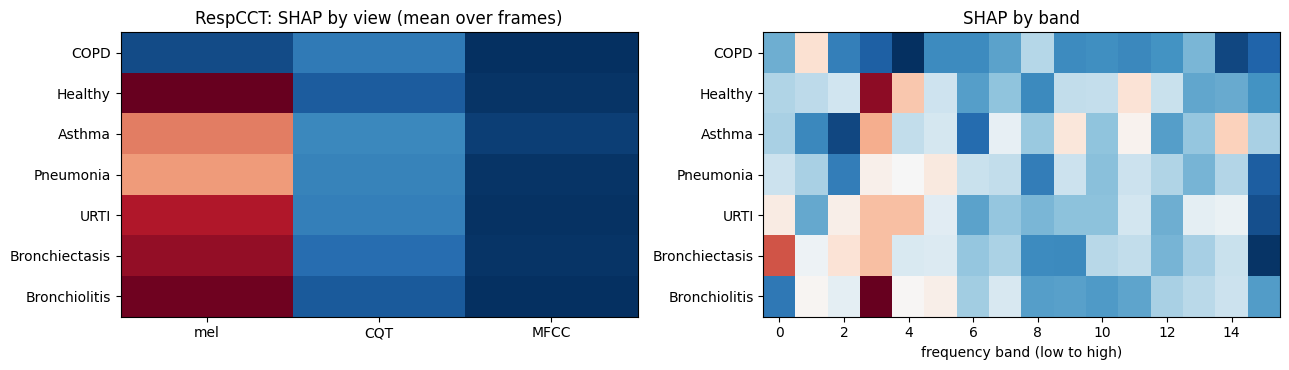

RespCCT SHAP mean off-diagonal correlation of per-class band profiles: 0.277 (near 1 = not class-specific)


PermutationExplainer explainer: 2it [00:17, 17.14s/it]               
PermutationExplainer explainer: 2it [00:17, 17.04s/it]               
PermutationExplainer explainer: 2it [00:17, 17.08s/it]               
PermutationExplainer explainer: 2it [00:17, 17.54s/it]               
PermutationExplainer explainer: 2it [00:26, 26.27s/it]               
PermutationExplainer explainer: 2it [00:17, 17.07s/it]               
PermutationExplainer explainer: 2it [00:16, 16.98s/it]               
PermutationExplainer explainer: 2it [00:17, 17.96s/it]               
PermutationExplainer explainer: 2it [00:17, 17.91s/it]               
PermutationExplainer explainer: 2it [00:16, 16.92s/it]               
PermutationExplainer explainer: 2it [00:17, 17.05s/it]               
PermutationExplainer explainer: 2it [00:16, 16.95s/it]               
PermutationExplainer explainer: 2it [00:17, 17.04s/it]               
PermutationExplainer explainer: 2it [00:17, 17.44s/it]               
PermutationExplainer

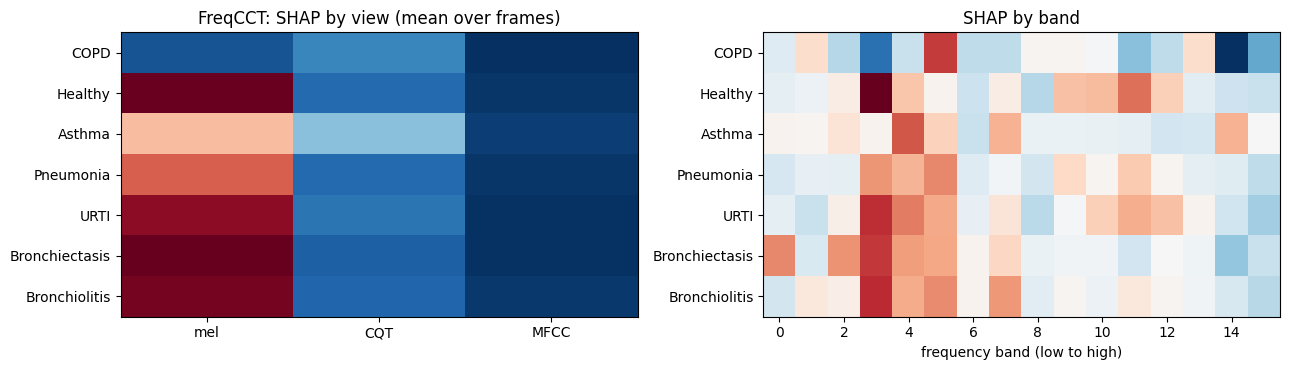

FreqCCT SHAP mean off-diagonal correlation of per-class band profiles: 0.39 (near 1 = not class-specific)


In [24]:
# 9 | XAI 1: SHAP (shap library, PermutationExplainer) on 48 groups = 3 views x 16 frequency bands. Masked groups are filled from a real background frame.
import shap
def shap_maps(name, n_per_class=8, n_bg=6, max_evals=400):
    model, _ = load(name, device); f = prob_fn(model); out = {c: [] for c in range(7)}
    for c in range(7):
        for i in pick[c][:n_per_class]:
            x = Xg[i].float()
            def g(Z, x=x, c=c):
                Z = np.asarray(Z, dtype=np.float32); res = np.zeros(len(Z))
                for b0 in range(0, len(Z), 32):
                    z = torch.from_numpy(Z[b0:b0 + 32]).to(device).view(-1, 3, 16)
                    z = z[:, :, :, None].repeat_interleave(4, 2).expand(-1, 3, 64, 40)           # (b,3,64,40) keep-mask: 4 rows per band
                    acc = 0
                    for k in range(n_bg):
                        bg = BG[(k * 7) % len(BG)][None]; acc = acc + f(z * x[None] + (1 - z) * bg)[:, c]
                    res[b0:b0 + 32] = (acc / n_bg).cpu().numpy()
                return res
            expl = shap.PermutationExplainer(g, shap.maskers.Independent(np.zeros((1, 48))), seed=0)
            sv = expl(np.ones((1, 48)), max_evals=max_evals).values[0].reshape(3, 16); out[c].append(sv)
    return out
SHAP = {}
for n in [k for k in ("RespCCT", "FreqCCT") if k in REG]:
    S = shap_maps(n); SHAP[n] = S
    mean = {c: np.mean(v, 0) for c, v in S.items() if v}                                          # (3,16): view x band
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    ax[0].imshow(np.array([mean[c].sum(1) for c in sorted(mean)]), cmap="RdBu_r", aspect="auto"); ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["mel", "CQT", "MFCC"]); ax[0].set_yticks(range(len(mean))); ax[0].set_yticklabels([CLASSES[c] for c in sorted(mean)]); ax[0].set_title(f"{n}: SHAP by view (mean over frames)")
    ax[1].imshow(np.array([mean[c].sum(0) for c in sorted(mean)]), cmap="RdBu_r", aspect="auto"); ax[1].set_xlabel("frequency band (low to high)"); ax[1].set_yticks(range(len(mean))); ax[1].set_yticklabels([CLASSES[c] for c in sorted(mean)]); ax[1].set_title("SHAP by band")
    fig.tight_layout(); save(fig, f"xai_shap_{n.replace(' ', '_')}")
    class_corr({c: np.stack([v.sum(0)] * 10, 1) for c, v in mean.items()}, f"{n} SHAP")
    pd.DataFrame([dict(model=n, cls=CLASSES[c], view=["mel", "CQT", "MFCC"][v], **{f"band{b}": float(mean[c][v, b]) for b in range(16)}) for c in mean for v in range(3)]).to_csv(os.path.join(OUT, "tables", f"xai_shap_{n.replace(' ', '_')}.csv"), index=False)

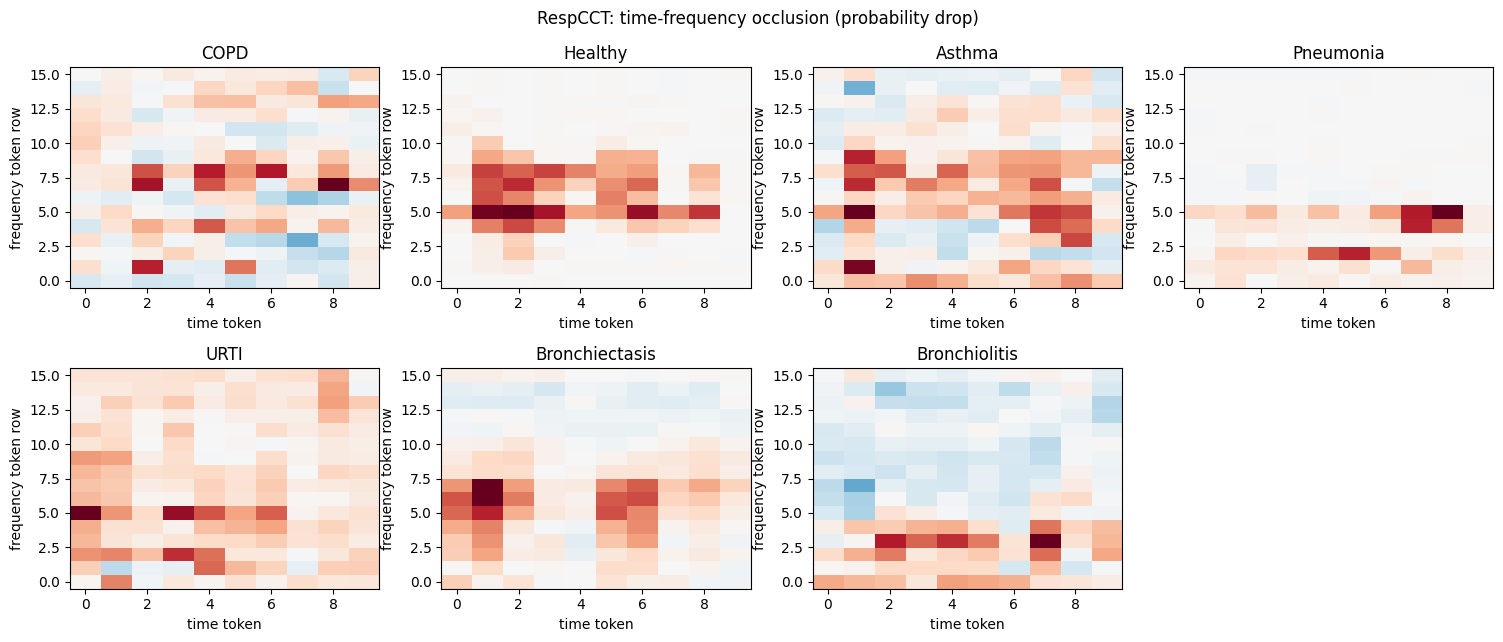

RespCCT occlusion mean off-diagonal correlation of per-class band profiles: 0.292 (near 1 = not class-specific)


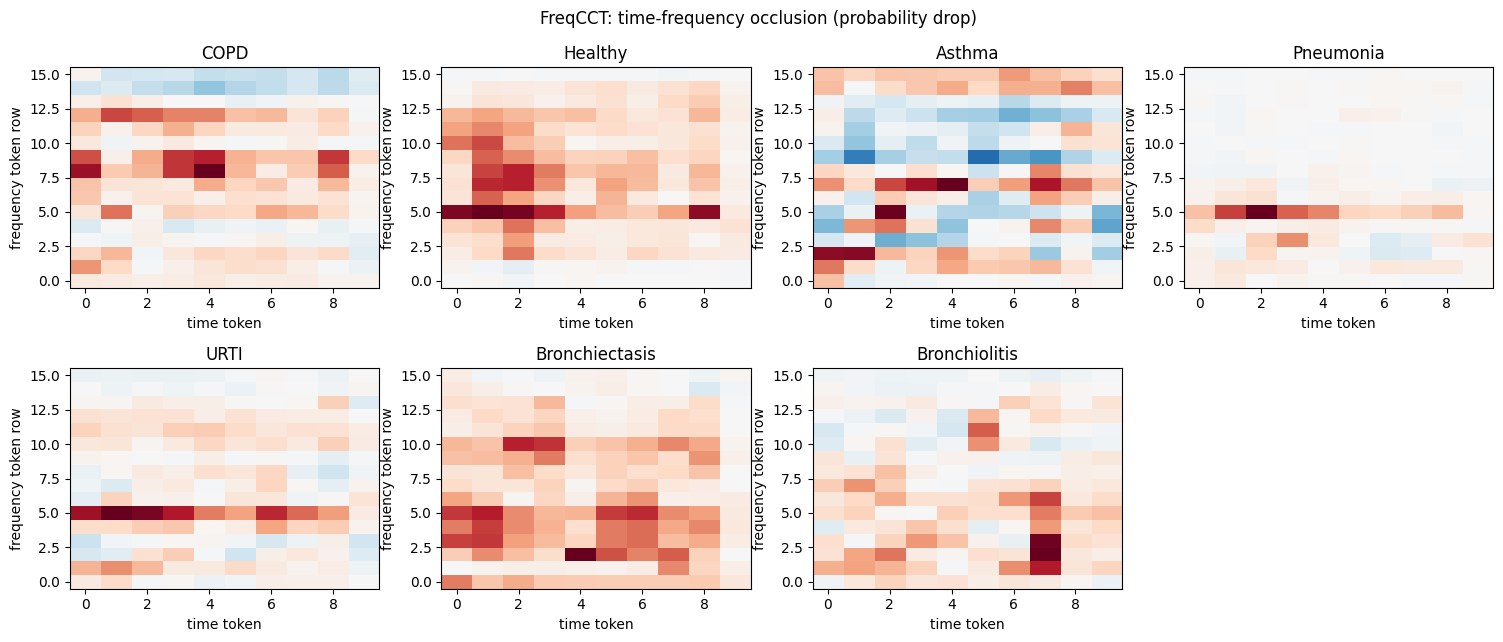

FreqCCT occlusion mean off-diagonal correlation of per-class band profiles: 0.223 (near 1 = not class-specific)


In [25]:
# 10 | XAI 2: time-frequency occlusion with in-distribution fill. One 4x4 token (all 3 views) is replaced by the per-pixel median of real training frames; importance = drop in the class probability.
MED = BG.median(0).values
def occlusion_maps(name, n_per_class=10):
    model, _ = load(name, device); f = prob_fn(model); out = {c: [] for c in range(7)}
    for c in range(7):
        for i in pick[c][:n_per_class]:
            x = Xg[i].float(); base = f(x[None])[0, c]; xs_ = x[None].repeat(160, 1, 1, 1); k = 0
            for a in range(16):
                for b in range(10): xs_[k, :, 4 * a:4 * a + 4, 4 * b:4 * b + 4] = MED[:, 4 * a:4 * a + 4, 4 * b:4 * b + 4]; k += 1
            drop = (base - f(xs_)[:, c]).cpu().numpy().reshape(16, 10); out[c].append(drop)
    return out
OCC = {}
for n in [k for k in ("RespCCT", "FreqCCT") if k in REG]:
    OCC[n] = occlusion_maps(n); mm = mean_over_class(OCC[n]); draw(mm, f"{n}: time-frequency occlusion (probability drop)", f"xai_occlusion_{n.replace(' ', '_')}"); class_corr(mm, f"{n} occlusion")

In [ ]:
# 11 | XAI 3: attention rollout from the authors' own library (CCT models only; read-out weighted by the predicted class is not used here, so this map is class-agnostic by design).
ROLL = {}
for n in [k for k in ("RespCCT", "CCT-M", "CCT-L") if k in REG]:
    try:
        model, _ = load(n, device); out = {c: [] for c in range(7)}
        for c in range(7):
            for i in pick[c][:10]: out[c].append(bspc.rollout_map(model, Xg[i].float()[None])[0].cpu().numpy())
        ROLL[n] = out; draw(mean_over_class(out), f"{n}: attention rollout", f"xai_rollout_{n.replace(' ', '_')}"); class_corr(mean_over_class(out), f"{n} rollout")
    except Exception as e: print(n, "rollout skipped:", repr(e)[:150])

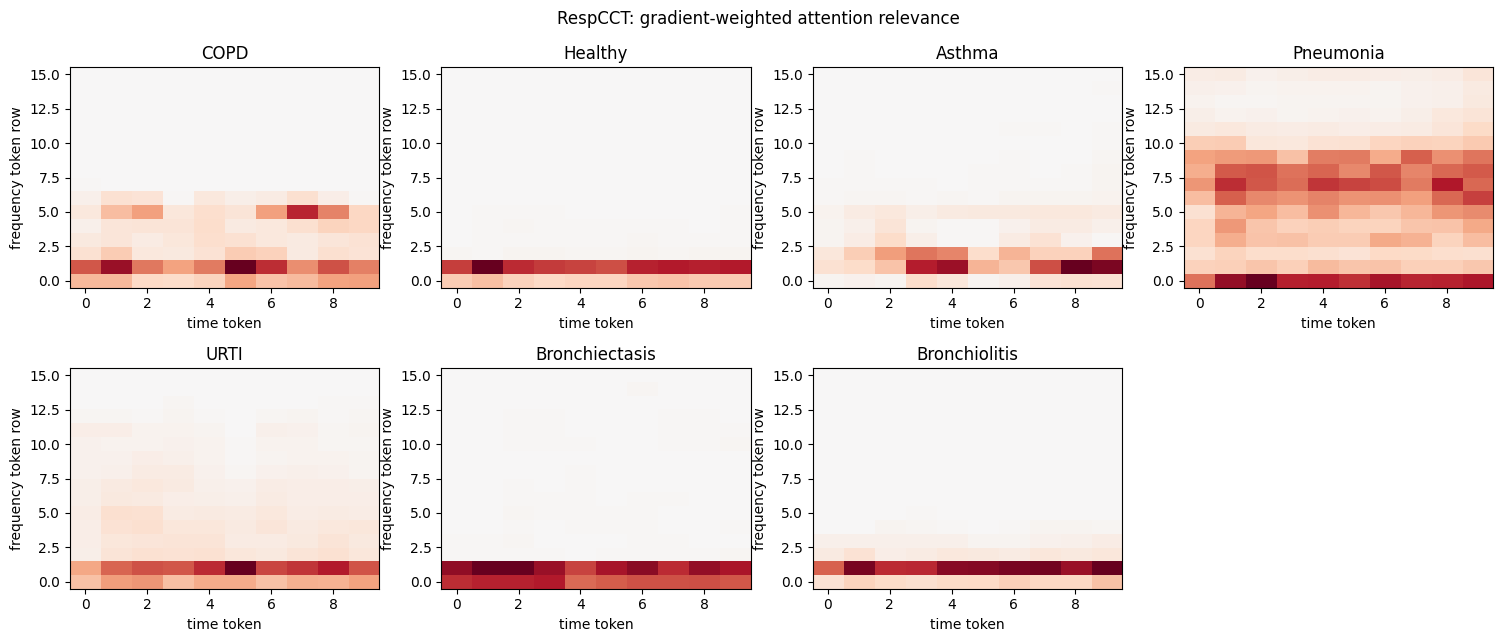

RespCCT attention relevance mean off-diagonal correlation of per-class band profiles: 0.683 (near 1 = not class-specific)


In [27]:
# 11b | XAI 4: gradient-weighted attention relevance (head-averaged variant of Chefer et al. 2021). CCT models only. Class-specific, unlike plain rollout.
def chefer_map(model, x, c):
    for b in model.blocks: b.keep_attn = True
    try:
        out, w = model(x[None].clone(), ret_pool=True)
        attn = [b.last_attn for b in model.blocks]
        grads = torch.autograd.grad(out[0, c], attn, allow_unused=True)
        n = attn[0].shape[-1]; R = torch.eye(n, device=x.device)[None]
        for A, G in zip(attn, grads):
            if G is None:
                G = torch.zeros_like(A)
            R = R + (G * A).clamp(min=0) @ R
        tok = (w[:, None, :] @ R)[0, 0]
    finally:
        for b in model.blocks: b.keep_attn = False
    return tok.detach().view(model.nf, model.nt).cpu().numpy()
CHE = {}
if "RespCCT" in REG:
    mdl, _ = load("RespCCT", device); CHE = {c: [chefer_map(mdl, Xg[i].float(), c) for i in pick[c][:10]] for c in range(7)}
    draw(mean_over_class(CHE), "RespCCT: gradient-weighted attention relevance", "xai_chefer_RespCCT"); class_corr(mean_over_class(CHE), "RespCCT attention relevance")

In [ ]:
# 12 | Top-4 XAI methods merged: one figure per class (RespCCT). Each map is clipped at 0 and scaled to [0,1]; the last panel is the mean of the four (agreement).
from scipy.stats import spearmanr
def nrm(m): m = np.clip(m, 0, None); return m / (m.max() + 1e-9)
agree = []
for c in range(7):
    if not (pick[c] and CHE and "RespCCT" in SHAP and "RespCCT" in OCC and "RespCCT" in ROLL): continue
    band = np.mean(SHAP["RespCCT"][c], 0).sum(0)
    maps = {"Occlusion": np.mean(OCC["RespCCT"][c], 0), "Attention relevance": np.mean(CHE[c], 0), "SHAP (band)": np.repeat(band[:, None], 10, 1), "Attention rollout": np.mean(ROLL["RespCCT"][c], 0)}
    nm = {k: nrm(v) for k, v in maps.items()}; cons = np.mean(list(nm.values()), 0); x = Xg[pick[c][0]].float().cpu().numpy()
    fig, ax = plt.subplots(1, 6, figsize=(19, 3.4))
    ax[0].imshow(x[0], origin="lower", aspect="auto", cmap="magma"); ax[0].set_title(f"{CLASSES[c]}: input (mel)")
    for a, (k, v) in zip(ax[1:5], nm.items()): a.imshow(v, origin="lower", aspect="auto", cmap="inferno", vmin=0, vmax=1); a.set_title(k)
    ax[5].imshow(cons, origin="lower", aspect="auto", cmap="inferno", vmin=0, vmax=1); ax[5].set_title("Agreement (mean of four)")
    ax[0].set_ylabel("frequency (low to high)"); fig.tight_layout(); save(fig, f"xai_merged_{CLASSES[c]}")
    ks = list(nm); agree.append(dict(cls=CLASSES[c], **{f"{a} vs {b}": round(float(spearmanr(nm[a].ravel(), nm[b].ravel())[0]), 3) for i, a in enumerate(ks) for b in ks[i + 1:]}))
if agree: AG = pd.DataFrame(agree); AG.to_csv(os.path.join(OUT, "tables", "xai_agreement_spearman.csv"), index=False); display(AG)

In [29]:
# 13 | Summary
print("Done. Everything is in:", OUT)
for d in ("figures", "tables", "onnx"): print(d, ":", sorted(os.listdir(os.path.join(OUT, d)))[:60])

Done. Everything is in: /content/drive/MyDrive/Data/RespCCT_BSPC/runs/run_20261022_070616/colab_outputs
figures : ['confusion_FreqCCT.pdf', 'confusion_FreqCCT.png', 'confusion_RespCCT.pdf', 'confusion_RespCCT.png', 'curves_CCT-L.pdf', 'curves_CCT-L.png', 'curves_CCT-L_plus_KD.pdf', 'curves_CCT-L_plus_KD.png', 'curves_CCT-M.pdf', 'curves_CCT-M.png', 'curves_CCT-M_plus_KD.pdf', 'curves_CCT-M_plus_KD.png', 'curves_EfficientNet_B0.pdf', 'curves_EfficientNet_B0.png', 'curves_FreqCCT.pdf', 'curves_FreqCCT.png', 'curves_MobileNetV3_Small.pdf', 'curves_MobileNetV3_Small.png', 'curves_MobileViT_XXS.pdf', 'curves_MobileViT_XXS.png', 'curves_ResNet_18.pdf', 'curves_ResNet_18.png', 'curves_RespCCT.pdf', 'curves_RespCCT.png', 'curves_RespCCT_(no_gate).pdf', 'curves_RespCCT_(no_gate).png', 'curves_ShuffleNetV2_x0.5.pdf', 'curves_ShuffleNetV2_x0.5.png', 'curves_all_models.pdf', 'curves_all_models.png', 'natural_vs_coded_Asthma.pdf', 'natural_vs_coded_Asthma.png', 'natural_vs_coded_Bronchiectasis.pdf'